In [1]:
# Block 01 — Environment, Paths, Harness & Session Guard
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : none (first block of every session)
#
# PHASE B — WITH AUGMENTATION (results kept separate from Phase A)
#   Phase A (no augmentation) is final: C1_person 38.70 ± 0.09 (5 seeds) —
#   above Xenos et al. (38.52), below EmotiCon+CCIM (39.13). Phase A also
#   showed (i) every configuration saturating at test-like val ≈ 42.5 within
#   5–7 epochs (memorisation of fixed inputs) and (ii) that seeds started from
#   one shared initialisation lose their ensemble diversity (+0.10 vs +0.50).
#   Phase B therefore:
#     * trains on 2 cached, label-preserving views per person: the original
#       and an AUGMENTED view (mirror image + a context crop that always keeps
#       the whole person + mild brightness/contrast/saturation — no hue
#       change, no rotation, no erasing, no mixing of persons); the red box is
#       drawn after the transform; mirrored views get left/right-swapped text
#     * caches the image stream at EVA layer L−2 so the encoder's top two
#       layers can be trained (or kept frozen) inside the model
#     * trains 12 epochs (cosine), every seed from its own initialisation
#     * scores val and test in the original AND the mirror view; mirror
#       test-time averaging is used only if test-like validation says so
#
# DISK (why 2 views and 8 bits)
#   A Kaggle session has ~57 GB of disk IN TOTAL (the Disk meter in the
#   notebook's side panel) — although `df` reports ~1 TB. Four fp16 views
#   per person needed ~125 GB and the session was stopped. Phase B now caches
#   2 views per person in 8 bits (~33 GB) and Block 07 refuses to start if
#   the planned cache + /kaggle/working (20 GB) + a safety margin would not fit.
#   Runs live in /kaggle/working/runs_phaseB/. Downloads go to the scratch disk
#   and the 10 GB model checkpoint is deleted again once it is in memory.
# ══════════════════════════════════════════════════════════════════════════════

import os, sys, gc, json, glob, time, math, random, shutil, warnings, subprocess, logging
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
# Model downloads (the InstructBLIP checkpoint shards, ~10 GB) go to the large
# scratch disk, not the container's root filesystem.
if Path("/kaggle/temp").is_dir() and os.environ.get("EMOTIC_TEST_MODE") != "1":
    os.environ.setdefault("HF_HOME", "/kaggle/temp/hf_home")
for _lg in ("transformers", "accelerate", "torch", "huggingface_hub", "filelock",
            "PIL", "urllib3", "h5py", "timm", "datasets", "matplotlib"):
    logging.getLogger(_lg).setLevel(logging.ERROR)

import numpy as np
import torch

_G, _R, _Y, _B, _D, _0 = ("\033[92m", "\033[91m", "\033[93m",
                          "\033[94m", "\033[90m", "\033[0m")

# ──────────────────────────────────────────────────────────────────────────────
# 1.0  SESSION CLOCK
# ──────────────────────────────────────────────────────────────────────────────
SESSION_BUDGET_H = float(os.environ.get("EMOTIC_SESSION_BUDGET_H", "11.5"))
EVAL_RESERVE_MIN = 30.0          # kept free after training for Blocks 09-10
_MARKER = Path("/tmp/emotic_session_start.txt")


def _session_start():
    now = time.time()
    cands = {"now": now}
    try:
        import psutil
        cands["kernel process"] = psutil.Process(os.getpid()).create_time()
    except Exception:
        pass
    try:
        cands["marker (/tmp)"] = float(_MARKER.read_text().strip())
    except Exception:
        pass
    valid = {k: v for k, v in cands.items() if now - 13 * 3600 < v <= now}
    start = min(valid.values())
    try:
        if not _MARKER.exists():
            _MARKER.write_text(f"{start:.3f}")
    except Exception:
        pass
    return start, cands


SESSION_START, _SESSION_CANDIDATES = _session_start()


class SessionGuard:
    """Wall-clock budget for the whole Kaggle session."""

    def __init__(self, start, budget_h, reserve_min):
        self.start, self.budget_s, self.reserve_s = start, budget_h * 3600.0, reserve_min * 60.0

    def elapsed_s(self):
        return time.time() - self.start

    def remaining_s(self):
        return max(0.0, self.budget_s - self.elapsed_s())

    def remaining_h(self):
        return self.remaining_s() / 3600.0

    def training_deadline(self):
        """Absolute unix time by which training workers must have paused."""
        return self.start + self.budget_s - self.reserve_s

    def training_remaining_s(self):
        return max(0.0, self.training_deadline() - time.time())

    def footer(self):
        return (f"session left {self.remaining_h():.2f} h | "
                f"elapsed {self.elapsed_s() / 3600:.2f} h")


GUARD = SessionGuard(SESSION_START, SESSION_BUDGET_H, EVAL_RESERVE_MIN)


# ──────────────────────────────────────────────────────────────────────────────
# VERDICT HARNESS (used by every block)
# ──────────────────────────────────────────────────────────────────────────────
def rule(ch="─", w=76):
    print(ch * w)


def header(title, w=76):
    print("\n" + "═" * w)
    print(f"  {title}")
    print("═" * w + "\n")


class BlockVerdict:
    """Per-block check collector. Green = as expected, red = not, yellow = warning."""

    def __init__(self, number, name):
        self.number, self.name, self.rows, self.t0 = number, name, [], time.time()

    def check(self, label, ok, got="", expected="", fatal=True):
        ok = bool(ok)
        self.rows.append((label, ok, fatal))
        mark = f"{_G}✓{_0}" if ok else (f"{_R}✗{_0}" if fatal else f"{_Y}!{_0}")
        detail = (f"{_D}got {got}, expected {expected}{_0}"
                  if (got != "" or expected != "") else "")
        print(f"  {mark} {label:<50s} {detail}")
        return ok

    def note(self, label, value=""):
        print(f"  {_B}·{_0} {label}" + (f": {value}" if value != "" else ""))

    def finish(self):
        header(f"{self.number}.9  VERDICT")
        for label, ok, fatal in self.rows:
            mark = f"{_G}✓{_0}" if ok else (f"{_R}✗{_0}" if fatal else f"{_Y}!{_0}")
            print(f"  {mark} {label}")
        hard = [r for r in self.rows if not r[1] and r[2]]
        n, bar = len(self.rows), "█" * 76
        print()
        tag = f"{self.number:02d}" if isinstance(self.number, int) else str(self.number)
        if hard:
            msg = f"█  BLOCK {tag}: {len(hard)} OF {n} CHECKS FAILED"
            print(f"{_R}{bar}\n{msg}{' ' * max(1, 75 - len(msg))}█\n{bar}{_0}")
        else:
            msg = f"█  BLOCK {tag}: ALL {n} CHECKS PASSED"
            print(f"{_G}{bar}\n{msg}{' ' * max(1, 75 - len(msg))}█\n{bar}{_0}")
        allv = {}
        if VERDICTS_PATH.exists():
            try:
                allv = json.loads(VERDICTS_PATH.read_text())
            except Exception:
                allv = {}
        allv[str(self.number)] = {"name": self.name, "status": "FAIL" if hard else "PASS",
                                  "checks": n, "failed": len(hard),
                                  "ts": time.strftime("%Y-%m-%d %H:%M:%S")}
        try:
            VERDICTS_PATH.write_text(json.dumps(allv, indent=2))
        except Exception:
            pass
        rule()

        def _k(kv):
            s = str(kv[0])
            return (int("".join(ch for ch in s if ch.isdigit()) or 0), s)

        seq = "  ".join(f"{k}:{_G if v['status'] == 'PASS' else _R}{v['status']}{_0}"
                        for k, v in sorted(allv.items(), key=_k))
        print(f"  VERDICT SUMMARY   {seq}")
        rule()
        print(f"  {GUARD.footer()} | block {time.time() - self.t0:.1f} s")
        return not hard


# ──────────────────────────────────────────────────────────────────────────────
# 1.1  PATHS
# ──────────────────────────────────────────────────────────────────────────────
WORK_DIR = Path(os.environ.get("EMOTIC_WORK_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
VERDICTS_PATH = WORK_DIR / "_verdicts.json"
if VERDICTS_PATH.exists():
    VERDICTS_PATH.unlink()          # fresh summary for this session

header("BLOCK 01 — Environment, Paths, Harness & Session Guard  [Phase B]")
V = BlockVerdict(1, "Setup")

print("1.0  SESSION CLOCK\n")
for _k, _v in _SESSION_CANDIDATES.items():
    V.note(f"  {_k}", time.strftime("%H:%M:%S", time.localtime(_v)))
V.note("session start used", time.strftime("%H:%M:%S", time.localtime(SESSION_START)))
V.note("budget", f"{SESSION_BUDGET_H:.1f} h total; training must pause by "
                 f"{time.strftime('%H:%M:%S', time.localtime(GUARD.training_deadline()))} "
                 f"(reserving {EVAL_RESERVE_MIN:.0f} min for evaluation)")
V.check("budget within Kaggle's 12 h limit", SESSION_BUDGET_H <= 11.75,
        f"{SESSION_BUDGET_H} h", "<= 11.75 h")
V.check("session has time left", GUARD.remaining_h() > 0.5,
        f"{GUARD.remaining_h():.2f} h", "> 0.5 h")

print("\n1.1  DEPENDENCIES\n")
import scipy, transformers, torchvision          # noqa: E401
V.note("python", sys.version.split()[0])
V.note("torch", torch.__version__)
V.note("torchvision", torchvision.__version__)
V.note("transformers", transformers.__version__)
V.note("model downloads (HF_HOME)", os.environ.get("HF_HOME", "default (~/.cache/huggingface)"))
_tfv = tuple(int(x) for x in transformers.__version__.split(".")[:2])
V.check("transformers >= 4.37", _tfv >= (4, 37), transformers.__version__, ">=4.37")
try:
    import safetensors, psutil                   # noqa: F401
    _have_deps = True
except Exception:
    _have_deps = False
V.check("safetensors + psutil importable", _have_deps, _have_deps, True)

print("\n1.2  DATASET PATHS\n")
DATA_ROOT = Path(os.environ.get("EMOTIC_DATA_ROOT",
                                "/kaggle/input/datasets/jasodhiyayadav/pami-version"))
if not DATA_ROOT.is_dir():
    for cand in sorted(glob.glob("/kaggle/input/**/emotic/emotic", recursive=True)):
        DATA_ROOT = Path(cand).parent.parent
        break
ANN_MAT = DATA_ROOT / "Annotations" / "Annotations" / "Annotations.mat"
IMG_BASE = DATA_ROOT / "emotic" / "emotic"
SOURCE_FOLDERS = ["ade20k", "emodb_small", "framesdb", "mscoco"]
DESC_PATHS = {s: DATA_ROOT / f"{s}_descriptions.json" for s in ("train", "val", "test")}

V.check("data root exists", DATA_ROOT.is_dir(), str(DATA_ROOT), "directory")
V.check("Annotations.mat exists", ANN_MAT.is_file(),
        f"{ANN_MAT.stat().st_size / 1e6:.2f} MB" if ANN_MAT.is_file() else "missing", ">1 MB")
V.check("image base exists", IMG_BASE.is_dir(), str(IMG_BASE), "directory")
_counts = {s: len(list((IMG_BASE / s / "images").glob("*.jpg")))
           for s in SOURCE_FOLDERS if (IMG_BASE / s / "images").is_dir()}
V.check("all 4 source folders present", len(_counts) == 4, len(_counts), 4)
_n_img = sum(_counts.values())
V.check("image count plausible",
        20000 <= _n_img <= 25000 or os.environ.get("EMOTIC_TEST_MODE") == "1",
        f"{_n_img:,}", "~23,185")
for s in SOURCE_FOLDERS:
    V.note(f"  {s}", f"{_counts.get(s, 0):,} images")
V.check("cached description JSONs present", all(p.is_file() for p in DESC_PATHS.values()),
        f"{sum(p.is_file() for p in DESC_PATHS.values())}/3", "3/3")

# ──────────────────────────────────────────────────────────────────────────────
# 1.3  LABEL SPACE
# ──────────────────────────────────────────────────────────────────────────────
EMOTION_LABELS = [
    "Affection", "Anger", "Annoyance", "Anticipation", "Aversion",
    "Confidence", "Disapproval", "Disconnection", "Disquietment",
    "Doubt/Confusion", "Embarrassment", "Engagement", "Esteem",
    "Excitement", "Fatigue", "Fear", "Happiness", "Pain", "Peace",
    "Pleasure", "Sadness", "Sensitivity", "Suffering", "Surprise",
    "Sympathy", "Yearning",
]
NUM_CLASSES = len(EMOTION_LABELS)
EMO2IDX = {e: i for i, e in enumerate(EMOTION_LABELS)}
VAD_DIMS = ["valence", "arousal", "dominance"]

# ──────────────────────────────────────────────────────────────────────────────
# 1.4  DIRECTORIES & GLOBAL CONFIG
# ──────────────────────────────────────────────────────────────────────────────
print("\n1.4  CONFIG\n")
CACHE_DIR = WORK_DIR / "cache"
ARRAY_DIR = CACHE_DIR / "arrays"
RUNS_DIR = WORK_DIR / "runs_phaseB"       # Phase B runs (augmentation)
OLD_RUNS_DIRS = [WORK_DIR / "runs", WORK_DIR / "runs_long", WORK_DIR / "runs_v6",
                 WORK_DIR / "runs_v7"]     # Phase A: results, scores and logs are never touched
LOG_DIR = WORK_DIR / "logs"
VIZ_DIR = WORK_DIR / "figures"
CONTROL_DIR = WORK_DIR / "control"
CORE_PATH = WORK_DIR / "emotic_core.py"
for _d in (CACHE_DIR, ARRAY_DIR, RUNS_DIR, LOG_DIR, VIZ_DIR, CONTROL_DIR):
    _d.mkdir(parents=True, exist_ok=True)


# ── EPOCHS & EARLY STOPPING ────────────────────────────────────────────────────
LR_SCHEDULE = "cosine"  # decays to 0 over MAX_EPOCHS
MAX_EPOCHS = 12         # Phase A peaked at epoch 5–7 of 8 WITHOUT augmentation; with the augmented
                        # view a person is seen in two renderings, so training runs longer
PATIENCE = 4            # stop after this many epochs without a val gain > MIN_DELTA
MIN_EPOCHS = 8          # never stop before this epoch
MIN_DELTA = 0.01        # a "gain" is > 0.01 test-like val mAP (below 2-decimal rounding)


class CFG:
    # -- data -----------------------------------------------------------------
    data_root, ann_mat, img_base, desc_paths = DATA_ROOT, ANN_MAT, IMG_BASE, DESC_PATHS
    work_dir, cache_dir, array_dir, runs_dir = WORK_DIR, CACHE_DIR, ARRAY_DIR, RUNS_DIR
    log_dir, viz_dir, control_dir, core_path = LOG_DIR, VIZ_DIR, CONTROL_DIR, CORE_PATH
    results_dir = WORK_DIR / "results" / "phaseB_augmentation"
    figures_dir = VIZ_DIR / "phaseB_augmentation"
    seed = 42

    # -- backbone (Xenos et al. footnote: instructblip-flan-t5-xl) -------------
    backbone_ckpt = os.environ.get("EMOTIC_BACKBONE", "Salesforce/instructblip-flan-t5-xl")
    vis_dim, vis_tokens, qformer_dim, num_query_tokens = 1408, 257, 768, 32
    # person crop (as Phase A): square, side = 1.2 x max(box w, h), 224 px, 2x2-pooled -> 65 tokens
    crop_margin, crop_pool = 1.2, 2
    crop_tokens = (16 // crop_pool) ** 2 + 1
    # encoder top: the image stream is cached at EVA layer L - 2; the top 2
    # layers + output LayerNorm run inside the model (frozen or trained)
    vis_top_layers = 2

    # -- inputs ---------------------------------------------------------------
    # Descriptions are kept whole (320 BERT tokens keep >97% intact); batches
    # are padded only to their own longest description.
    max_text_len = 320

    # -- Phase B: augmentation --------------------------------------------------
    augment = True
    # cached views per person: train = original + augmented (mirror + crop +
    # colour); val/test = original + pure mirror (the mirror is only used for
    # test-time averaging, and only if test-like validation shows it helps)
    views = {"train": 2, "val": 2, "test": 2}
    view_kinds = ["img", "crop"]    # context image (257 tokens) + person crop (65); no upper body (disk)
    cache_quant = "int8"            # 8-bit token cache (1.05 bytes / value instead of 2)
    aug = dict(
        zoom_area=[0.60, 1.0],      # context crop keeps 60–100% of the image area …
        zoom_aspect=[0.80, 1.25],   # … with mild aspect change (the processor resizes to 224 x 224) …
        box_margin=0.05,            # … and ALWAYS the whole person box + 5% of its size on each side
        flip_p=0.5,                 # only for extra random views (not cached by default)
        color_p=0.8, brightness=0.2, contrast=0.2, saturation=0.2,   # mild; NO hue change
        crop_margin=[1.10, 1.35], crop_shift=0.04,   # person crop jitter (whole person kept)
        ub_side=[1.0, 1.2], ub_shift=0.04,           # upper-body jitter (stream not cached by default)
        seed=2026,                  # views are a fixed function of (person, view): reproducible
    )

    # -- disk of a Kaggle session ------------------------------------------------
    disk_quota_gb = 57.0            # the Disk limit shown in the notebook's side panel (all disks together)
    working_quota_gb = 20.0         # /kaggle/working (persists; checkpoints and results live here)
    disk_safety_gb = 2.0

    # -- training defaults handed to every worker (see emotic_core.DEFAULTS) ---
    train = dict(
        batch_size=32, grad_accum=2, eval_batch_size=64,          # 64 effective (paper)
        lr=1e-4, backbone_lr_mult=0.1, grad_clip=1.0,               # paper
        weight_decay=0.05,                                          # matrices only
        qformer_dropout=0.4, head_dropout=0.1,                    # paper-parity run
        lr_schedule=LR_SCHEDULE, max_epochs=MAX_EPOCHS, min_epochs=MIN_EPOCHS, patience=PATIENCE,
        min_delta=MIN_DELTA, warmup_epochs=1.0,
        plateau_factor=0.5, plateau_patience=4, plateau_min_scale=0.03125, keep_extendable=True,
        floor_check_epoch=2, floor_min_lift=1.5,
        ema_decay=0.998, amp=True, num_workers=2, log_every=185, max_oom_per_epoch=20,
        init_seed=None,                 # None: every seed draws its own initial weights
        bucket=True, bucket_chunk=50,   # length-bucketed batches
        # components (switched on per configuration in Block 08)
        augment=False, top_trainable=False, top_lr_mult=None,
        use_roi=False, use_geo=False, use_crop=False, use_ub=False, use_vad=False,
        vad_weight=0.2, vis_token_drop=0.0, txt_token_drop=0.0, roi_grid=7,
    )

    # -- published EMOTIC test mAP --------------------------------------------
    xenos_test_map = 38.52
    ccim_test_map = 39.13
    target_mean = 39.60             # brief: single-model 5-seed mean >= CCIM + ~0.5
    # Phase A measured test ≈ 0.91 x test-like val (±0.005); used only to colour
    # the live val monitor in Block 08, never as a result
    val_to_test = 0.910


V.note("backbone", CFG.backbone_ckpt)
V.note("text length", f"{CFG.max_text_len} tokens (dynamic padding; mirrored views use left/right-swapped text)")
V.note("training", f"bs {CFG.train['batch_size']} x {CFG.train['grad_accum']} = 64, "
                   f"lr {CFG.train['lr']:g} (Q-Former and trained encoder top x{CFG.train['backbone_lr_mult']}), "
                   f"EMA {CFG.train['ema_decay']}, length-bucketed batches, independent initialisation per seed")
V.note("epochs", f"{LR_SCHEDULE} LR over {MAX_EPOCHS} epochs (1 warm-up), early stop after {PATIENCE} "
                 f"epochs without a gain > {MIN_DELTA} (never before epoch {MIN_EPOCHS})")
V.note("views", f"train {CFG.views['train']} (original + augmented: mirror, context crop, colour) | "
                f"val/test {CFG.views['val']} (original + pure mirror) | streams {CFG.view_kinds} | "
                f"cache {CFG.cache_quant}")
_a = CFG.aug
V.note("augmentation policy",
       f"augmented view = mirror + context crop {int(100 * _a['zoom_area'][0])}–{int(100 * _a['zoom_area'][1])}% "
       f"of the area, aspect x{_a['zoom_aspect'][0]}–{_a['zoom_aspect'][1]}, whole person + "
       f"{int(100 * _a['box_margin'])}% margin always kept; colour p {_a['color_p']}: brightness/contrast/"
       f"saturation ±{_a['brightness']}/{_a['contrast']}/{_a['saturation']}, hue unchanged; person-crop margin "
       f"{_a['crop_margin'][0]}–{_a['crop_margin'][1]}")
V.note("deliberately NOT used", "vertical flip, rotation, random erasing / cutout (would hide faces), hue shift "
                                "(colour carries affect), mixup / cutmix (would mix two persons' emotions), "
                                "crops that cut the person")
V.note("disk", f"Kaggle session limit {CFG.disk_quota_gb:.0f} GB for everything (scratch + /kaggle/working); "
               f"`df` does not show it — Block 07 checks the planned cache against it before writing")
V.note("encoder top", f"EVA cached at layer L-{CFG.vis_top_layers}; top {CFG.vis_top_layers} layers run in the model")
V.check("LR schedule is known", LR_SCHEDULE in ("cosine", "plateau"), LR_SCHEDULE, "cosine | plateau")
V.check("epoch budget is valid", MAX_EPOCHS >= 1 and PATIENCE >= 1 and 1 <= MIN_EPOCHS <= MAX_EPOCHS
        and MIN_DELTA >= 0, f"max {MAX_EPOCHS}, patience {PATIENCE}, min {MIN_EPOCHS}", "consistent")
V.note("targets", f"Xenos {CFG.xenos_test_map}  |  CCIM {CFG.ccim_test_map}  |  goal >= {CFG.target_mean}")
V.check("Phase B: augmentation enabled", CFG.augment is True, CFG.augment, True)
V.check("augmentation is label-preserving by construction",
        0.3 <= _a["zoom_area"][0] <= _a["zoom_area"][1] <= 1.0 and _a["box_margin"] >= 0
        and 0.0 <= _a["flip_p"] <= 1.0 and max(_a["brightness"], _a["contrast"], _a["saturation"]) <= 0.4
        and _a["crop_margin"][0] >= 1.0, "zoom >= 30% area, person always kept, colour <= ±0.4, no hue",
        "label-preserving")
V.check("views: train >= 2, val/test = original + mirror", CFG.views["train"] >= 2
        and CFG.views["val"] == 2 and CFG.views["test"] == 2, CFG.views, "train >= 2, val 2, test 2")
V.check("cached streams include the context image", CFG.view_kinds[0] == "img"
        and set(CFG.view_kinds) <= {"img", "crop", "ub"}, CFG.view_kinds, "img first")
V.check("effective batch matches paper",
        CFG.train["batch_size"] * CFG.train["grad_accum"] == 64,
        CFG.train["batch_size"] * CFG.train["grad_accum"], 64)


# ──────────────────────────────────────────────────────────────────────────────
# 1.5  UTILITIES
# ──────────────────────────────────────────────────────────────────────────────
def seed_everything(seed=CFG.seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def host_mem():
    try:
        import psutil
        vm = psutil.virtual_memory()
        return f"{(vm.total - vm.available) / 1e9:.1f}/{vm.total / 1e9:.1f}GB"
    except Exception:
        return "n/a"


def disk_free_gb(p):
    try:
        return shutil.disk_usage(str(p)).free / 1e9
    except Exception:
        return 0.0


def dir_size_gb(p):
    p = Path(p)
    if not p.exists():
        return 0.0
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e9


seed_everything()
N_GPUS = torch.cuda.device_count()

# ──────────────────────────────────────────────────────────────────────────────
# 1.6  HARDWARE & DISK
# ──────────────────────────────────────────────────────────────────────────────
print("\n1.6  HARDWARE & DISK\n")
_vram = 0.0
for i in range(N_GPUS):
    p = torch.cuda.get_device_properties(i)
    _vram += p.total_memory / 1e9
    V.note(f"  GPU {i}", f"{p.name}  {p.total_memory / 1e9:.1f} GB  sm_{p.major}{p.minor}")
V.check("2 GPUs available (two training workers in parallel)", N_GPUS >= 2, N_GPUS, 2,
        fatal=os.environ.get("EMOTIC_TEST_MODE") != "1")
V.note("host RAM in use", host_mem())
V.note("/kaggle/working free", f"{disk_free_gb(WORK_DIR):.1f} GB")
for _cand in ("/kaggle/temp", "/tmp"):
    if Path(_cand).exists():
        V.note(f"{_cand} free", f"{disk_free_gb(_cand):.1f} GB")

# Phase A is final. Its results, scores, histories and logs stay where they
# are; only its MODEL WEIGHT files (best.pt / last.pt) are removed, and only
# when /kaggle/working is too full for Phase B (2 runs at a time need ~8 GB).
NEED_WORK_GB = 12.0
_freed = 0.0
for _od in OLD_RUNS_DIRS:
    if _od.exists():
        V.note("Phase A runs (kept)", f"{_od}  {dir_size_gb(_od):.2f} GB")
if disk_free_gb(WORK_DIR) < NEED_WORK_GB:
    for _od in OLD_RUNS_DIRS:
        for _f in sorted(_od.glob("*/*.pt")) if _od.exists() else []:
            if disk_free_gb(WORK_DIR) >= NEED_WORK_GB:
                break
            _freed += _f.stat().st_size / 1e9
            _f.unlink()
    V.note("Phase A weight files removed to make room", f"{_freed:.2f} GB (results and scores kept)")
_legacy = [d for d in (WORK_DIR / "checkpoints",) if d.exists()]
if _legacy:
    V.note("legacy checkpoint dirs (kept)", f"{[str(d) for d in _legacy]}  "
                                            f"{sum(dir_size_gb(d) for d in _legacy):.2f} GB")
V.check(f"/kaggle/working has >= 8 GB free for checkpoints", disk_free_gb(WORK_DIR) >= 8.0,
        f"{disk_free_gb(WORK_DIR):.1f} GB", ">= 8 GB")
for _d in (CFG.results_dir, CFG.figures_dir):
    _d.mkdir(parents=True, exist_ok=True)

(CACHE_DIR / "config.json").write_text(json.dumps(
    {k: str(v) for k, v in vars(CFG).items() if not k.startswith("__")}, indent=2))
V.note("config saved", str(CACHE_DIR / "config.json"))

BLOCK_01_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 01 — Environment, Paths, Harness & Session Guard  [Phase B]
════════════════════════════════════════════════════════════════════════════

1.0  SESSION CLOCK

  ·   now: 16:35:47
  ·   kernel process: 16:35:39
  · session start used: 16:35:39
  · budget: 11.5 h total; training must pause by 03:35:39 (reserving 30 min for evaluation)
  ✓ budget within Kaggle's 12 h limit                  got 11.5 h, expected <= 11.75 h
  ✓ session has time left                              got 11.50 h, expected > 0.5 h

1.1  DEPENDENCIES

  · python: 3.13.15
  · torch: 2.11.0+cu128
  · torchvision: 0.26.0+cu128
  · transformers: 5.16.1
  · model downloads (HF_HOME): default (~/.cache/huggingface)
  ✓ transformers >= 4.37                               got 5.16.1, expected >=4.37
  ✓ safetensors + psutil importable                    got True, expected True

1.2  DATASET PATHS

  ✓ data root exists                        

In [2]:
# Block 02 — Annotation Forensics & Parsing
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Block 01
#
# Unchanged logic from the version that ran all-green (v3).
#
#   EMOTIC's `combined_categories` is the UNION over annotators. Val has 5
#   annotators, test 3, train 1, so labels/person is 1.96 / 6.16 / 4.42 by
#   construction. Every published EMOTIC mAP is computed on these labels.
#
#   2.7 builds TEST-LIKE VAL labels: the union over a seeded 3-annotator subset
#   of each val person's own annotators (test's protocol). Model selection runs
#   on these; the per-annotator sets (`ann_sets`) are kept for Block 03, which
#   measures how often a single annotator misses a label that a 3-annotator
#   union contains.
# ══════════════════════════════════════════════════════════════════════════════

from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io as sio

header("BLOCK 02 — Annotation Forensics & Parsing  [v3]")
V = BlockVerdict(2, "Annotations")

BENCHMARK_DENSITY = {"train": 1.96, "val": 6.16, "test": 4.42}

# ──────────────────────────────────────────────────────────────────────────────
# 2.1  LOAD
# ──────────────────────────────────────────────────────────────────────────────
print("2.1  LOAD\n")
_t0 = time.time()
MAT = sio.loadmat(str(CFG.ann_mat), squeeze_me=True, struct_as_record=False)
_present = [k for k in MAT if not k.startswith("_")]
V.check("all three splits present",
        all(s in MAT for s in ("train", "val", "test")), sorted(_present),
        "train/val/test")
V.note("load time", f"{time.time() - _t0:.1f}s")


# ──────────────────────────────────────────────────────────────────────────────
# 2.2  PRIMITIVES
# ──────────────────────────────────────────────────────────────────────────────
def fields_of(o):
    return list(getattr(o, "_fieldnames", []) or [])


def as_list(x):
    if x is None:
        return []
    if isinstance(x, np.ndarray):
        if x.dtype == object or x.ndim > 0:
            f = x.flatten()
            if f.size == 0:
                return []
            return [f[0]] if f.size == 1 else list(f)
        return [x.item()]
    return [x]


def to_str(x):
    if isinstance(x, bytes):
        return x.decode("utf-8", "ignore").strip()
    if isinstance(x, (str, np.str_)):
        return str(x).strip()
    if isinstance(x, np.ndarray):
        x = x.squeeze()
        if x.ndim == 0:
            return to_str(x.item())
        if x.size == 1:
            return to_str(x.flat[0])
        return " ".join(to_str(i) for i in x.flatten())
    return str(x).strip()


def to_float(x, default=5.0):
    try:
        a = np.asarray(x, dtype=float).flatten()
        return float(a[0]) if a.size else default
    except Exception:
        return default


def to_bbox(x):
    try:
        a = np.asarray(x, dtype=float).flatten()
        if a.size >= 4:
            x1, y1, x2, y2 = int(a[0]), int(a[1]), int(a[2]), int(a[3])
            return [max(0, x1), max(0, y1), max(x1 + 1, x2), max(y1 + 1, y2)]
    except Exception:
        pass
    return None


def image_hw(entry):
    """(width, height) from entry.image_size {n_row, n_col}."""
    for n in as_list(getattr(entry, "image_size", None)):
        if n is None:
            continue
        if hasattr(n, "_fieldnames"):
            h = int(to_float(getattr(n, "n_row", 0), 0))
            w = int(to_float(getattr(n, "n_col", 0), 0))
            if w > 0 and h > 0:
                return w, h
        else:
            a = np.asarray(n, dtype=float).flatten()
            if a.size >= 2 and a[0] > 0 and a[1] > 0:
                return int(a[1]), int(a[0])
    return 0, 0


def category_strings(node):
    out = []
    for item in as_list(node):
        if item is None:
            continue
        if hasattr(item, "_fieldnames") and "categories" in fields_of(item):
            out += category_strings(getattr(item, "categories"))
            continue
        s = to_str(item)
        if s in EMO2IDX:
            out.append(s)
        elif " " in s:
            out += [p for p in s.split() if p in EMO2IDX]
    return out


def annotator_sets(person):
    """Per-annotator label index sets from `annotations_categories`."""
    if "annotations_categories" not in fields_of(person):
        return []
    sets = []
    for rec in as_list(getattr(person, "annotations_categories")):
        cats = category_strings(rec)
        if cats:
            sets.append(sorted({EMO2IDX[c] for c in cats}))
    return sets


def extract_categories(person):
    """Official benchmark labels. Returns (label names, source tag)."""
    pf = fields_of(person)
    if "combined_categories" in pf:
        cats = category_strings(getattr(person, "combined_categories"))
        if cats:
            return sorted(set(cats)), "combined"
    if "annotations_categories" in pf:
        cats = category_strings(getattr(person, "annotations_categories"))
        if cats:
            return sorted(set(cats)), "single"
    return [], "empty"


def extract_vad(person):
    pf = fields_of(person)
    for fname in ("combined_continuous", "annotations_continuous"):
        if fname not in pf:
            continue
        vals = []
        for r in as_list(getattr(person, fname)):
            if r is not None and hasattr(r, "_fieldnames"):
                vals.append([to_float(getattr(r, d, 5.0)) for d in VAD_DIMS])
        if vals:
            return np.mean(np.asarray(vals, np.float32), 0), fname
    return np.array([5.0, 5.0, 5.0], np.float32), "default"


# ──────────────────────────────────────────────────────────────────────────────
# 2.3  IMAGE INDEX & RESOLVER
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.3  IMAGE INDEX\n")
IMG_BY_SRC, IMG_BY_NAME = {}, {}
for src in SOURCE_FOLDERS:
    d = CFG.img_base / src / "images"
    if not d.is_dir():
        d = CFG.img_base / src
    if d.is_dir():
        for p in d.glob("*.jpg"):
            IMG_BY_SRC[(src, p.name)] = str(p)
            IMG_BY_NAME.setdefault(p.name, str(p))
V.check("image index populated",
        len(IMG_BY_SRC) > 20000 or os.environ.get("EMOTIC_TEST_MODE") == "1",
        f"{len(IMG_BY_SRC):,}", "~23,185")


def resolve_image(folder_raw, fname):
    """EMOTIC `folder` is a relative path such as 'mscoco/images'."""
    folder = folder_raw.replace("\\", "/").strip("/")
    parts = [q for q in folder.split("/") if q and q != "emotic"]
    src = parts[0] if parts else ""
    c = CFG.img_base / folder / fname
    if c.is_file():
        return str(c), src
    hit = IMG_BY_SRC.get((src, fname))
    if hit:
        return hit, src
    for c in (CFG.img_base / src / "images" / fname, CFG.img_base / src / fname):
        if c.is_file():
            return str(c), src
    return IMG_BY_NAME.get(fname), src


# ──────────────────────────────────────────────────────────────────────────────
# 2.4  PARSE
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.4  PARSE\n")
records, source_tally, skipped = [], Counter(), Counter()
ann_counts = {s: Counter() for s in ("train", "val", "test")}
_t0 = time.time()

for split in ("train", "val", "test"):
    n_ok = 0
    for entry in as_list(MAT[split]):
        fname = to_str(getattr(entry, "filename", ""))
        folder_raw = to_str(getattr(entry, "folder", ""))
        if not fname or not folder_raw:
            skipped["no_name"] += 1
            continue
        img_path, src = resolve_image(folder_raw, fname)
        if img_path is None:
            skipped["no_image"] += 1
            continue
        W, H = image_hw(entry)

        for person in as_list(getattr(entry, "person", None)):
            if person is None:
                continue
            bbox = to_bbox(getattr(person, "body_bbox", None))
            if bbox is None:
                skipped["no_bbox"] += 1
                continue
            cats, csrc = extract_categories(person)
            source_tally[f"{split}:{csrc}"] += 1
            if not cats:
                skipped["no_label"] += 1
                continue

            vec = np.zeros(NUM_CLASSES, np.float32)
            for c in cats:
                vec[EMO2IDX[c]] = 1.0
            asets = annotator_sets(person)
            ann_counts[split][len(asets)] += 1
            vad, vsrc = extract_vad(person)
            vad = np.clip(vad / 10.0, 0.0, 1.0)

            records.append({
                "split": split, "img_path": img_path, "folder": src,
                "filename": fname, "img_w": W, "img_h": H,
                "xmin": bbox[0], "ymin": bbox[1], "xmax": bbox[2], "ymax": bbox[3],
                "label_vec": vec, "n_labels": int(vec.sum()),
                "ann_sets": asets, "n_annotators": len(asets),
                "valence": float(vad[0]), "arousal": float(vad[1]),
                "dominance": float(vad[2]),
                "label_source": csrc, "vad_source": vsrc,
            })
            n_ok += 1
    V.note(f"[{split}] persons parsed", f"{n_ok:,}")

DF = pd.DataFrame(records)
V.note("parse time", f"{time.time() - _t0:.1f}s")
V.check("records parsed",
        len(DF) > 30000 or os.environ.get("EMOTIC_TEST_MODE") == "1",
        f"{len(DF):,}", "~34,319")
V.note("skipped", ", ".join(f"{k}={v}" for k, v in sorted(skipped.items())) or "none")

for s in ("val", "test"):
    n_c = source_tally.get(f"{s}:combined", 0)
    n_t = sum(v for k, v in source_tally.items() if k.startswith(f"{s}:"))
    V.check(f"[{s}] uses the consensus field", n_t > 0 and n_c / n_t > 0.95,
            f"{100 * n_c / max(n_t, 1):.1f}%", "> 95%")


# ──────────────────────────────────────────────────────────────────────────────
# 2.5  ANNOTATOR STRUCTURE
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.5  ANNOTATOR STRUCTURE\n")
ANN_MEDIAN = {}
for s in ("train", "val", "test"):
    dist = ann_counts[s]
    tot = sum(dist.values())
    ANN_MEDIAN[s] = int(np.median(np.repeat(list(dist.keys()),
                                            list(dist.values())))) if tot else 0
    V.note(f"[{s}] annotators/person",
           ", ".join(f"{k}:{100 * v / tot:.0f}%" for k, v in sorted(dist.items())) +
           f"   median={ANN_MEDIAN[s]}")

V.check("train is single-annotator", ANN_MEDIAN["train"] == 1, ANN_MEDIAN["train"], 1)
V.check("val has more annotators than test",
        ANN_MEDIAN["val"] > ANN_MEDIAN["test"],
        f"val {ANN_MEDIAN['val']} vs test {ANN_MEDIAN['test']}", "val > test")
K_TESTLIKE = max(1, ANN_MEDIAN["test"])
V.note("test-like k", f"{K_TESTLIKE} annotators (val will be recut to match)")


# ──────────────────────────────────────────────────────────────────────────────
# 2.6  LABEL DENSITY — matched against the benchmark
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.6  LABEL DENSITY\n")
DENSITY = {s: float(DF.loc[DF["split"] == s, "n_labels"].mean())
           for s in ("train", "val", "test")}
for s in ("train", "val", "test"):
    V.note(f"[{s}] labels/person",
           f"{DENSITY[s]:.2f}   (benchmark {BENCHMARK_DENSITY[s]:.2f})")

_tol = 0.15 if os.environ.get("EMOTIC_TEST_MODE") != "1" else 99.0
for s in ("train", "val", "test"):
    V.check(f"[{s}] density matches benchmark",
            abs(DENSITY[s] - BENCHMARK_DENSITY[s]) < _tol,
            f"{DENSITY[s]:.2f}", f"{BENCHMARK_DENSITY[s]:.2f} +/- 0.15")

print()
print(f"  {_B}The asymmetry is the benchmark, not a bug.{_0}")
print("  combined_categories is the UNION over annotators, so density scales")
print("  with annotator count (1 / 5 / 3). Raw mAP is therefore not comparable")
print("  across splits, because each split has a different prevalence floor.")


# ──────────────────────────────────────────────────────────────────────────────
# 2.7  TEST-LIKE VAL LABELS
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.7  TEST-LIKE VAL LABELS\n")
_rng = np.random.RandomState(CFG.seed)


def testlike_vector(ann_sets, k):
    """Union over a seeded k-subset of this person's annotators."""
    if not ann_sets:
        return None
    idx = np.arange(len(ann_sets))
    if len(idx) > k:
        idx = _rng.choice(idx, size=k, replace=False)
    v = np.zeros(NUM_CLASSES, np.float32)
    for i in idx:
        for c in ann_sets[i]:
            v[c] = 1.0
    return v


tl, n_built = [], 0
for r in DF.itertuples(index=False):
    if r.split == "val":
        v = testlike_vector(r.ann_sets, K_TESTLIKE)
        if v is not None and v.sum() > 0:
            tl.append(v); n_built += 1
            continue
    tl.append(r.label_vec.copy())
DF["label_vec_testlike"] = tl
DF["n_labels_testlike"] = [int(v.sum()) for v in tl]

_d_tl = float(DF.loc[DF["split"] == "val", "n_labels_testlike"].mean())
V.note("val test-like density", f"{_d_tl:.2f}  (official val {DENSITY['val']:.2f}, "
                               f"test {DENSITY['test']:.2f})")
V.check("test-like val rebuilt for most persons",
        n_built / max((DF["split"] == "val").sum(), 1) > 0.95,
        f"{n_built:,}", f"{int((DF['split'] == 'val').sum()):,}")
V.check("test-like val density close to test",
        abs(_d_tl - DENSITY["test"]) < 1.2,
        f"{_d_tl:.2f}", f"{DENSITY['test']:.2f} +/- 1.2", fatal=False)


# ──────────────────────────────────────────────────────────────────────────────
# 2.8  SANITY & PERSIST
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.8  SANITY & PERSIST\n")
SIZES = {s: int((DF["split"] == s).sum()) for s in ("train", "val", "test")}
EXPECTED = {"train": 23706, "val": 3332, "test": 7280}
for s in ("train", "val", "test"):
    d = abs(SIZES[s] - EXPECTED[s]) / EXPECTED[s]
    V.check(f"[{s}] size within 5% of published", d < 0.05,
            f"{SIZES[s]:,}", f"~{EXPECTED[s]:,}", fatal=False)

TEST_AUDIT = {"ours": SIZES["test"], "official": 7280, "xenos_2024": 7203,
              "no_label_skipped": int(skipped.get("no_label", 0)),
              "test_annotators": {int(k): int(v) for k, v in ann_counts["test"].items()}}
V.note("test-set audit", f"{SIZES['test']:,} persons = official 7,280 minus {skipped.get('no_label', 0)} "
                         f"with no label; Xenos et al. report 7,203 ({SIZES['test'] - 7203:+d} vs ours). Their "
                         f"exclusion list is not published, so published numbers are compared as reported.")
_t_ann = ann_counts["test"]
V.note("test annotators per person", ", ".join(f"{k}: {100 * v / max(sum(_t_ann.values()), 1):.0f}%"
                                               for k, v in sorted(_t_ann.items())))
V.check("every person has >= 1 label", int(DF["n_labels"].min()) >= 1,
        int(DF["n_labels"].min()), ">= 1")
V.check("boxes well formed",
        bool(((DF["xmax"] > DF["xmin"]) & (DF["ymax"] > DF["ymin"])).all()),
        "valid", "valid")
V.check("image sizes recovered",
        float(((DF["img_w"] > 0) & (DF["img_h"] > 0)).mean()) > 0.99,
        f"{100 * float(((DF['img_w'] > 0) & (DF['img_h'] > 0)).mean()):.1f}%", "> 99%")
V.check("VAD within [0,1]",
        bool(DF[VAD_DIMS].min().min() >= 0 and DF[VAD_DIMS].max().max() <= 1),
        "in range", "[0,1]")

_out = CFG.cache_dir / "annotations.pkl"
DF.to_pickle(_out)
V.check("dataframe persisted", _out.is_file(),
        f"{_out.stat().st_size / 1e6:.1f} MB", "written")

(CFG.cache_dir / "annotation_report.json").write_text(json.dumps({
    "density": DENSITY, "benchmark_density": BENCHMARK_DENSITY,
    "val_testlike_density": _d_tl, "k_testlike": K_TESTLIKE,
    "ann_median": ANN_MEDIAN, "sizes": SIZES, "test_audit": TEST_AUDIT}, indent=2))

del MAT
free_memory()
BLOCK_02_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 02 — Annotation Forensics & Parsing  [v3]
════════════════════════════════════════════════════════════════════════════

2.1  LOAD

  ✓ all three splits present                           got ['test', 'train', 'val'], expected train/val/test
  · load time: 4.8s

2.3  IMAGE INDEX

  ✓ image index populated                              got 23,185, expected ~23,185

2.4  PARSE

  · [train] persons parsed: 23,706
  · [val] persons parsed: 3,334
  · [test] persons parsed: 7,279
  · parse time: 140.8s
  ✓ records parsed                                     got 34,319, expected ~34,319
  · skipped: no_label=1
  ✓ [val] uses the consensus field                     got 100.0%, expected > 95%
  ✓ [test] uses the consensus field                    got 100.0%, expected > 95%

2.5  ANNOTATOR STRUCTURE

  · [train] annotators/person: 1:100%   median=1
  · [val] annotators/person: 2:0%, 3:1%, 4:19%, 5:78%, 8:0%, 9:1%, 

In [3]:
# Block 03 — Splits, Prevalence Floors, Geometry & Protocol Gap
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–02
#
# 3.1–3.4: split frames, prevalence floors (lift = mAP / floor), per-class
# statistics, 9-D person geometry.
#
# 3.5 THE PROTOCOL GAP (the measurement behind the paper's analysis). A train
#   label comes from ONE annotator; a test label is the UNION of THREE. So a
#   train "negative" is often a test-protocol positive. Measured on val only
#   (4–5 annotators per person): one annotator is the "single" labeller, the
#   union of 3 OTHER annotators the reference, and per class
#
#       rho_c  = P( c in 3-annotator union | single annotator did not mark c )
#       beta_c = P( single annotator ticks c | 3-annotator union ticks c )
#
#   Only val annotation records are used — no test data.
#
#   Note (Phase A finding, kept for the paper): under the annotator model
#   checked here (a latent label, each annotator ticking it independently
#   with probability beta_c), the single-annotator and the 3-annotator union
#   probabilities rank persons identically within a class, and mAP depends
#   only on that ranking. Re-calibrating train targets towards the test
#   protocol therefore cannot raise mAP in principle (v6 APC: −4.2 mAP).
#   Phase B attacks generalisation instead (augmentation, more person detail).
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd

header("BLOCK 03 — Splits, Floors, Geometry & Protocol Gap  [Phase B]")
V = BlockVerdict(3, "Splits & Protocol")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"

# ──────────────────────────────────────────────────────────────────────────────
# 3.1  SPLIT FRAMES
# ──────────────────────────────────────────────────────────────────────────────
print("3.1  SPLIT FRAMES\n")
df_train = DF[DF["split"] == "train"].reset_index(drop=True).copy()
df_val = DF[DF["split"] == "val"].reset_index(drop=True).copy()
df_test = DF[DF["split"] == "test"].reset_index(drop=True).copy()
SPLIT_DF = {"train": df_train, "val": df_val, "test": df_test}

for s, d in SPLIT_DF.items():
    V.note(f"[{s}]", f"{len(d):,} persons, {d['filename'].nunique():,} images")
V.check("splits non-empty", all(len(d) > 0 for d in SPLIT_DF.values()),
        [len(d) for d in SPLIT_DF.values()], "all > 0")

_img = {s: set(d["filename"]) for s, d in SPLIT_DF.items()}
_ov = {f"{a}|{b}": len(_img[a] & _img[b])
       for a, b in (("train", "val"), ("train", "test"), ("val", "test"))}
V.note("image overlap", _ov)
V.check("train|test image overlap is zero", _ov["train|test"] == 0, _ov["train|test"], 0)
V.check("val|test image overlap is zero", _ov["val|test"] == 0, _ov["val|test"], 0)
V.check("train|val overlap (official split artefact)", _ov["train|val"] < 600,
        _ov["train|val"], "< 600 (person-level split)", fatal=False)


def label_matrix(d, col="label_vec"):
    return np.stack(d[col].values).astype(np.float32)


Y = {s: label_matrix(d) for s, d in SPLIT_DF.items()}
Y_TESTLIKE_VAL = label_matrix(df_val, "label_vec_testlike")
TRAIN_LABELS, VAL_LABELS, TEST_LABELS = Y["train"], Y["val"], Y["test"]
V.check("label matrix width", TRAIN_LABELS.shape[1] == NUM_CLASSES,
        TRAIN_LABELS.shape[1], NUM_CLASSES)

# ──────────────────────────────────────────────────────────────────────────────
# 3.2  PREVALENCE FLOORS
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.2  PREVALENCE FLOORS (random-ranker mAP)\n")
PREVALENCE = {s: Y[s].mean(0) for s in Y}
PREVALENCE["val_testlike"] = Y_TESTLIKE_VAL.mean(0)
MAP_FLOOR = {s: float(p.mean() * 100.0) for s, p in PREVALENCE.items()}

for s in ("train", "val", "val_testlike", "test"):
    n = (Y_TESTLIKE_VAL if s == "val_testlike" else Y[s]).sum(1).mean()
    V.note(f"[{s}] floor", f"{MAP_FLOOR[s]:6.2f}%   (labels/person {n:.2f})")

V.check("test-like val floor matches test floor",
        abs(MAP_FLOOR["val_testlike"] - MAP_FLOOR["test"]) < 3.0,
        f"{abs(MAP_FLOOR['val_testlike'] - MAP_FLOOR['test']):.2f}", "< 3.0", fatal=False)

XENOS_TEST_MAP, CCIM_TEST_MAP = CFG.xenos_test_map, CFG.ccim_test_map
TARGET_LIFT = CCIM_TEST_MAP / MAP_FLOOR["test"]
print()
print(f"  {_B}Reference lifts on our test floor of {MAP_FLOOR['test']:.2f}{_0}")
for nm, m in (("Xenos et al. 2024", XENOS_TEST_MAP), ("EmotiCon+CCIM (SOTA)", CCIM_TEST_MAP),
              ("our paper-parity run", 38.99)):
    print(f"    {nm:<24s} {m:5.2f} mAP  ->  lift {m / MAP_FLOOR['test']:.3f}x")

# ──────────────────────────────────────────────────────────────────────────────
# 3.3  PER-CLASS STATISTICS
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.3  PER-CLASS STATISTICS\n")
stats = pd.DataFrame({
    "emotion": EMOTION_LABELS,
    "train_n": TRAIN_LABELS.sum(0).astype(int),
    "val_n": VAL_LABELS.sum(0).astype(int),
    "test_n": TEST_LABELS.sum(0).astype(int),
    "train_prev": PREVALENCE["train"],
    "test_prev": PREVALENCE["test"],
}).sort_values("train_n", ascending=False).reset_index(drop=True)
print(stats.to_string(index=False, float_format="{:.4f}".format))
V.note("imbalance", f"{stats['train_n'].max() / max(stats['train_n'].min(), 1):.1f}x")
V.check("all classes have train positives", stats["train_n"].min() > 0,
        int(stats["train_n"].min()), "> 0")
V.check("all classes have test positives", stats["test_n"].min() > 0,
        int(stats["test_n"].min()), "> 0")
stats.to_csv(CFG.cache_dir / "class_stats.csv", index=False)

# ──────────────────────────────────────────────────────────────────────────────
# 3.4  GEOMETRY FEATURES
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.4  GEOMETRY FEATURES\n")


def _iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    if inter <= 0:
        return 0.0
    ua = ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)
    return float(inter / max(ua, 1e-6))


def add_geometry(d):
    """9-D geometry from annotation image sizes: centre, size, area, aspect,
    person count, max/mean IoU with the other people in the photo."""
    d = d.copy()
    # np.array(...) copies: pandas >= 3 hands out READ-ONLY views from to_numpy()
    W = np.array(d["img_w"].to_numpy(), dtype=np.float32)
    H = np.array(d["img_h"].to_numpy(), dtype=np.float32)
    bad = (W <= 0) | (H <= 0)
    W[bad], H[bad] = 640.0, 480.0
    box = np.array(d[["xmin", "ymin", "xmax", "ymax"]].to_numpy(), dtype=np.float32)
    box[:, 0] = np.clip(box[:, 0], 0, W - 2)
    box[:, 1] = np.clip(box[:, 1], 0, H - 2)
    box[:, 2] = np.clip(box[:, 2], box[:, 0] + 1, W)
    box[:, 3] = np.clip(box[:, 3], box[:, 1] + 1, H)
    by_img = {}
    for i, k in enumerate(d["filename"].to_numpy()):
        by_img.setdefault(k, []).append(i)
    geo = np.zeros((len(d), 9), np.float32)
    for idxs in by_img.values():
        n = len(idxs)
        for i in idxs:
            x1, y1, x2, y2 = box[i]
            bw, bh = max(x2 - x1, 1.0), max(y2 - y1, 1.0)
            ious = [_iou(box[i], box[j]) for j in idxs if j != i]
            geo[i] = [(x1 + x2) / 2 / W[i], (y1 + y2) / 2 / H[i], bw / W[i], bh / H[i],
                      (bw * bh) / (W[i] * H[i]), min(bw / bh, 10.0) / 10.0, min(n, 10) / 10.0,
                      max(ious) if ious else 0.0, float(np.mean(ious)) if ious else 0.0]
    d["geometry"] = list(np.clip(geo, 0.0, 1.0))
    return d


_t0 = time.time()
for s in SPLIT_DF:
    SPLIT_DF[s] = add_geometry(SPLIT_DF[s])
df_train, df_val, df_test = SPLIT_DF["train"], SPLIT_DF["val"], SPLIT_DF["test"]
V.note("build time", f"{time.time() - _t0:.1f}s")
_g = np.stack(df_train["geometry"].values)
GEOMETRY_DIM = int(_g.shape[1])
V.check("geometry dimensionality", GEOMETRY_DIM == 9, GEOMETRY_DIM, 9)
V.check("geometry finite and in [0,1]",
        bool(np.isfinite(_g).all() and (_g >= 0).all() and (_g <= 1).all()),
        f"[{_g.min():.3f}, {_g.max():.3f}]", "[0, 1]")
V.note("multi-person images", f"{100 * (_g[:, 6] > 0.1).mean():.1f}% of train persons")

# ──────────────────────────────────────────────────────────────────────────────
# 3.5  PROTOCOL GAP  (val annotator records only)
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.5  PROTOCOL GAP — single annotator vs 3-annotator union\n")
K_REF = int(K_TESTLIKE)
_rs = np.random.RandomState(CFG.seed + 11)
_neg = np.zeros(NUM_CLASSES)
_fn = np.zeros(NUM_CLASSES)
_single_pos = np.zeros(NUM_CLASSES)
_union_pos = np.zeros(NUM_CLASSES)
_both_pos = np.zeros(NUM_CLASSES)
_n_single, _dens = 0, []
for sets in df_val["ann_sets"]:
    m = len(sets)
    if m < K_REF + 1:
        continue
    for a in range(m):
        others = [j for j in range(m) if j != a]
        pick = _rs.choice(others, size=K_REF, replace=False)
        ref = np.zeros(NUM_CLASSES, bool)
        for j in pick:
            ref[list(sets[j])] = True
        s_ = np.zeros(NUM_CLASSES, bool)
        s_[list(sets[a])] = True
        _neg += ~s_
        _fn += (~s_) & ref
        _single_pos += s_
        _union_pos += ref
        _both_pos += s_ & ref
        _n_single += 1
        _dens.append(int(s_.sum()))

PROTOCOL_RHO = (_fn / np.maximum(_neg, 1.0)).astype(np.float32)
PROTOCOL_BETA = np.clip(np.where(_union_pos > 0, _both_pos / np.maximum(_union_pos, 1.0), 0.5),
                        0.05, 1.0).astype(np.float32)
_p_single = _single_pos / max(_n_single, 1)
_p_implied = _p_single + (1.0 - _p_single) * PROTOCOL_RHO
# annotator model: P(Y=1) = p_single / beta; rho = P(Y)(1-beta)(1-(1-beta)^K) / (1 - p_single)
_pY = np.clip(_p_single / PROTOCOL_BETA, 0.0, 0.999)
_rho_model = _pY * (1 - PROTOCOL_BETA) * (1 - (1 - PROTOCOL_BETA) ** K_REF) / np.maximum(1 - _p_single, 1e-6)
gap = pd.DataFrame({
    "emotion": EMOTION_LABELS,
    "train_prev (1 ann)": PREVALENCE["train"],
    "val single-ann prev": _p_single,
    "rho (missed by 1 of 3)": PROTOCOL_RHO,
    "beta (tick rate)": PROTOCOL_BETA,
    "rho from beta model": _rho_model,
    "implied union prev": _p_implied,
    "val-TL prev (measured)": PREVALENCE["val_testlike"],
}).sort_values("rho (missed by 1 of 3)", ascending=False).reset_index(drop=True)
print(gap.to_string(index=False, float_format="{:.3f}".format))
gap.to_csv(CFG.cache_dir / "protocol_gap.csv", index=False)

_single_density = float(np.mean(_dens)) if _dens else 0.0
_train_density = float(TRAIN_LABELS.sum(1).mean())
print()
V.note("single-annotator samples used", f"{_n_single:,} (val persons with >= {K_REF + 1} annotators)")
V.note("labels per single annotator", f"val {_single_density:.2f}  vs  train {_train_density:.2f}")
V.check("enough single-vs-union comparisons", _n_single >= (100 if TEST_MODE else 5000),
        f"{_n_single:,}", ">= 5,000")
V.check("val single annotators label like the train annotator",
        abs(_single_density - _train_density) / max(_train_density, 1e-9) < 0.35,
        f"{_single_density:.2f} vs {_train_density:.2f}", "within 35%", fatal=False)
V.check("rho finite and in [0, 0.9]",
        bool(np.isfinite(PROTOCOL_RHO).all() and PROTOCOL_RHO.min() >= 0 and PROTOCOL_RHO.max() <= 0.9),
        f"[{PROTOCOL_RHO.min():.3f}, {PROTOCOL_RHO.max():.3f}]", "[0, 0.9]")
V.check("beta finite and in [0.05, 1]", bool(np.isfinite(PROTOCOL_BETA).all()), 
        f"[{PROTOCOL_BETA.min():.3f}, {PROTOCOL_BETA.max():.3f}]", "[0.05, 1]")
_mae_model = float(np.abs(_rho_model - PROTOCOL_RHO).mean())
V.note("annotator model", f"beta mean {PROTOCOL_BETA.mean():.3f}; rho predicted from beta vs measured: "
                          f"mean abs diff {_mae_model:.4f} (mean rho {PROTOCOL_RHO.mean():.3f})")
V.check("annotator model reproduces the measured rho", _mae_model < 0.03,
        f"mean abs diff {_mae_model:.4f}", "< 0.03", fatal=False)
_mae = float(np.abs(_p_implied - PREVALENCE["val_testlike"]).mean())
V.check("single+rho reproduces measured 3-annotator prevalence", _mae < 0.05,
        f"mean abs diff {_mae:.3f}", "< 0.05", fatal=False)
_common = np.argsort(-PREVALENCE["train"])[:6]
_rare = np.argsort(PREVALENCE["train"])[:6]
V.note("mean rho, 6 most common classes", f"{PROTOCOL_RHO[_common].mean():.3f}")
V.note("mean rho, 6 rarest classes", f"{PROTOCOL_RHO[_rare].mean():.3f}")
print(f"\n  {_B}Reading this table{_0}")
print("    A train negative for a class near the top is often a positive under the")
print("    test protocol. Plain BCE pushes those samples towards 0 anyway, which is")
print("    label noise concentrated exactly where EMOTIC models score worst in lift.")

# ──────────────────────────────────────────────────────────────────────────────
# 3.6  PERSIST
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.6  PERSIST\n")
np.save(CFG.array_dir / "protocol_rho.npy", PROTOCOL_RHO)
np.save(CFG.array_dir / "protocol_beta.npy", PROTOCOL_BETA)
FLOORS = {"map_floor": MAP_FLOOR, "density": {s: float(Y[s].sum(1).mean()) for s in Y},
          "protocol_k": K_REF, "beta_mean": float(PROTOCOL_BETA.mean()), "rho_mean": float(PROTOCOL_RHO.mean()),
          "sizes": {s: int(len(d)) for s, d in SPLIT_DF.items()},
          "xenos_test_map": XENOS_TEST_MAP, "ccim_test_map": CCIM_TEST_MAP}
(CFG.cache_dir / "floors.json").write_text(json.dumps(FLOORS, indent=2))
for s, d in SPLIT_DF.items():
    d.to_pickle(CFG.cache_dir / f"df_{s}.pkl")
V.check("split frames + rho persisted",
        all((CFG.cache_dir / f"df_{s}.pkl").is_file() for s in SPLIT_DF)
        and (CFG.array_dir / "protocol_rho.npy").is_file()
        and (CFG.array_dir / "protocol_beta.npy").is_file(), "written", "written")
free_memory()
BLOCK_03_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 03 — Splits, Floors, Geometry & Protocol Gap  [Phase B]
════════════════════════════════════════════════════════════════════════════

3.1  SPLIT FRAMES

  · [train]: 23,706 persons, 17,077 images
  · [val]: 3,334 persons, 2,088 images
  · [test]: 7,279 persons, 4,389 images
  ✓ splits non-empty                                   got [23706, 3334, 7279], expected all > 0
  · image overlap: {'train|val': 383, 'train|test': 0, 'val|test': 0}
  ✓ train|test image overlap is zero                   got 0, expected 0
  ✓ val|test image overlap is zero                     got 0, expected 0
  ✓ train|val overlap (official split artefact)        got 383, expected < 600 (person-level split)
  ✓ label matrix width                                 got 26, expected 26

3.2  PREVALENCE FLOORS (random-ranker mAP)

  · [train] floor:   7.52%   (labels/person 1.96)
  · [val] floor:  23.68%   (labels/person 6.16)
  · [val

In [4]:
# Block 04 — Description Cache Remap & Coverage Validation
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–03
#
# Unchanged logic from the all-green version.
#
#   The cached LLaVa descriptions were generated under an older Kaggle mount
#   (/kaggle/input/datasets/dropatiyadav/...). Every cache key embeds that old
#   absolute path, so a plain dict lookup would miss silently and fall back to
#   a placeholder — and text is the DOMINANT modality (34.25 mAP text-only vs
#   29.19 vision-only in Xenos et al.'s ablation). Keys are re-anchored on the
#   stable suffix <source>/images/<file>. 4.3 requires >= 99.5% coverage.
# ══════════════════════════════════════════════════════════════════════════════

import json
import numpy as np
from pathlib import Path

header("BLOCK 04 — Description Cache Remap & Coverage Validation")
V = BlockVerdict(4, "Descriptions")

FALLBACK_DESC = ("The person in the image appears to be experiencing emotions "
                 "related to their current situation and context.")

# ──────────────────────────────────────────────────────────────────────────────
# 4.1  LOAD RAW CACHES
# ──────────────────────────────────────────────────────────────────────────────
print("4.1  LOAD RAW CACHES\n")
RAW = {}
for split, path in CFG.desc_paths.items():
    with open(path) as f:
        RAW[split] = json.load(f)
    V.note(f"[{split}]", f"{len(RAW[split]):,} entries  ({path.stat().st_size / 1e6:.1f} MB)")
V.check("all three caches loaded", len(RAW) == 3, len(RAW), 3)

# ──────────────────────────────────────────────────────────────────────────────
# 4.2  KEY REMAPPING
# ──────────────────────────────────────────────────────────────────────────────
print("\n4.2  KEY REMAPPING\n")
SOURCES = ("ade20k", "emodb_small", "framesdb", "mscoco")


def rebase(path_str):
    """Re-anchor an absolute image path onto the CURRENT image root."""
    for src in SOURCES:
        marker = f"/{src}/"
        if marker in path_str:
            suffix = path_str.split(marker, 1)[1]
            return str(CFG.img_base / src / suffix)
    return path_str


def make_key(img_path, xmin, ymin, xmax, ymax):
    """Canonical cache key. Must match exactly between build and lookup."""
    return json.dumps([str(img_path), int(xmin), int(ymin), int(xmax), int(ymax)])


DESC, remap_stats = {}, {}
for split, raw in RAW.items():
    out, n_changed, n_bad = {}, 0, 0
    for k, v in raw.items():
        try:
            p, x1, y1, x2, y2 = json.loads(k)
        except Exception:
            n_bad += 1
            continue
        p2 = rebase(p)
        n_changed += p2 != p
        out[make_key(p2, x1, y1, x2, y2)] = v
    DESC[split] = out
    remap_stats[split] = {"in": len(raw), "out": len(out), "changed": n_changed, "unparsable": n_bad}
    V.note(f"[{split}] remapped", f"{n_changed:,}/{len(raw):,} keys rewritten, {n_bad} unparsable")

V.check("no unparsable keys", all(s["unparsable"] == 0 for s in remap_stats.values()),
        sum(s["unparsable"] for s in remap_stats.values()), 0)
V.check("no key collisions after remap", all(s["in"] == s["out"] for s in remap_stats.values()),
        {k: (s["in"] - s["out"]) for k, s in remap_stats.items()}, "0 lost")
for split in DESC:
    sample = [json.loads(k)[0] for k in list(DESC[split])[:300]]
    hit = sum(Path(p).is_file() for p in sample)
    V.check(f"[{split}] rebased paths exist on disk", hit / max(len(sample), 1) > 0.99,
            f"{hit}/{len(sample)}", f"{len(sample)}/{len(sample)}")

# ──────────────────────────────────────────────────────────────────────────────
# 4.3  COVERAGE
# ──────────────────────────────────────────────────────────────────────────────
print("\n4.3  COVERAGE\n")
COVERAGE, MISSING = {}, {}
for split, d in (("train", df_train), ("val", df_val), ("test", df_test)):
    keys = [make_key(r.img_path, r.xmin, r.ymin, r.xmax, r.ymax) for r in d.itertuples(index=False)]
    have = [k in DESC[split] for k in keys]
    COVERAGE[split] = float(np.mean(have)) if have else 0.0
    MISSING[split] = [k for k, h in zip(keys, have) if not h]
    V.note(f"[{split}] coverage", f"{100 * COVERAGE[split]:.2f}%  "
                                  f"({len(keys) - len(MISSING[split]):,}/{len(keys):,})")
for split in ("train", "val", "test"):
    V.check(f"[{split}] coverage >= 99.5%", COVERAGE[split] >= 0.995,
            f"{100 * COVERAGE[split]:.2f}%", ">= 99.50%")

# ──────────────────────────────────────────────────────────────────────────────
# 4.4  QUALITY AUDIT
# ──────────────────────────────────────────────────────────────────────────────
print("\n4.4  QUALITY AUDIT\n")
HEDGE_MARKERS = ("not possible to", "difficult to determine", "cannot be determined",
                 "without more context", "hard to tell", "cannot definitively")
QUALITY = {}
for split, d in DESC.items():
    vals = list(d.values())
    lens = np.array([len(v) for v in vals])
    QUALITY[split] = {"n": len(vals), "unique": len(set(vals)),
                      "mean_chars": float(lens.mean()), "p95_chars": float(np.percentile(lens, 95)),
                      "hedged_pct": 100.0 * sum(any(m in v.lower() for m in HEDGE_MARKERS) for v in vals) / len(vals),
                      "mentions_box_pct": 100.0 * sum("red box" in v.lower() for v in vals) / len(vals)}
    q = QUALITY[split]
    V.note(f"[{split}]", f"{q['mean_chars']:.0f} chars mean, p95 {q['p95_chars']:.0f}, "
                         f"{q['unique']:,} unique, {q['mentions_box_pct']:.1f}% cite the red box, "
                         f"{q['hedged_pct']:.1f}% hedge")
V.check("descriptions are mostly distinct",
        all(q["unique"] / q["n"] > 0.95 for q in QUALITY.values()),
        {k: round(q["unique"] / q["n"], 3) for k, q in QUALITY.items()}, "> 0.95")
V.check("hedging rate below 15%", all(q["hedged_pct"] < 15.0 for q in QUALITY.values()),
        {k: round(q["hedged_pct"], 1) for k, q in QUALITY.items()}, "< 15%", fatal=False)

# ──────────────────────────────────────────────────────────────────────────────
# 4.5  PERSIST
# ──────────────────────────────────────────────────────────────────────────────
print("\n4.5  PERSIST\n")
for split, d in DESC.items():
    p = CFG.cache_dir / f"desc_{split}_remapped.json"
    p.write_text(json.dumps(d, ensure_ascii=False))
    V.note(f"[{split}] saved", f"{p.name}  ({p.stat().st_size / 1e6:.1f} MB)")
desc_train, desc_val, desc_test = DESC["train"], DESC["val"], DESC["test"]
V.check("lookup handles available",
        all(isinstance(x, dict) and len(x) > 0 for x in (desc_train, desc_val, desc_test)),
        [len(desc_train), len(desc_val), len(desc_test)], "all non-empty")
del RAW
free_memory()
BLOCK_04_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 04 — Description Cache Remap & Coverage Validation
════════════════════════════════════════════════════════════════════════════

4.1  LOAD RAW CACHES

  · [train]: 23,700 entries  (20.6 MB)
  · [val]: 3,334 entries  (2.9 MB)
  · [test]: 7,279 entries  (6.3 MB)
  ✓ all three caches loaded                            got 3, expected 3

4.2  KEY REMAPPING

  · [train] remapped: 23,700/23,700 keys rewritten, 0 unparsable
  · [val] remapped: 3,334/3,334 keys rewritten, 0 unparsable
  · [test] remapped: 7,279/7,279 keys rewritten, 0 unparsable
  ✓ no unparsable keys                                 got 0, expected 0
  ✓ no key collisions after remap                      got {'train': 0, 'val': 0, 'test': 0}, expected 0 lost
  ✓ [train] rebased paths exist on disk                got 300/300, expected 300/300
  ✓ [val] rebased paths exist on disk                  got 300/300, expected 300/300
  ✓ [test] rebased

In [5]:
# Block 05 — Tokenisation, Mirror-Consistent Descriptions & Training Arrays
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–04
#
# Writes everything a GPU worker needs, except the visual features (Block 07),
# to /kaggle/working/cache/arrays/:
#
#   {split}_ids_flat.npy / _ids_off.npy        Q-Former tokens of each description,
#                                              stored ragged (no padding on disk)
#   {split}_ids_flip_flat.npy / _flip_off.npy  the SAME description with spatial
#                                              left <-> right swapped: used with every
#                                              mirrored view, so text and image agree
#   {split}_labels.npy                         official labels (benchmark protocol)
#   val_labels_tl.npy                          test-like val labels (selection)
#   {split}_geo.npy, {split}_vad.npy           9-D geometry, VAD targets
#   {split}_index.npz                          image path + raw box, for Block 07
#   protocol_rho.npy                           written by Block 03
#
# WHY 320 TOKENS
#   5.2 measures real token lengths with the Q-Former tokenizer. At 224 tokens
#   a fifth of descriptions lose their final sentence — typically LLaVa's
#   conclusion naming the emotions. Workers pad each batch only to its own
#   longest description, so the extra length costs little compute.
#
# MIRROR-CONSISTENT TEXT (Phase B)
#   A mirrored image of "a man standing to the left of the person" shows the
#   man on the right. A word "left"/"right" is swapped only when it is used
#   spatially: preceded by a determiner/preposition (the, his, her, their, its,
#   to, on, at, from, far, lower, upper, top, bottom, …) or followed by a
#   body part / side noun (side, hand, arm, leg, foot, shoulder, eye, corner,
#   edge, half, of, …), or after a direction verb (facing, looking, turned, …)
#   unless it is the intensifier ("looking right at", "right next to"); pairs
#   ("left and right") swap together. "left the room", "right now" and "at
#   right angles" are left alone. Mirrored views always use the swapped
#   version, unmirrored views the original.
# ══════════════════════════════════════════════════════════════════════════════

import hashlib
import re
import numpy as np
from transformers import InstructBlipProcessor

header("BLOCK 05 — Tokenisation, Mirror-Consistent Text & Arrays  [Phase B]")
V = BlockVerdict(5, "Arrays")

# ──────────────────────────────────────────────────────────────────────────────
# 5.1  TOKENIZER
# ──────────────────────────────────────────────────────────────────────────────
print("5.1  TOKENIZER\n")
_t0 = time.time()
_proc = InstructBlipProcessor.from_pretrained(CFG.backbone_ckpt)
QTOK = _proc.qformer_tokenizer
del _proc
V.note("loaded", f"{type(QTOK).__name__} in {time.time() - _t0:.1f}s")
PAD_ID, CLS_ID, SEP_ID = int(QTOK.pad_token_id), int(QTOK.cls_token_id), int(QTOK.sep_token_id)
V.note("special ids", f"pad {PAD_ID}  cls {CLS_ID}  sep {SEP_ID}  vocab {len(QTOK):,}")
V.check("Q-Former tokenizer is BERT-style (pad 0, cls 101, sep 102)",
        (PAD_ID, CLS_ID, SEP_ID) == (0, 101, 102), (PAD_ID, CLS_ID, SEP_ID), (0, 101, 102))
V.check("text length fits Q-Former position table (512)", CFG.max_text_len <= 512,
        CFG.max_text_len, "<= 512")

# ──────────────────────────────────────────────────────────────────────────────
# 5.2  TOKENISE (and measure true lengths)
# ──────────────────────────────────────────────────────────────────────────────
print("\n5.2  TOKENISE\n")
DESC_BY_SPLIT = {"train": desc_train, "val": desc_val, "test": desc_test}
TOKENS, TEXTS, LENGTH_STATS = {}, {}, {}
for split, d in (("train", df_train), ("val", df_val), ("test", df_test)):
    texts, n_fallback = [], 0
    for r in d.itertuples(index=False):
        t = DESC_BY_SPLIT[split].get(make_key(r.img_path, r.xmin, r.ymin, r.xmax, r.ymax))
        if not isinstance(t, str) or len(t.strip()) < 20:
            t, n_fallback = FALLBACK_DESC, n_fallback + 1
        texts.append(t)
    TEXTS[split] = texts
    full = QTOK(texts, truncation=False, padding=False)["input_ids"]
    true_len = np.array([len(x) for x in full])
    enc = QTOK(texts, truncation=True, max_length=CFG.max_text_len, padding=False)["input_ids"]
    TOKENS[split] = enc
    LENGTH_STATS[split] = {
        "n": len(texts), "fallback": n_fallback,
        "mean": float(true_len.mean()), "p50": float(np.percentile(true_len, 50)),
        "p95": float(np.percentile(true_len, 95)), "max": int(true_len.max()),
        "cut_at_224_pct": float(100 * (true_len > 224).mean()),
        "cut_at_max_pct": float(100 * (true_len > CFG.max_text_len).mean())}
    s = LENGTH_STATS[split]
    V.note(f"[{split}] tokens", f"mean {s['mean']:.0f}  p50 {s['p50']:.0f}  p95 {s['p95']:.0f}  "
                                f"max {s['max']}  | cut at 224: {s['cut_at_224_pct']:.1f}%  "
                                f"cut at {CFG.max_text_len}: {s['cut_at_max_pct']:.1f}%")

for split in TOKENS:
    V.check(f"[{split}] no fallback descriptions", LENGTH_STATS[split]["fallback"] == 0,
            LENGTH_STATS[split]["fallback"], 0)
_cut = max(s["cut_at_max_pct"] for s in LENGTH_STATS.values())
V.check(f"descriptions cut at {CFG.max_text_len} tokens below 5%", _cut < 5.0, f"{_cut:.1f}%", "< 5%")
V.check("every sequence starts [CLS] and ends [SEP]",
        all(seq[0] == CLS_ID and seq[-1] == SEP_ID for t in TOKENS.values() for seq in t),
        "yes", "yes")

# ──────────────────────────────────────────────────────────────────────────────
# 5.3  MIRROR-CONSISTENT DESCRIPTIONS (left <-> right where used spatially)
# ──────────────────────────────────────────────────────────────────────────────
print("\n5.3  MIRROR-CONSISTENT DESCRIPTIONS\n")
_SWAP_ALWAYS = {"leftmost": "rightmost", "rightmost": "leftmost", "lefthand": "righthand",
                "righthand": "lefthand", "leftward": "rightward", "rightward": "leftward",
                "leftwards": "rightwards", "rightwards": "leftwards"}
_PREV = {"the", "his", "her", "their", "its", "to", "on", "at", "from", "far", "your", "our", "my",
         "lower", "upper", "bottom", "top", "towards", "toward", "front", "back", "rear", "center",
         "centre", "middle", "extreme"}
_NEXT = {"side", "sides", "hand", "hands", "arm", "arms", "leg", "legs", "foot", "feet", "shoulder",
         "shoulders", "eye", "eyes", "ear", "ears", "cheek", "cheeks", "wrist", "wrists", "elbow", "elbows",
         "knee", "knees", "hip", "hips", "thigh", "thighs", "corner", "corners", "edge", "edges", "half",
         "part", "portion", "area", "region", "background", "foreground", "profile", "of", "wing", "lane",
         "field", "frame", "panel", "border", "margin", "hemisphere", "eyebrow", "temple", "palm", "fist",
         "ankle", "toe", "finger", "fingers", "thumb"}
# direction verbs: "facing left", "glances right" — but NOT the intensifier "right"
# ("looking right at the camera", "standing right next to her")
_VERB = {"facing", "faces", "faced", "looking", "looks", "looked", "turned", "turning", "turns", "glancing",
         "glances", "glanced", "gazing", "gazes", "gazed", "pointing", "points", "pointed", "leaning", "leans",
         "leaned", "tilted", "tilting", "tilts", "angled", "oriented", "veering", "heading", "slightly"}
_NOT_DIR = {"at", "next", "behind", "beside", "by", "above", "below", "under", "over", "there", "here", "now",
            "away", "back", "up", "down", "through", "after", "before", "into", "in", "on", "onto", "across",
            "around", "near", "outside", "inside", "against", "along", "toward", "towards", "between", "beneath",
            "underneath", "upon", "with", "within", "out", "off"}
# "right" meaning correct / perpendicular: "at right angles", "the right moment"
_IDIOM_NEXT = {"angle", "angles", "answer", "answers", "time", "moment", "thing", "things", "choice", "decision",
               "track", "word", "words"}
_PAIR = {"and", "or", "to", "nor", "versus", "vs"}
_WORD = re.compile(r"[A-Za-z]+")


def _case_like(src, word):
    if src.isupper():
        return word.upper()
    if src[:1].isupper():
        return word[:1].upper() + word[1:]
    return word


def swap_left_right(text):
    """(text with spatial left/right swapped, number of swaps)."""
    words = list(_WORD.finditer(text))
    low = [m.group(0).lower() for m in words]
    swap = set()
    for j, w in enumerate(low):
        if w in _SWAP_ALWAYS:
            swap.add(j)
            continue
        if w not in ("left", "right"):
            continue
        prev = low[j - 1] if j > 0 else ""
        nxt = low[j + 1] if j + 1 < len(low) else ""
        if w == "right" and nxt in _IDIOM_NEXT:
            continue                                              # "at right angles", "the right moment"
        if prev in _PREV or nxt in _NEXT or (prev in _VERB and nxt not in _NOT_DIR):
            swap.add(j)
    for j, w in enumerate(low):                                   # "left and right", "glances left or right"
        if w in ("left", "right") and j not in swap:
            if (j >= 2 and j - 2 in swap and low[j - 2] in ("left", "right") and low[j - 1] in _PAIR) or \
                    (j + 2 < len(low) and j + 2 in swap and low[j + 2] in ("left", "right") and low[j + 1] in _PAIR):
                swap.add(j)
    edits = []
    for j in sorted(swap):
        m, w = words[j], low[j]
        rep = _SWAP_ALWAYS[w] if w in _SWAP_ALWAYS else ("right" if w == "left" else "left")
        edits.append((m.start(), m.end(), _case_like(m.group(0), rep)))
    out = text
    for a, b, rep in reversed(edits):
        out = out[:a] + rep + out[b:]
    return out, len(edits)


_cases = [("The man to the left of the person smiles.", "The man to the right of the person smiles."),
          ("She raises her left hand; Right side of the image.", "She raises her right hand; Left side of the image."),
          ("He left the room right now.", "He left the room right now."),
          ("In the top-right corner, the leftmost child.", "In the top-left corner, the rightmost child."),
          ("A woman on the right, LEFT arm raised.", "A woman on the left, RIGHT arm raised."),
          ("She is facing left, looking right at the camera.", "She is facing right, looking right at the camera."),
          ("He glances left and right.", "He glances right and left."),
          ("The table is at right angles to the wall.", "The table is at right angles to the wall."),
          ("People from left to right: Ann, Bob.", "People from right to left: Ann, Bob."),
          ("He is standing right next to her, on the right of the frame.",
           "He is standing right next to her, on the left of the frame."),
          ("To the right there is a tree.", "To the left there is a tree.")]
_case_ok = all(swap_left_right(a)[0] == b for a, b in _cases)
V.check("left/right swap rules behave on test sentences", _case_ok,
        f"all {len(_cases)} as expected" if _case_ok else
        [(a, swap_left_right(a)[0]) for a, b in _cases if swap_left_right(a)[0] != b], f"all {len(_cases)}")
TOKENS_FLIP, SWAP_STATS = {}, {}
for split in TOKENS:
    sw = [swap_left_right(t) for t in TEXTS[split]]
    n_sw = np.array([k for _, k in sw])
    TOKENS_FLIP[split] = QTOK([t for t, _ in sw], truncation=True, max_length=CFG.max_text_len,
                              padding=False)["input_ids"]
    dl = np.array([len(a) - len(b) for a, b in zip(TOKENS_FLIP[split], TOKENS[split])])
    SWAP_STATS[split] = {"descriptions_with_swap": int((n_sw > 0).sum()), "swaps": int(n_sw.sum()),
                         "pct": float(100 * (n_sw > 0).mean()), "max_len_change": int(np.abs(dl).max())}
    V.note(f"[{split}] spatial left/right", f"{SWAP_STATS[split]['descriptions_with_swap']:,} descriptions "
                                            f"({SWAP_STATS[split]['pct']:.1f}%), {SWAP_STATS[split]['swaps']:,} words "
                                            f"swapped for mirrored views")
    V.check(f"[{split}] swapped descriptions keep their length (±2 tokens)", np.abs(dl).max() <= 2,
            f"max |Δ| {np.abs(dl).max()}", "<= 2")
_shown = 0
for _a in TEXTS["train"]:
    _b, _k = swap_left_right(_a)
    if _k == 0:
        continue
    _i = next(j for j in range(min(len(_a), len(_b))) if _a[j] != _b[j])     # first changed character
    print(f"    e.g. …{_a[max(0, _i - 50):_i + 30]!r}\n      →  …{_b[max(0, _i - 50):_i + 30]!r}")
    _shown += 1
    if _shown == 2:
        break

# ──────────────────────────────────────────────────────────────────────────────
# 5.4  WRITE ARRAYS
# ──────────────────────────────────────────────────────────────────────────────
print("\n5.4  WRITE ARRAYS\n")
AD = CFG.array_dir


def _ragged(seqs):
    off = np.zeros(len(seqs) + 1, np.int64)
    off[1:] = np.cumsum([len(x) for x in seqs])
    flat = np.fromiter((t for s in seqs for t in s), dtype=np.int32, count=int(off[-1]))
    return flat, off


ORDER_HASH = {}
for split, d in (("train", df_train), ("val", df_val), ("test", df_test)):
    flat, off = _ragged(TOKENS[split])
    np.save(AD / f"{split}_ids_flat.npy", flat)
    np.save(AD / f"{split}_ids_off.npy", off)
    flat_f, off_f = _ragged(TOKENS_FLIP[split])
    np.save(AD / f"{split}_ids_flip_flat.npy", flat_f)
    np.save(AD / f"{split}_ids_flip_off.npy", off_f)
    np.save(AD / f"{split}_labels.npy", np.stack(d["label_vec"].values).astype(np.float32))
    np.save(AD / f"{split}_geo.npy", np.stack(d["geometry"].values).astype(np.float32))
    np.save(AD / f"{split}_vad.npy", d[VAD_DIMS].to_numpy(np.float32))
    np.savez(AD / f"{split}_index.npz", paths=np.array([str(p) for p in d["img_path"]]),
             boxes=d[["xmin", "ymin", "xmax", "ymax"]].to_numpy(np.int32))
    h = hashlib.sha1()
    for r in d.itertuples(index=False):
        h.update(f"{r.img_path}|{r.xmin}|{r.ymin}|{r.xmax}|{r.ymax};".encode())
    ORDER_HASH[split] = h.hexdigest()
    V.note(f"[{split}]", f"{len(TOKENS[split]):,} rows, {off[-1]:,} tokens, order {ORDER_HASH[split][:10]}")
np.save(AD / "val_labels_tl.npy", np.stack(df_val["label_vec_testlike"].values).astype(np.float32))
for _old in ("train_folds.npy",):                     # Phase A leftovers are not used in Phase B
    (AD / _old).unlink(missing_ok=True)

ARRAYS_META = {"n": {s: len(TOKENS[s]) for s in TOKENS}, "max_text_len": CFG.max_text_len,
               "pad_id": PAD_ID, "cls_id": CLS_ID, "sep_id": SEP_ID, "order_hash": ORDER_HASH,
               "length_stats": LENGTH_STATS, "geometry_dim": GEOMETRY_DIM, "mirror_text": SWAP_STATS}
(AD / "meta.json").write_text(json.dumps(ARRAYS_META, indent=2))

# ──────────────────────────────────────────────────────────────────────────────
# 5.5  VERIFY BY READING BACK (exactly what a worker will read)
# ──────────────────────────────────────────────────────────────────────────────
print("\n5.5  VERIFY\n")
for split in ("train", "val", "test"):
    flat = np.load(AD / f"{split}_ids_flat.npy")
    off = np.load(AD / f"{split}_ids_off.npy")
    flat_f = np.load(AD / f"{split}_ids_flip_flat.npy")
    off_f = np.load(AD / f"{split}_ids_flip_off.npy")
    lab = np.load(AD / f"{split}_labels.npy")
    geo = np.load(AD / f"{split}_geo.npy")
    z = np.load(AD / f"{split}_index.npz")
    n = len(lab)
    V.check(f"[{split}] rows consistent", len(off) == n + 1 and len(off_f) == n + 1 and len(geo) == n
            and len(z["paths"]) == n and len(z["boxes"]) == n, n, "all equal")
    i = n // 2
    V.check(f"[{split}] row {i} round-trips (original and mirror text)",
            flat[off[i]:off[i + 1]].tolist() == list(TOKENS[split][i])
            and flat_f[off_f[i]:off_f[i + 1]].tolist() == list(TOKENS_FLIP[split][i]), "match", "match")
    V.check(f"[{split}] token ids inside the vocabulary", max(int(flat.max()), int(flat_f.max())) < len(QTOK),
            int(flat.max()), f"< {len(QTOK)}")
    V.check(f"[{split}] labels binary and non-empty",
            bool(np.isin(lab, (0, 1)).all() and (lab.sum(1) >= 1).all()), "yes", "yes")
tl = np.load(AD / "val_labels_tl.npy")
V.check("test-like val labels present", tl.shape == np.load(AD / "val_labels.npy").shape,
        tl.shape, "same as val labels")
V.check("protocol rho present (Block 03)", (AD / "protocol_rho.npy").is_file(), "yes", "yes")
V.note("arrays on disk", f"{dir_size_gb(AD) * 1024:.0f} MB in {AD}")
free_memory()
BLOCK_05_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 05 — Tokenisation, Mirror-Consistent Text & Arrays  [Phase B]
════════════════════════════════════════════════════════════════════════════

5.1  TOKENIZER



  · loaded: BertTokenizer in 3.3s
  · special ids: pad 0  cls 101  sep 102  vocab 30,523
  ✓ Q-Former tokenizer is BERT-style (pad 0, cls 101, sep 102) got (0, 101, 102), expected (0, 101, 102)
  ✓ text length fits Q-Former position table (512)     got 320, expected <= 512

5.2  TOKENISE

  · [train] tokens: mean 146  p50 135  p95 227  max 354  | cut at 224: 5.7%  cut at 320: 0.1%
  · [val] tokens: mean 144  p50 132  p95 224  max 351  | cut at 224: 4.9%  cut at 320: 0.0%
  · [test] tokens: mean 145  p50 133  p95 226  max 350  | cut at 224: 5.3%  cut at 320: 0.0%
  ✓ [train] no fallback descriptions                   got 0, expected 0
  ✓ [val] no fallback descriptions                     got 0, expected 0
  ✓ [test] no fallback descriptions                    got 0, expected 0
  ✓ descriptions cut at 320 tokens below 5%            got 0.1%, expected < 5%
  ✓ every sequence starts [CLS] and ends [SEP]         got yes, expected yes

5.3  MIRROR-CONSISTENT DESCRIPTIONS

  ✓ left/right swa

In [6]:
# Block 06 — Core Library, CPU Self-Test & GPU Pre-flight
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–05
#
# 6.1  Writes the training/evaluation library to /kaggle/working/emotic_core.py.
#      GPU workers (Blocks 07–09) are separate processes that run this file and
#      read only files on disk, never notebook variables.
# 6.2  In-notebook checks: metrics, LR schedules, batching, per-epoch view
#      sampling, the AUGMENTATION GEOMETRY (the context crop always contains
#      the whole person; the red box sits on the person in every view; the
#      mirror view mirrors the box), the 8-BIT CACHE (reconstruction error on
#      worst-case synthetic tokens with channel outliers and massive
#      activations), and the encoder top (2 cached-then-run layers reproduce
#      the full encoder exactly).
# 6.3  The worker reads exactly the arrays Blocks 03–05 wrote (incl. the
#      left/right-swapped descriptions).
# 6.4  CPU self-test of the worker on a tiny synthetic problem in the exact
#      Phase B on-disk format (8-bit cache, 2 views), every component on
#      (augmented views, image + ROI + person crop + geometry, trained encoder
#      top, VAD and token dropout exercised too):
#        T1 reference                   T2 pause mid-epoch + resume = bit-identical
#        T3 fp16 overflow → fp32        T4 STOP file pause + resume = bit-identical
#        T5 session-deadline pause      T6 crash during finalisation → finalise only
#        T7 re-scoring fallback         T8 pre-flight (frozen and trained top)
#        T9 plateau run extended        T10 early stopping
#        T11 CUDA-OOM recovery          T12 no-augmentation control: only view 0,
#                                           encoder top untouched
#        Every finished run must have val + test scores for BOTH the original
#        and the mirror view (test-time averaging is decided later, on val).
# 6.5  GPU pre-flight: the real 186 M-parameter Q-Former + the real-size
#      encoder top with all Phase B streams, on the LONGEST batch (320
#      tokens), once with the top frozen and once trained. Each picks its own micro-batch
#      (1.5 GB headroom); gradient accumulation keeps the effective batch 64.
# ══════════════════════════════════════════════════════════════════════════════

import hashlib
import importlib
import importlib.util
import tempfile
import numpy as np

header("BLOCK 06 — Core Library, CPU Self-Test & GPU Pre-flight  [Phase B]")
V = BlockVerdict(6, "Core & Self-test")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"

CORE_SRC = r'''"""EMOTIC core library — Phase B (WITH augmentation), core v8.

Shared by the Kaggle notebook and the GPU worker processes:

    python emotic_core.py extract   --manifest <json>  cache frozen EVA features of augmented views
    python emotic_core.py train     --spec <json>      train one run (resumable, bit-exact)
    python emotic_core.py evaluate  --spec <json>      score best.pt on val + test (both test-time views)
    python emotic_core.py preflight --spec <json>      GPU memory at the worst-case batch

A worker never depends on notebook state: everything it needs is on disk
(arrays written by Block 05, features written by the extract command).

What is new in Phase B (core v9: fits the ~57 GB disk of a Kaggle session)
  * VIEWS. Every training person is cached in 2 renderings: view 0 = the
    original image (the Phase A input) and view 1 = an AUGMENTED view: the
    mirror image + a random context crop that always keeps the whole person +
    mild brightness / contrast / saturation jitter (no hue change, no
    rotation, no erasing) + person-crop jitter. The frozen EVA-ViT-g encodes
    every view ONCE per session; each epoch then trains on one randomly
    chosen view per person.
  * The red-box visual prompt is drawn AFTER the geometric transform, so it
    always outlines the person in the augmented view; the ROI box and the
    geometry token follow the same transform; mirrored views use the
    description with spatial left/right swapped (Block 05).
  * 8-BIT CACHE. Tokens are stored as int8 with a fixed per-channel scale and
    an fp16 scale per token and group of 64 channels (1.03 bytes per value
    instead of 2; reconstruction error ~0.5 %, checked in Blocks 06/07). The
    whole cache needs ~33 GB instead of ~125 GB.
  * ENCODER TOP: the image stream is cached at EVA layer L − T (T = 2); the
    top T layers + the output LayerNorm run inside the model — frozen
    (numerically the frozen encoder) or trained at the Q-Former learning rate.
  * TEST-TIME VIEWS: val and test are encoded as original + pure mirror;
    scores of both are saved, so mirror test-time augmentation is a reporting
    option decided on validation only.
  * Every seed starts from its OWN random initialisation (Phase A showed that
    a shared initialisation collapses seed diversity: ensemble gain +0.10
    with shared vs +0.50 with independent initialisation).
  * The upper-body stream (use_ub) is still implemented but not cached by
    default (it would not fit the disk next to the augmented views).
"""
from __future__ import annotations

import argparse
import copy
import csv
import ctypes
import gc
import hashlib
import json
import math
import os
import random
import shutil
import signal
import sys
import threading
import time
import traceback
import warnings
from pathlib import Path

import numpy as np

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

CORE_VERSION = "2026.10.07-B2 (core v9)"

EMOTION_LABELS = [
    "Affection", "Anger", "Annoyance", "Anticipation", "Aversion",
    "Confidence", "Disapproval", "Disconnection", "Disquietment",
    "Doubt/Confusion", "Embarrassment", "Engagement", "Esteem",
    "Excitement", "Fatigue", "Fear", "Happiness", "Pain", "Peace",
    "Pleasure", "Sadness", "Sensitivity", "Suffering", "Surprise",
    "Sympathy", "Yearning",
]
NUM_CLASSES = len(EMOTION_LABELS)

G, R, Y, B, D, Z = "\033[92m", "\033[91m", "\033[93m", "\033[94m", "\033[90m", "\033[0m"


def log(msg=""):
    print(msg, flush=True)


# ══════════════════════════════════════════════════════════════════════════════
#  Small I/O helpers
# ══════════════════════════════════════════════════════════════════════════════
def write_json(path, obj):
    """Atomic JSON write: a crash can never leave a half-written file."""
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, default=_json_default))
    os.replace(tmp, path)


def _json_default(o):
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    return str(o)


def read_json(path, default=None):
    try:
        return json.loads(Path(path).read_text())
    except Exception:
        return default


def free_gb(path):
    try:
        return shutil.disk_usage(str(path)).free / 1e9
    except Exception:
        return float("inf")


def atomic_torch_save(obj, path):
    import torch
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    with open(tmp, "rb") as f:
        os.fsync(f.fileno())
    os.replace(tmp, path)
    return path


def array_sha(a):
    """Short content hash of an array."""
    return hashlib.sha1(np.ascontiguousarray(a).tobytes()).hexdigest()[:12]


def dir_bytes(path):
    """Bytes actually stored under a directory (sparse files count only written blocks)."""
    p = Path(path)
    if not p.exists():
        return 0
    tot = 0
    for f in p.rglob("*"):
        try:
            if f.is_file() and not f.is_symlink():
                st = f.stat()
                tot += min(st.st_size, getattr(st, "st_blocks", st.st_size // 512 + 1) * 512)
        except OSError:
            pass
    return tot


# ══════════════════════════════════════════════════════════════════════════════
#  8-bit storage of cached EVA tokens
# ══════════════════════════════════════════════════════════════════════════════
# A Kaggle session has ~57 GB of disk in total, so cached tokens are stored in
# 8 bits:
#   1. every channel is divided by a fixed per-channel scale (the median |x|
#      of that channel, calibrated once on train persons) — tames channels
#      that are large for every token;
#   2. the 8 largest values of every token (massive activations / high-norm
#      "register" tokens of large ViTs) are kept exactly in fp16 with their
#      channel index;
#   3. the rest is stored as int8 with one fp16 absmax scale per token and
#      group of 64 channels.
# 1.05 bytes per value instead of 2; per-token error ~0.5 % (checked on the
# real features in Block 07, and on synthetic worst cases in Block 06).
QUANT_LEVELS = 127.0
QUANT_OUTLIERS = 8


def quant_group(dim):
    for g in (64, 32, 16, 8):
        if int(dim) % g == 0:
            return g
    return int(dim)


def channel_scale(x, q=50.0):
    """Per-channel scale [D]: the median |x| of each channel over sample tokens x [..., D]."""
    x = np.asarray(x, np.float32)
    a = np.abs(x.reshape(-1, x.shape[-1]))
    s = np.percentile(a, q, axis=0).astype(np.float32)
    return np.maximum(s, max(1e-6, float(s.max()) * 1e-4)).astype(np.float32)


def quantize_tokens(x, chan, group, k_out=QUANT_OUTLIERS):
    """
    torch [..., D] → (q int8 [..., D], s fp16 [..., D // group + k_out], i int16 [..., k_out]):
    s holds the group scales followed by the k_out exact outlier values, i their channels.
    `chan` is a float32 tensor [D] on the same device as x.
    """
    import torch
    y = x.float() / chan
    shp = y.shape
    k = min(int(k_out), shp[-1])
    if k > 0:
        idx = y.abs().topk(k, dim=-1).indices
        top = torch.gather(y, -1, idx)
        y = y.scatter(-1, idx, 0.0)
    g = y.reshape(*shp[:-1], shp[-1] // group, group)
    sc = (g.abs().amax(-1) / QUANT_LEVELS).clamp(min=1e-6).half()
    q = torch.round(g / sc.float().unsqueeze(-1)).clamp(-QUANT_LEVELS, QUANT_LEVELS).to(torch.int8)
    if k > 0:
        return q.reshape(shp), torch.cat([sc, top.half()], -1), idx.to(torch.int16)
    return q.reshape(shp), sc, torch.zeros(*shp[:-1], 0, dtype=torch.int16, device=x.device)


def dequantize_np(q, s, i, chan, group, dtype=np.float16):
    """Inverse of quantize_tokens, in numpy: int8 [..., D], fp16 [..., G + k], int16 [..., k] → [..., D]."""
    q = np.asarray(q)
    G = q.shape[-1] // group
    s = np.asarray(s, np.float32)
    x = (q.reshape(*q.shape[:-1], G, group).astype(np.float32) * s[..., :G, None]).reshape(q.shape)
    i = np.asarray(i)
    if i.shape[-1] > 0:
        np.put_along_axis(x, i.astype(np.int64), s[..., G:], axis=-1)
    return (x * np.asarray(chan, np.float32)).astype(dtype)


def bytes_per_token(hid, quant, k_out=QUANT_OUTLIERS):
    if quant != "int8":
        return 2 * int(hid)
    return int(hid) + 2 * (int(hid) // quant_group(hid) + int(k_out)) + 2 * int(k_out)


def planned_cache_bytes(n_by_split, views, kinds, n_tok, n_crop, hid, quant, n_check=64):
    """Exact size of the feature cache the extract command will write (without init_B.pt)."""
    per_tok = bytes_per_token(hid, quant)
    tot = 0
    for s, n in n_by_split.items():
        nv = int(views[s])
        for k in kinds:
            tot += int(n) * nv * (n_tok if k == "img" else n_crop) * per_tok
        tot += int(n) * nv * (4 * 4 + 9 * 4 + 1)                       # roi, geometry, mirror flag
        m = min(int(n), int(n_check))                                    # fp16 check rows (view 0)
        tot += m * (2 * n_tok + sum(n_crop for k in kinds if k != "img")) * int(hid) * 2
    return tot


def quiet_transformers():
    """transformers 5 prints per-tensor progress and load reports; keep worker logs clean."""
    try:
        from transformers.utils import logging as hf_logging
        hf_logging.set_verbosity_error()
        hf_logging.disable_progress_bar()
    except Exception:
        pass
    try:
        from huggingface_hub.utils import disable_progress_bars
        disable_progress_bars()
    except Exception:
        pass


def resolve_file(repo, filename):
    """A file from a local model directory or from the Hugging Face hub."""
    p = Path(str(repo))
    if p.is_dir():
        f = p / filename
        if not f.exists():
            raise FileNotFoundError(str(f))
        return str(f)
    from huggingface_hub import hf_hub_download
    return hf_hub_download(str(repo), filename)


def cuda_cleanup():
    """Return cached blocks to the driver; call between phases, never inside a step."""
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception:
        pass


# ══════════════════════════════════════════════════════════════════════════════
#  Metrics  (numpy / sklearn — identical to the notebook's reporting)
# ══════════════════════════════════════════════════════════════════════════════
def per_class_ap(scores, labels):
    """AP per class; NaN where a class has no positives (or no negatives)."""
    from sklearn.metrics import average_precision_score
    out = np.full(labels.shape[1], np.nan, np.float64)
    for c in range(labels.shape[1]):
        p = labels[:, c].sum()
        if 0 < p < len(labels):
            out[c] = average_precision_score(labels[:, c], scores[:, c])
    return out


def compute_map(scores, labels):
    ap = per_class_ap(scores, labels)
    return float(np.nanmean(ap) * 100.0) if np.isfinite(ap).any() else 0.0


def prevalence_floor(labels):
    """Random-ranker mAP: a random ranking scores AP equal to class prevalence."""
    prev = labels.mean(0)
    v = (prev > 0) & (prev < 1)
    return float(prev[v].mean() * 100.0) if v.any() else 0.0


def weighted_ap(scores_c, y_c, W):
    """
    AP of one class under per-person weights W [B, n] (bootstrap resample
    counts; a row of ones is the plain AP). Ties are grouped exactly as in
    sklearn: every person in a tie group gets the precision measured at the
    END of the group.
    """
    o = np.argsort(-scores_c, kind="mergesort")
    s = np.asarray(scores_c)[o]
    y = np.asarray(y_c, np.float64)[o]
    w = np.asarray(W, np.float64)[:, o]
    tp = np.cumsum(w * y, 1)
    fp = np.cumsum(w * (1.0 - y), 1)
    ends = np.r_[np.nonzero(np.diff(s))[0], len(s) - 1]
    grp_end = ends[np.searchsorted(ends, np.arange(len(s)))]
    prec = tp[:, grp_end] / np.maximum(tp[:, grp_end] + fp[:, grp_end], 1e-12)
    npos = (w * y).sum(1)
    ap = (prec * w * y).sum(1) / np.maximum(npos, 1e-12)
    return np.where(npos > 0, ap, np.nan)


def bootstrap_map(scores, labels, B=1000, seed=0):
    """mAP of B bootstrap resamples of the persons. The same seed gives the same
    resamples, so differences between two models are PAIRED."""
    n, C = labels.shape
    rs = np.random.RandomState(seed)
    W = rs.multinomial(n, np.full(n, 1.0 / n), size=B).astype(np.float64)
    valid = labels.sum(0) > 0
    out = np.zeros((B, C))
    for c in range(C):
        out[:, c] = weighted_ap(scores[:, c], labels[:, c], W) if valid[c] else np.nan
    return np.nanmean(out[:, valid], 1) * 100.0


def exact_map(scores, labels):
    """Same code path as the bootstrap with unit weights (checked against sklearn)."""
    n, C = labels.shape
    W = np.ones((1, n))
    aps = [weighted_ap(scores[:, c], labels[:, c], W)[0] for c in range(C) if labels[:, c].sum() > 0]
    return float(np.mean(aps) * 100.0)


def optimal_thresholds(scores, labels, min_t=0.02, max_t=0.98):
    """Per-class F1-optimal threshold (validation only; mAP is threshold-free)."""
    C = scores.shape[1]
    th = np.full(C, 0.5, np.float32)
    for c in range(C):
        y = labels[:, c]
        npos = y.sum()
        if npos == 0:
            continue
        order = np.argsort(-scores[:, c])
        ys, ss = y[order], scores[:, c][order]
        tp = np.cumsum(ys)
        fp = np.cumsum(1.0 - ys)
        f1 = 2.0 * tp / np.maximum(2.0 * tp + fp + (npos - tp), 1e-9)
        k = int(np.argmax(f1))
        th[c] = float(np.clip(ss[k], min_t, max_t))
    return th


def precision_recall_at_k(scores, labels, k):
    k = min(k, scores.shape[1])
    idx = np.argpartition(-scores, kth=k - 1, axis=1)[:, :k]
    hits = np.take_along_axis(labels, idx, axis=1).sum(1)
    npos = labels.sum(1)
    p = float(np.mean(hits / k))
    r = float(np.mean(np.divide(hits, npos, out=np.zeros_like(hits, dtype=np.float64),
                                where=npos > 0)))
    return p, r


def evaluate_scores(scores, labels, thresholds=None, ranking=True):
    """Full metric bundle. mAP and lift are the headline pair."""
    from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score,
                                 hamming_loss, jaccard_score, coverage_error,
                                 label_ranking_loss)
    scores = np.asarray(scores, np.float64)
    labels = np.asarray(labels, np.float64)
    ap = per_class_ap(scores, labels)
    floor = prevalence_floor(labels)
    m = float(np.nanmean(ap) * 100.0)
    th = (np.full(scores.shape[1], 0.5, np.float32) if thresholds is None
          else np.asarray(thresholds, np.float32))
    preds = (scores >= th[None, :]).astype(np.int32)
    lab_i = labels.astype(np.int32)

    aucs = []
    for c in range(labels.shape[1]):
        p = labels[:, c].sum()
        if 0 < p < len(labels):
            try:
                aucs.append(roc_auc_score(labels[:, c], scores[:, c]))
            except Exception:
                pass
    prev = labels.mean(0)
    with np.errstate(divide="ignore", invalid="ignore"):
        ap_over_prev = ap / np.where(prev > 0, prev, np.nan)

    r = {
        "mAP": m, "floor": floor, "lift": (m / floor if floor > 1e-9 else 0.0),
        "AUC": float(np.mean(aucs)) if aucs else 0.5,
        "micro_f1": float(f1_score(lab_i, preds, average="micro", zero_division=0)),
        "macro_f1": float(f1_score(lab_i, preds, average="macro", zero_division=0)),
        "macro_prec": float(precision_score(lab_i, preds, average="macro", zero_division=0)),
        "macro_rec": float(recall_score(lab_i, preds, average="macro", zero_division=0)),
        "jaccard": float(jaccard_score(lab_i, preds, average="samples", zero_division=0)),
        "hamming": float(hamming_loss(lab_i, preds)),
        "n": int(len(labels)), "density": float(labels.sum(1).mean()),
        "pred_density": float(preds.sum(1).mean()),
        "per_class_ap": ap, "per_class_prev": prev, "ap_over_prev": ap_over_prev,
        "classes_below_floor": int(np.nansum(ap_over_prev < 1.0)),
        "thresholds": th,
    }
    if ranking:
        try:
            r["ranking_loss"] = float(label_ranking_loss(lab_i, scores))
            r["coverage"] = float(coverage_error(lab_i, scores))
        except Exception:
            r["ranking_loss"], r["coverage"] = float("nan"), float("nan")
        top1 = np.argmax(scores, 1)
        r["one_error"] = float(1.0 - np.mean(labels[np.arange(len(labels)), top1]))
        for k in (1, 3, 5):
            p, rec = precision_recall_at_k(scores, labels, k)
            r[f"P@{k}"], r[f"R@{k}"] = p, rec
    return r


def scalar_metrics(r):
    """Drop arrays so a metric dict can go into JSON."""
    return {k: float(v) for k, v in r.items()
            if isinstance(v, (int, float, np.floating, np.integer))}


# ══════════════════════════════════════════════════════════════════════════════
#  Run configuration
# ══════════════════════════════════════════════════════════════════════════════
DEFAULTS = {
    "name": "run", "config_name": "run", "seed": 1, "role": "run",
    # None → each seed draws its own initial weights (independent initialisation)
    "init_seed": None,
    # input streams
    "use_roi": False, "use_geo": False, "use_crop": False, "use_ub": False,
    # augmentation: train on one cached augmented view per person per epoch
    "augment": False,
    # encoder top (cached at layer L - T): frozen, or trained at lr x top_lr_mult
    "top_trainable": False, "top_lr_mult": None,
    # regularisers (implemented, off in every Phase B configuration)
    "use_vad": False, "vad_weight": 0.2, "vis_token_drop": 0.0, "txt_token_drop": 0.0,
    # length-bucketed batches (chunk = batches per sorting chunk)
    "bucket": True, "bucket_chunk": 50,
    # optimisation (Xenos et al.: lr 1e-4, backbone x0.1, batch 64)
    "batch_size": 32, "grad_accum": 2, "eval_batch_size": 64,
    "lr": 1e-4, "backbone_lr_mult": 0.1, "weight_decay": 0.05, "grad_clip": 1.0,
    # epochs: "cosine" decays to 0 over max_epochs (default); "plateau" never
    # looks at max_epochs, so only plateau runs can be extended later.
    "lr_schedule": "cosine", "max_epochs": 12, "min_epochs": 8, "patience": 4,
    "min_delta": 0.01, "warmup_epochs": 1.0,
    "plateau_factor": 0.5, "plateau_patience": 4, "plateau_min_scale": 0.03125,
    "keep_extendable": True, "floor_check_epoch": 2, "floor_min_lift": 1.5,
    "qformer_dropout": 0.4, "head_dropout": 0.1, "roi_grid": 7,
    "ema_decay": 0.998, "amp": True, "num_workers": 2, "log_every": 100,
    "max_oom_per_epoch": 20,
    # paths / control (filled by the scheduler)
    "run_dir": None, "array_dir": None, "feat_dir": None, "hf_config_dir": None,
    "init_path": None, "control_dir": None, "deadline": None, "parent_pid": None,
    # self-test hooks (always 0 in real runs)
    "test_inject_nonfinite_every": 0, "test_stop_after_steps": 0, "test_inject_oom_every": 0,
}


def merged_config(spec):
    cfg = dict(DEFAULTS)
    cfg.update({k: v for k, v in spec.items() if v is not None or k not in cfg})
    return cfg


def init_seed_of(cfg):
    return int(cfg["init_seed"]) if cfg.get("init_seed") is not None else int(cfg["seed"])


def top_lr_mult(cfg):
    return float(cfg["top_lr_mult"]) if cfg.get("top_lr_mult") is not None else float(cfg["backbone_lr_mult"])


def run_signature(cfg, steps_per_epoch, warmup_steps, n_views=1, crop_tokens=0, ub_tokens=0,
                  top_layers=0, n_train=0, quant="fp16"):
    """
    Everything that shapes the trajectory must match on resume. For the cosine
    schedule that includes max_epochs (the LR curve depends on it); for the
    plateau schedule it does not, so plateau runs can be given more epochs.
    """
    sched = (f"cos{cfg['max_epochs']}" if cfg["lr_schedule"] == "cosine" else
             f"pl{cfg['plateau_factor']}:{cfg['plateau_patience']}:{cfg['plateau_min_scale']}")
    top = f"top{top_layers}:" + (f"train{top_lr_mult(cfg)}" if cfg["top_trainable"] else "frozen")
    return (f"B2|{sched}|bs{cfg['batch_size']}x{cfg['grad_accum']}|spe{steps_per_epoch}|w{warmup_steps}|"
            f"n{n_train}|views{n_views}:aug{int(bool(cfg['augment']))}|q{quant}|{top}|"
            f"roi{int(cfg['use_roi'])}|geo{int(cfg['use_geo'])}|crop{int(cfg['use_crop'])}:{crop_tokens}|"
            f"ub{int(cfg['use_ub'])}:{ub_tokens}|vad{int(cfg['use_vad'])}:{cfg['vad_weight']}|"
            f"td{cfg['vis_token_drop']}:{cfg['txt_token_drop']}|bk{int(bool(cfg['bucket']))}:{cfg['bucket_chunk']}|"
            f"s{cfg['seed']}|i{init_seed_of(cfg)}|lr{cfg['lr']}|bb{cfg['backbone_lr_mult']}|wd{cfg['weight_decay']}|"
            f"d{cfg['qformer_dropout']}|ema{cfg['ema_decay']}")


# ══════════════════════════════════════════════════════════════════════════════
#  Process control: stop files, signals, deadline, parent death
# ══════════════════════════════════════════════════════════════════════════════
class Control:
    def __init__(self, cfg):
        self.flag = threading.Event()
        self.reason = None
        self.name = cfg["name"]
        self.control_dir = Path(cfg["control_dir"]) if cfg.get("control_dir") else None
        self.deadline = float(cfg["deadline"]) if cfg.get("deadline") else None
        self.parent_pid = int(cfg["parent_pid"]) if cfg.get("parent_pid") else None

    def install(self):
        for sig in (signal.SIGTERM, signal.SIGINT):
            try:
                signal.signal(sig, self._on_signal)
            except Exception:
                pass
        try:  # ask the kernel to SIGTERM us if the notebook process dies
            libc = ctypes.CDLL("libc.so.6", use_errno=True)
            libc.prctl(1, signal.SIGTERM, 0, 0, 0)   # PR_SET_PDEATHSIG
        except Exception:
            pass
        if self.parent_pid:
            threading.Thread(target=self._watch_parent, daemon=True).start()

    def _on_signal(self, signum, frame):
        self.request(f"signal {signum}")

    def _watch_parent(self):
        while not self.flag.is_set():
            if os.getppid() != self.parent_pid:
                self.request("notebook process ended")
                return
            time.sleep(15)

    def request(self, reason):
        if not self.flag.is_set():
            self.reason = reason
            self.flag.set()

    def check(self):
        if self.flag.is_set():
            return self.reason
        if self.control_dir is not None:
            if (self.control_dir / "STOP").exists():
                self.request("STOP file")
            elif (self.control_dir / f"STOP_{self.name}").exists():
                self.request(f"STOP_{self.name} file")
        if self.deadline is not None and time.time() > self.deadline:
            self.request("session deadline")
        return self.reason if self.flag.is_set() else None


def set_status(run_dir, status, **extra):
    d = read_json(Path(run_dir) / "status.json", {}) or {}
    d.update(extra)
    d.update({"status": status, "updated": time.time(), "pid": os.getpid()})
    write_json(Path(run_dir) / "status.json", d)


# ══════════════════════════════════════════════════════════════════════════════
#  Data: cached views (EVA image @ layer L-T, EVA person crop[, EVA upper body]), 8-bit
# ══════════════════════════════════════════════════════════════════════════════
VIEW_KINDS = ("img", "crop", "ub")


class SplitArrays:
    """Everything a worker needs for one split, loaded from disk."""

    def __init__(self, array_dir, split, feat_dir=None, need_crop=False, need_ub=False):
        a = Path(array_dir)
        self.split = split
        self.ids_flat = np.load(a / f"{split}_ids_flat.npy")
        self.ids_off = np.load(a / f"{split}_ids_off.npy")
        fp = a / f"{split}_ids_flip_flat.npy"
        if fp.exists():
            self.ids_flip_flat = np.load(fp)
            self.ids_flip_off = np.load(a / f"{split}_ids_flip_off.npy")
        else:
            self.ids_flip_flat, self.ids_flip_off = self.ids_flat, self.ids_off
        self.lengths = np.diff(self.ids_off).astype(np.int64)
        self.labels = np.load(a / f"{split}_labels.npy").astype(np.float32)
        tl = a / f"{split}_labels_tl.npy"
        self.labels_tl = np.load(tl).astype(np.float32) if tl.exists() else None
        self.base_geo = np.load(a / f"{split}_geo.npy").astype(np.float32)
        vp = a / f"{split}_vad.npy"
        self.n = int(len(self.labels))
        self.vad = (np.load(vp).astype(np.float32) if vp.exists()
                    else np.full((self.n, 3), 0.5, np.float32))
        assert len(self.ids_off) == self.n + 1, f"{split}: ids_off length mismatch"
        assert len(self.ids_flip_off) == self.n + 1, f"{split}: flipped ids_off length mismatch"
        assert self.labels.shape[1] == NUM_CLASSES, f"{split}: label width"
        assert self.vad.shape == (self.n, 3), f"{split}: vad shape"
        self.n_views, self.paths, self.shapes = 0, {k: [] for k in VIEW_KINDS}, {}
        self.roi = self.geo = self.flip = None
        self.top_layers = 0
        self.quant, self.qgroup, self.chan = "fp16", 0, {}
        if feat_dir is not None:
            f = Path(feat_dir)
            meta = read_json(f / "views.json", {}) or {}
            self.n_views = int(meta.get(split, 0))
            self.top_layers = int(meta.get("top_layers", 0))
            self.quant = str(meta.get("quant", "fp16"))
            self.qgroup = int(meta.get("qgroup", 0) or 0)
            assert self.n_views >= 1, f"{split}: no views listed in {f / 'views.json'}"
            for k in VIEW_KINDS:
                for v in range(self.n_views):
                    if self.quant == "int8":     # int8 tokens, fp16 scales + outliers, int16 outlier channels
                        trio = tuple(str(f / f"{split}_{k}_v{v}.{t}.npy") for t in ("q", "s", "i"))
                    else:                        # plain fp16 tokens
                        trio = (str(f / f"{split}_{k}_v{v}.npy"), None, None)
                    if not all(Path(t).exists() for t in trio if t):
                        self.paths[k] = []
                        break
                    self.paths[k].append(trio)
                if self.paths[k]:
                    mm = np.load(self.paths[k][0][0], mmap_mode="r")
                    self.shapes[k] = tuple(mm.shape)
                    del mm
                    assert self.shapes[k][0] == self.n, f"{split}: {k} rows {self.shapes[k][0]} != {self.n}"
                    if self.quant == "int8":
                        self.chan[k] = np.load(f / f"{k}_chan.npy").astype(np.float32)
                        assert self.qgroup > 0 and self.shapes[k][2] % self.qgroup == 0, \
                            f"{split}: {k} width {self.shapes[k][2]} is not a multiple of group {self.qgroup}"
                        assert self.chan[k].shape == (self.shapes[k][2],), f"{k}: channel scale shape"
            assert self.paths["img"], f"{split}: image views missing in {f}"
            self.roi = np.load(f / f"{split}_roi.npy").astype(np.float32)
            self.geo = np.load(f / f"{split}_geo.npy").astype(np.float32)
            self.flip = np.load(f / f"{split}_flip.npy").astype(bool)
            assert self.roi.shape == (self.n, self.n_views, 4), f"{split}: roi shape {self.roi.shape}"
            assert self.geo.shape[:2] == (self.n, self.n_views), f"{split}: geo shape {self.geo.shape}"
            assert self.flip.shape == (self.n, self.n_views), f"{split}: flip shape {self.flip.shape}"
        if need_crop and not self.paths["crop"]:
            raise FileNotFoundError(f"{split}: person-crop views missing in {feat_dir}")
        if need_ub and not self.paths["ub"]:
            raise FileNotFoundError(f"{split}: upper-body views missing in {feat_dir}")

    @property
    def feat_shape(self):
        return self.shapes.get("img")


def _torch_dataset_base():
    import torch
    return torch.utils.data.Dataset


class FeatureDataset(_torch_dataset_base()):
    """
    One item = one person in one view. `view` is an int (every row in that
    view: evaluation) or an array with one view id per row (training; set
    before each epoch, before the loader starts its workers).
    """

    def __init__(self, arr, use_crop=False, use_ub=False):
        self.a = arr
        self.use_crop, self.use_ub = bool(use_crop), bool(use_ub)
        self.view = 0
        self._mm = {}

    def __len__(self):
        return self.a.n

    def _row(self, kind, v, i):
        """Tokens of person i in view v as fp16 (dequantised from the 8-bit cache)."""
        key = (kind, v)
        if key not in self._mm:            # opened lazily, once per loader worker
            self._mm[key] = tuple(np.load(p, mmap_mode="r") if p else None for p in self.a.paths[kind][v])
        q, s, oi = self._mm[key]
        if s is None:
            return np.array(q[i], dtype=np.float16, copy=True)
        return dequantize_np(q[i], s[i], oi[i], self.a.chan[kind], self.a.qgroup)

    def view_of(self, i):
        return int(self.view[i]) if isinstance(self.view, np.ndarray) else int(self.view)

    def __getitem__(self, i):
        v = self.view_of(i)
        flipped = bool(self.a.flip[i, v])
        flat, off = ((self.a.ids_flip_flat, self.a.ids_flip_off) if flipped
                     else (self.a.ids_flat, self.a.ids_off))
        s, e = int(off[i]), int(off[i + 1])
        item = {"vis": self._row("img", v, i),
                "ids": flat[s:e].astype(np.int64), "labels": self.a.labels[i],
                "roi": self.a.roi[i, v], "geo": self.a.geo[i, v], "vad": self.a.vad[i], "idx": int(i)}
        if self.use_crop:
            item["crop"] = self._row("crop", v, i)
        if self.use_ub:
            item["ub"] = self._row("ub", v, i)
        return item


def collate(batch):
    import torch
    n = len(batch)
    lens = [len(b["ids"]) for b in batch]
    L = max(lens)
    ids = np.zeros((n, L), dtype=np.int64)
    mask = np.zeros((n, L), dtype=np.int64)
    for j, b in enumerate(batch):
        ids[j, :lens[j]] = b["ids"]
        mask[j, :lens[j]] = 1
    out = {
        "vis": torch.from_numpy(np.stack([b["vis"] for b in batch])),
        "input_ids": torch.from_numpy(ids),
        "attn_mask": torch.from_numpy(mask),
        "labels": torch.from_numpy(np.stack([b["labels"] for b in batch]).astype(np.float32)),
        "roi": torch.from_numpy(np.stack([b["roi"] for b in batch]).astype(np.float32)),
        "geo": torch.from_numpy(np.stack([b["geo"] for b in batch]).astype(np.float32)),
        "vad": torch.from_numpy(np.stack([b["vad"] for b in batch]).astype(np.float32)),
        "idx": torch.as_tensor([b["idx"] for b in batch], dtype=torch.long),
    }
    for k in ("crop", "ub"):
        if k in batch[0]:
            out[k] = torch.from_numpy(np.stack([b[k] for b in batch]))
    return out


def _torch_sampler_base():
    import torch
    return torch.utils.data.Sampler


class BucketBatchSampler(_torch_sampler_base()):
    """
    The batches of one epoch over the rows in `indices`, fixed by (seed, epoch):
    a seeded permutation, cut into chunks of `chunk` batches; inside a chunk the
    rows are sorted by description length and cut into batches; finally the
    batch order is shuffled. Every row appears at most once, the last partial
    batch is dropped, and `start` skips the batches already done, so a resumed
    epoch continues with exactly the remaining ones. bucket=False gives plain
    shuffled batches.
    """

    def __init__(self, indices, lengths, batch_size, seed, epoch, start=0, bucket=True, chunk=50):
        idx = np.asarray(indices, dtype=np.int64)
        bs = int(batch_size)
        rs = np.random.RandomState((int(seed) * 100003 + int(epoch) * 7919 + 17) % (2 ** 32 - 1))
        perm = idx[rs.permutation(len(idx))]
        nb = len(perm) // bs
        perm = perm[: nb * bs]
        if bucket and nb > 1:
            lens = np.asarray(lengths)
            step = bs * max(1, int(chunk))
            parts = []
            for s in range(0, len(perm), step):
                c = perm[s:s + step]
                parts.append(c[np.argsort(lens[c], kind="mergesort")].reshape(-1, bs))
            batches = np.concatenate(parts, 0)
            batches = batches[rs.permutation(len(batches))]
        else:
            batches = perm.reshape(nb, bs)
        self.batches = batches[int(start):]

    def __iter__(self):
        return iter([b.tolist() for b in self.batches])

    def __len__(self):
        return len(self.batches)


def eval_batches(indices, lengths, batch_size):
    """Prediction batches: longest descriptions first (an OOM shows at once), little padding."""
    idx = np.asarray(indices, dtype=np.int64)
    o = idx[np.argsort(-np.asarray(lengths)[idx], kind="mergesort")]
    bs = int(batch_size)
    return [o[i:i + bs].tolist() for i in range(0, len(o), bs)]


def epoch_views(seed, epoch, n, n_views, augment):
    """The view each training person is shown in epoch `epoch` (uniform over the
    cached views; all 0 without augmentation). A function of (seed, epoch) only,
    so a resumed run sees exactly the same views."""
    if not augment or int(n_views) <= 1:
        return np.zeros(int(n), np.int64)
    rs = np.random.RandomState((int(seed) * 2654435 + int(epoch) * 40503 + 99991) % (2 ** 32 - 1))
    return rs.randint(0, int(n_views), size=int(n)).astype(np.int64)


def make_loader(ds, batch_sampler, num_workers=0, pin=False):
    import torch
    kw = dict(batch_sampler=batch_sampler, num_workers=num_workers, pin_memory=pin,
              collate_fn=collate, persistent_workers=False,
              # a private generator so building a loader never consumes the
              # global RNG — this is what makes mid-epoch resume bit-exact
              generator=torch.Generator().manual_seed(0))
    if num_workers > 0:
        kw["prefetch_factor"] = 4
    return torch.utils.data.DataLoader(ds, **kw)


BATCH_KEYS = ("vis", "crop", "ub", "input_ids", "attn_mask", "labels", "roi", "geo", "vad")


def _to_device(batch, device):
    nb = device.type == "cuda"
    return {k: batch[k].to(device, non_blocking=nb) for k in BATCH_KEYS if k in batch}


def _slice_batch(t, a, b):
    return {k: v[a:b] for k, v in t.items()}


# ══════════════════════════════════════════════════════════════════════════════
#  Model
# ══════════════════════════════════════════════════════════════════════════════
def build_qformer(hf_config_dir, dropout):
    from transformers import InstructBlipConfig
    from transformers.models.instructblip.modeling_instructblip import InstructBlipQFormerModel
    cfg = InstructBlipConfig.from_pretrained(str(hf_config_dir))
    q = cfg.qformer_config
    q.hidden_dropout_prob = float(dropout)
    q.attention_probs_dropout_prob = float(dropout)
    return InstructBlipQFormerModel(q), cfg


def _nn():
    import torch.nn as nn
    return nn


class VisionTop(_nn().Module):
    """The top T layers of the EVA-ViT-g vision encoder + its output LayerNorm.
    Applied to tokens cached at layer L − T it reproduces the encoder output."""

    def __init__(self, vision_config, n_layers):
        import torch.nn as nn
        from transformers.models.instructblip.modeling_instructblip import InstructBlipEncoderLayer
        super().__init__()
        vc = copy.deepcopy(vision_config)
        vc._attn_implementation = "sdpa"           # memory-efficient attention kernel on T4
        self.layers = nn.ModuleList([InstructBlipEncoderLayer(vc) for _ in range(int(n_layers))])
        self.post_layernorm = nn.LayerNorm(vc.hidden_size, eps=vc.layer_norm_eps)

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return self.post_layernorm(x)


STREAM_ORDER = ("image", "roi", "crop", "ub", "geo")


class EmotionQFormer(_nn().Module):
    """
    Encoder tokens seen by the Q-Former's cross-attention (each stream gets a
    learned type embedding):
        image  257 EVA-ViT-g tokens of the (augmented) image with the red box —
               cached at layer L − T and finished by the encoder top (frozen or
               trained) inside the model
        roi     49 tokens roi-aligned from the image grid at the person box  (use_roi)
        crop    65 EVA tokens of the square person crop, 2x2-pooled         (use_crop)
        ub      65 EVA tokens of the upper-body crop, 2x2-pooled            (use_ub)
        geo      1 token from 9-D box geometry                               (use_geo)
    Text: the LLaVA description of the person (left/right swapped in mirrored
    views). 32 learned queries -> mean -> dropout -> Linear (fp32) -> 26 logits.
    """

    def __init__(self, qformer, num_queries, hidden, vis_dim, geo_dim, vision_config=None, top_layers=0,
                 top_trainable=False, use_roi=False, use_geo=False, use_crop=False, use_ub=False,
                 use_vad=False, head_dropout=0.1, roi_grid=7, vis_token_drop=0.0, txt_token_drop=0.0,
                 num_classes=NUM_CLASSES):
        import torch
        import torch.nn as nn
        super().__init__()
        self.qformer = qformer
        self.num_queries = int(num_queries)
        self.query_tokens = nn.Parameter(torch.zeros(1, self.num_queries, hidden))
        self.use_roi, self.use_geo, self.use_crop = bool(use_roi), bool(use_geo), bool(use_crop)
        self.use_ub = bool(use_ub)
        self.roi_grid = int(roi_grid)
        self.vis_token_drop, self.txt_token_drop = float(vis_token_drop), float(txt_token_drop)
        self.top = VisionTop(vision_config, top_layers) if int(top_layers) > 0 else None
        self.top_trainable = bool(top_trainable) and self.top is not None
        if self.top is not None and not self.top_trainable:
            for p in self.top.parameters():
                p.requires_grad_(False)
        on = {"image": True, "roi": self.use_roi, "crop": self.use_crop, "ub": self.use_ub, "geo": self.use_geo}
        self.streams = [s for s in STREAM_ORDER if on[s]]
        if len(self.streams) > 1:
            self.type_emb = nn.Parameter(torch.zeros(len(self.streams), vis_dim))
            nn.init.normal_(self.type_emb, std=0.02)
        else:
            self.type_emb = None
        self.geo_proj = (nn.Sequential(nn.Linear(geo_dim, 256), nn.GELU(),
                                       nn.Linear(256, vis_dim), nn.LayerNorm(vis_dim))
                         if self.use_geo else None)
        self.dropout = nn.Dropout(head_dropout)
        self.classifier = nn.Linear(hidden, num_classes)
        # The low starting sigmoid (~0.12) comes from the bias alone. A zero
        # weight would also start low but would block every upstream gradient
        # on the first step, so the weight is small and random instead.
        nn.init.normal_(self.classifier.weight, std=0.01)
        nn.init.constant_(self.classifier.bias, -2.0)
        self.vad_head = nn.Linear(hidden, 3) if use_vad else None
        if self.vad_head is not None:
            nn.init.normal_(self.vad_head.weight, std=0.01)
            nn.init.zeros_(self.vad_head.bias)

    def image_tokens(self, vis):
        import torch
        x = vis.float()
        if self.top is None:
            return x
        if self.top_trainable:
            return self.top(x).float()
        with torch.no_grad():
            return self.top(x).float()

    def roi_tokens(self, img, roi):
        import torch
        from torchvision.ops import roi_align
        n, p, c = img.size(0), img.size(1) - 1, img.size(2)
        g = int(math.isqrt(p))
        assert g * g == p, f"patch tokens {p} are not a square grid"
        fmap = img[:, 1:, :].transpose(1, 2).reshape(n, c, g, g)
        box = roi.to(fmap.device, torch.float32).clone() * float(g)
        box[:, 2] = torch.maximum(box[:, 2], box[:, 0] + 1e-2)
        box[:, 3] = torch.maximum(box[:, 3], box[:, 1] + 1e-2)
        idx = torch.arange(n, device=fmap.device, dtype=torch.float32).unsqueeze(1)
        with torch.autocast(device_type=fmap.device.type, enabled=False):
            pooled = roi_align(fmap.float(), torch.cat([idx, box], 1),
                               output_size=(self.roi_grid, self.roi_grid),
                               spatial_scale=1.0, sampling_ratio=2, aligned=True)
        return pooled.flatten(2).transpose(1, 2)

    def encoder_tokens(self, img, roi=None, geo=None, crop=None, ub=None):
        """Returns (tokens [B,T,D], droppable [T] bool: patch tokens of image/crop/ub)."""
        import torch
        parts, flags = [], []

        def add(x, name, droppable_patches):
            t = self.streams.index(name)
            parts.append(x + self.type_emb[t] if self.type_emb is not None else x)
            f = torch.zeros(x.size(1), dtype=torch.bool, device=x.device)
            if droppable_patches:
                f[1:] = True                       # keep each stream's CLS token
            flags.append(f)

        add(img, "image", True)
        if self.use_roi:
            if roi is None:
                roi = torch.tensor([[0.0, 0.0, 1.0, 1.0]], device=img.device).expand(img.size(0), 4)
            add(self.roi_tokens(img, roi), "roi", False)
        if self.use_crop:
            if crop is None:
                raise ValueError("person-crop features required when use_crop=True")
            add(crop.to(img.device).float(), "crop", True)
        if self.use_ub:
            if ub is None:
                raise ValueError("upper-body features required when use_ub=True")
            add(ub.to(img.device).float(), "ub", True)
        if self.use_geo:
            if geo is None:
                raise ValueError("geometry features required when use_geo=True")
            add(self.geo_proj(geo.to(img.device).float()).float().unsqueeze(1), "geo", False)
        return torch.cat(parts, dim=1), torch.cat(flags)

    def forward(self, vis, input_ids, attn_mask, roi=None, geo=None, crop=None, ub=None, return_vad=False):
        import torch
        n = vis.size(0)
        img = self.image_tokens(vis)
        enc, droppable = self.encoder_tokens(img, roi, geo, crop, ub)
        enc_mask = torch.ones(enc.shape[:2], dtype=torch.long, device=enc.device)
        if self.training and self.vis_token_drop > 0:
            drop = (torch.rand(enc.shape[:2], device=enc.device) < self.vis_token_drop) & droppable[None]
            enc_mask = enc_mask.masked_fill(drop, 0)
        am = attn_mask
        if self.training and self.txt_token_drop > 0:
            L = am.sum(1, keepdim=True)
            pos = torch.arange(am.size(1), device=am.device)[None]
            inner = (pos >= 1) & (pos < L - 1)                        # never [CLS] / [SEP]
            drop = (torch.rand(am.shape, device=am.device) < self.txt_token_drop) & inner
            am = am.masked_fill(drop, 0)
        # The Q-Former prepends the query tokens to the text internally, so
        # the self-attention mask must span num_queries + text length.
        q_mask = torch.ones(n, self.num_queries, dtype=am.dtype, device=am.device)
        out = self.qformer(input_ids=input_ids,
                           attention_mask=torch.cat([q_mask, am], dim=1),
                           query_embeds=self.query_tokens.expand(n, -1, -1),
                           encoder_hidden_states=enc,
                           encoder_attention_mask=enc_mask)
        h = out.last_hidden_state[:, :self.num_queries, :].mean(dim=1)
        with torch.autocast(device_type=h.device.type, enabled=False):
            hf = self.dropout(h.float())
            logits = self.classifier(hf)             # fp32 logits: fewer score ties
            vad = self.vad_head(hf) if self.vad_head is not None else None
        return (logits, vad) if return_vad else logits


def build_model(cfg, vis_shape, geo_dim, top_layers=0):
    """Construct the head around a Q-Former built from the saved HF config."""
    qformer, hfcfg = build_qformer(cfg["hf_config_dir"], cfg["qformer_dropout"])
    qcfg = hfcfg.qformer_config
    assert vis_shape[2] == qcfg.encoder_hidden_size, \
        f"feature width {vis_shape[2]} != Q-Former encoder width {qcfg.encoder_hidden_size}"
    nq = int(getattr(hfcfg, "num_query_tokens", 32))
    return EmotionQFormer(qformer, nq, qcfg.hidden_size, vis_shape[2], geo_dim,
                          vision_config=hfcfg.vision_config, top_layers=top_layers,
                          top_trainable=cfg["top_trainable"], use_roi=cfg["use_roi"], use_geo=cfg["use_geo"],
                          use_crop=cfg["use_crop"], use_ub=cfg["use_ub"], use_vad=cfg["use_vad"],
                          head_dropout=cfg["head_dropout"], roi_grid=cfg["roi_grid"],
                          vis_token_drop=cfg["vis_token_drop"], txt_token_drop=cfg["txt_token_drop"])


def load_pretrained_init(model, init_path):
    """Pretrained Q-Former + query tokens (+ the encoder top when the model has one)."""
    import torch
    init = torch.load(init_path, map_location="cpu", weights_only=False)
    model.qformer.load_state_dict(init["qformer"], strict=True)
    qt = init["query_tokens"].float()
    assert qt.numel() == model.query_tokens.numel(), "query token count mismatch"
    with torch.no_grad():
        model.query_tokens.copy_(qt.reshape_as(model.query_tokens))
    n = len(init["qformer"])
    if model.top is not None:
        assert "vis_top" in init, "init file has no encoder-top weights"
        model.top.load_state_dict({k: v.float() for k, v in init["vis_top"].items()}, strict=True)
        n += len(init["vis_top"])
    return n


def build_optimizer(model, cfg):
    """
    Pretrained Q-Former + query tokens at lr x backbone_lr_mult; a trained
    encoder top at lr x top_lr_mult; the randomly initialised head / geometry /
    type embeddings at the full lr. Weight decay only on matrices (not biases,
    LayerNorms, embeddings). Frozen parameters are not in the optimizer.
    Groups are built as LISTS: a generator is consumed by any filter pass and
    AdamW then silently gets an empty group.
    """
    import torch
    groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if n.startswith(("qformer.", "query_tokens")):
            part = "qformer"
        elif n.startswith("top."):
            part = "top"
        else:
            part = "head"
        decay = p.ndim >= 2 and "embeddings" not in n and not n.startswith(("query_tokens", "type_emb"))
        groups.setdefault((part, decay), []).append(p)
    mult = {"qformer": float(cfg["backbone_lr_mult"]), "top": top_lr_mult(cfg), "head": 1.0}
    out = []
    for (part, decay), ps in sorted(groups.items()):
        out.append({"params": ps, "name": f"{part}_{'decay' if decay else 'nodecay'}",
                    "lr": cfg["lr"] * mult[part], "weight_decay": cfg["weight_decay"] if decay else 0.0})
    assert out and all(len(g["params"]) > 0 for g in out), "empty param group"
    return torch.optim.AdamW(out, betas=(0.9, 0.999), eps=1e-8)


class WarmupCosine:
    """Linear warm-up, then cosine decay to 0 at the end of max_epochs (per optimizer step)."""

    def __init__(self, opt, warmup_steps, total_steps):
        self.opt = opt
        self.base = [float(g["lr"]) for g in opt.param_groups]
        self.warmup_steps, self.total_steps = int(warmup_steps), int(total_steps)
        self.step_n = 0
        self._apply()

    @property
    def scale(self):
        s = self.step_n
        if s < self.warmup_steps:
            return (s + 1) / max(1, self.warmup_steps)
        prog = (s - self.warmup_steps) / max(1, self.total_steps - self.warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))

    def _apply(self):
        sc = self.scale
        for g, b in zip(self.opt.param_groups, self.base):
            g["lr"] = b * sc

    def step(self):
        self.step_n += 1
        self._apply()

    def epoch_end(self, metric):
        return False

    def state_dict(self):
        return {"kind": "cosine", "base": self.base, "warmup_steps": self.warmup_steps,
                "total_steps": self.total_steps, "step_n": self.step_n}

    def load_state_dict(self, d):
        self.base, self.step_n = list(d["base"]), int(d["step_n"])
        self._apply()


class WarmupPlateau:
    """
    Per optimizer step: linear warm-up over `warmup_steps`.
    Per epoch: LR x `factor` after `patience` epochs without a val-TL gain above
    `min_delta` (never below `min_scale`). No notion of total length, so runs
    using it can be extended later. Its whole state is saved in last.pt.
    """

    def __init__(self, opt, warmup_steps, factor, patience, min_scale, min_delta):
        self.opt = opt
        self.base = [float(g["lr"]) for g in opt.param_groups]
        self.warmup_steps = int(warmup_steps)
        self.factor, self.patience = float(factor), int(patience)
        self.min_scale, self.min_delta = float(min_scale), float(min_delta)
        self.step_n, self.plateau, self.bad, self.best, self.reductions = 0, 1.0, 0, None, 0
        self._apply()

    @property
    def scale(self):
        w = 1.0 if self.warmup_steps <= 0 else min(1.0, (self.step_n + 1) / self.warmup_steps)
        return self.plateau * w

    def _apply(self):
        sc = self.scale
        for g, b in zip(self.opt.param_groups, self.base):
            g["lr"] = b * sc

    def step(self):
        self.step_n += 1
        self._apply()

    def epoch_end(self, metric):
        """Returns True when the LR was reduced."""
        if self.best is None or metric > self.best + self.min_delta:
            self.best, self.bad = float(metric), 0
            return False
        self.bad += 1
        if self.bad >= self.patience and self.plateau > self.min_scale * (1 + 1e-9):
            self.plateau = max(self.min_scale, self.plateau * self.factor)
            self.bad = 0
            self.reductions += 1
            self._apply()
            return True
        return False

    def state_dict(self):
        return {"kind": "plateau", "base": self.base, "warmup_steps": self.warmup_steps,
                "step_n": self.step_n, "plateau": self.plateau, "bad": self.bad, "best": self.best,
                "reductions": self.reductions}

    def load_state_dict(self, d):
        self.base = list(d["base"])
        self.step_n, self.plateau, self.bad = int(d["step_n"]), float(d["plateau"]), int(d["bad"])
        self.best, self.reductions = d["best"], int(d["reductions"])
        self._apply()


def make_scheduler(cfg, opt, steps_per_epoch, warmup_steps):
    if cfg["lr_schedule"] == "cosine":
        return WarmupCosine(opt, warmup_steps, steps_per_epoch * int(cfg["max_epochs"]))
    if cfg["lr_schedule"] == "plateau":
        return WarmupPlateau(opt, warmup_steps, cfg["plateau_factor"], cfg["plateau_patience"],
                             cfg["plateau_min_scale"], cfg["min_delta"])
    raise ValueError(f"unknown lr_schedule {cfg['lr_schedule']}")


class EMA:
    """Exponential moving average of the TRAINED weights, kept as a second model
    (always eval mode). Frozen parameters never change, so they are not updated."""

    def __init__(self, model, decay):
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)
        self.decay = float(decay)
        self.updates = 0
        persistent = set(model.state_dict().keys())          # non-persistent buffers (position_ids) excluded
        self.keys = ([k for k, p in model.named_parameters() if p.requires_grad and k in persistent]
                     + [k for k, _ in model.named_buffers() if k in persistent])

    def update(self, model):
        import torch
        with torch.no_grad():
            self.updates += 1
            d = min(self.decay, (1.0 + self.updates) / (10.0 + self.updates))
            msd = model.state_dict()
            esd = self.model.state_dict()
            for k in self.keys:
                v = esd[k]
                if v.dtype.is_floating_point:
                    v.mul_(d).add_(msd[k].detach(), alpha=1.0 - d)
                else:
                    v.copy_(msd[k])

    def state_dict(self):
        return {"model": self.model.state_dict(), "updates": self.updates, "decay": self.decay}

    def load_state_dict(self, sd):
        self.model.load_state_dict(sd["model"])
        self.updates = int(sd["updates"])


# ══════════════════════════════════════════════════════════════════════════════
#  Prediction (OOM-safe: a batch that does not fit is split in halves)
# ══════════════════════════════════════════════════════════════════════════════
def _model_logits(model, t, device, use_fp16):
    import torch
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_fp16):
        return model(t["vis"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"],
                     t.get("crop"), t.get("ub")).float()


def _probs(model, t, device, amp, counters):
    import torch
    oom = False
    try:
        p = torch.sigmoid(_model_logits(model, t, device, amp))
        if not bool(torch.isfinite(p).all()):
            counters["retries"] += 1
            p = torch.sigmoid(_model_logits(model, t, device, False))
        return p
    except torch.cuda.OutOfMemoryError:
        oom = True
    if oom:
        counters["oom"] += 1
        cuda_cleanup()
        n = t["vis"].size(0)
        if n <= 1:
            raise RuntimeError("CUDA out of memory for a single sample")
        h = n // 2
        return torch.cat([_probs(model, _slice_batch(t, 0, h), device, amp, counters),
                          _probs(model, _slice_batch(t, h, n), device, amp, counters)])


def predict(model, ds, batch_size, device, amp, num_workers, indices=None, view=0):
    """Sigmoid scores for the rows `indices` of a split (all rows by default) in
    one cached view, returned in the order of `indices`. fp32 retry on overflow."""
    import torch
    model.eval()
    old_view = ds.view
    ds.view = int(view)
    idx = np.arange(len(ds), dtype=np.int64) if indices is None else np.asarray(indices, np.int64)
    try:
        loader = make_loader(ds, eval_batches(idx, ds.a.lengths, batch_size), num_workers,
                             pin=device.type == "cuda")
        out = np.zeros((len(ds), NUM_CLASSES), np.float32)
        seen = np.zeros(len(ds), bool)
        counters = {"retries": 0, "oom": 0}
        with torch.no_grad():
            for b in loader:
                p = _probs(model, _to_device(b, device), device, amp, counters)
                bi = b["idx"].numpy()
                out[bi] = p.cpu().numpy()
                seen[bi] = True
        del loader
    finally:
        ds.view = old_view
    cuda_cleanup()
    assert seen[idx].all(), "prediction missed rows"
    res = out[idx]
    if not np.isfinite(res).all():
        raise RuntimeError("non-finite scores even after fp32 retry")
    return res, counters["retries"] + counters["oom"]


# ══════════════════════════════════════════════════════════════════════════════
#  Training
# ══════════════════════════════════════════════════════════════════════════════
def seed_everything(seed):
    import torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _new_epoch_stats():
    return {"micro": 0, "loss_sum": 0.0, "loss_n": 0, "fp16_retry": 0, "skipped": 0,
            "overflow_steps": 0, "train_seconds": 0.0, "vad_sum": 0.0, "vad_n": 0, "oom": 0}


HISTORY_FIELDS = ["epoch", "variant", "train_loss", "vad_loss", "lr", "lr_scale", "train_min", "eval_min",
                  "val_tl_mAP", "val_tl_mAP_raw", "val_tl_mAP_ema", "val_tl_lift", "val_tl_AUC",
                  "val_tl_micro_f1", "val_tl_macro_f1", "val_tl_P@3", "val_tl_one_error",
                  "val_tl_ranking_loss", "val_tl_below_floor", "val_mAP", "val_lift",
                  "views_used", "flip_frac", "fp16_retry", "skipped", "overflow_steps", "oom", "gpu_peak_gb",
                  "patience_left", "no_improve", "lr_reduced", "best_val_tl_mAP"]


def _write_history(run_dir, history):
    path = Path(run_dir) / "history.csv"
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=HISTORY_FIELDS, extrasaction="ignore")
        w.writeheader()
        for row in history:
            w.writerow(row)
    os.replace(tmp, path)


def _fmt_trend(name, v, prev, higher=True, fmt="{:.4f}"):
    s = f"{name} {fmt.format(v)}"
    if prev is None or not np.isfinite(prev):
        return s
    if abs(v - prev) < 1e-9:
        return s
    good = (v > prev) == higher
    return f"{G if good else R}{s}{Z}"


def train_run(cfg):
    run_dir = Path(cfg["run_dir"])
    run_dir.mkdir(parents=True, exist_ok=True)
    ctl = Control(cfg)
    ctl.install()
    try:
        return _train(cfg, ctl, run_dir)
    except Exception as e:
        tb = traceback.format_exc()
        log(f"{R}{tb}{Z}")
        set_status(run_dir, "failed", message=f"{type(e).__name__}: {e}"[:800])
        write_json(run_dir / "result.json", {"name": cfg["name"], "status": "failed",
                                              "message": f"{type(e).__name__}: {e}"[:800]})
        return 2


def _train(cfg, ctl, run_dir):
    import torch
    import torch.nn.functional as F

    t_start = time.time()
    torch.set_num_threads(2)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = bool(cfg["amp"]) and device.type == "cuda"
    write_json(run_dir / "spec_resolved.json", cfg)

    res = read_json(run_dir / "result.json", {}) or {}
    if res.get("status") == "done":
        can_extend = (cfg["lr_schedule"] == "plateau" and res.get("stop_reason") == "max_epochs"
                      and (run_dir / "last.pt").exists()
                      and int(cfg["max_epochs"]) > int(res.get("epochs_run", 0)))
        if not can_extend:
            log(f"{G}== {cfg['name']}: already done ({res.get('stop_reason', 'finished')}) — nothing to do.{Z}")
            return 0
        log(f"{Y}== {cfg['name']}: EXTENDING from {res.get('epochs_run')} to {cfg['max_epochs']} epochs{Z}")
        os.replace(run_dir / "result.json", run_dir / f"result_at_{res.get('epochs_run')}ep.json")
        (run_dir / "finished.json").unlink(missing_ok=True)
    fin = read_json(run_dir / "finished.json")
    if fin:                     # training ended but finalisation was interrupted
        log(f"{Y}== {cfg['name']}: training already finished — finalising only.{Z}")
        return _finalize(cfg, run_dir, device, amp, fin, t_start)
    set_status(run_dir, "starting", name=cfg["name"])

    use_crop, use_ub = bool(cfg["use_crop"]), bool(cfg["use_ub"])
    tr = SplitArrays(cfg["array_dir"], "train", cfg["feat_dir"], need_crop=use_crop, need_ub=use_ub)
    va = SplitArrays(cfg["array_dir"], "val", cfg["feat_dir"], need_crop=use_crop, need_ub=use_ub)
    assert va.labels_tl is not None, "val test-like labels missing"
    crop_tokens = int(tr.shapes["crop"][1]) if use_crop else 0
    ub_tokens = int(tr.shapes["ub"][1]) if use_ub else 0
    T = int(tr.top_layers)
    if cfg["top_trainable"] and T < 1:
        raise RuntimeError("top_trainable needs a cache at an intermediate encoder layer (top_layers >= 1)")
    if cfg["augment"] and tr.n_views < 2:
        raise RuntimeError("augment=True needs a feature cache with at least 2 training views")
    train_idx = np.arange(tr.n, dtype=np.int64)
    # Some EMOTIC train persons have no continuous (VAD) annotation: NaN in the
    # .mat. Statistics ignore them and the VAD loss masks them (never NaN).
    vad_mu = torch.tensor(np.nanmean(tr.vad, 0), device=device, dtype=torch.float32)
    vad_sd = torch.tensor(np.nanstd(tr.vad, 0) + 1e-6, device=device, dtype=torch.float32)

    # each seed draws its own initial weights (init_seed defaults to the seed)
    seed_everything(init_seed_of(cfg))
    model = build_model(cfg, tr.feat_shape, tr.geo.shape[2], top_layers=T)
    n_init = load_pretrained_init(model, cfg["init_path"])
    model.to(device)
    ema = EMA(model, cfg["ema_decay"])
    opt = build_optimizer(model, cfg)
    seed_everything(int(cfg["seed"]))          # the seed drives data order, views and dropout
    n_trainable = int(sum(p.numel() for p in model.parameters() if p.requires_grad))

    bs, accum = int(cfg["batch_size"]), int(cfg["grad_accum"])
    micro_per_epoch = len(train_idx) // bs
    steps_per_epoch = micro_per_epoch // accum
    assert steps_per_epoch >= 1, f"{len(train_idx)} rows give no full optimizer step at {bs} x {accum}"
    micro_used = steps_per_epoch * accum
    warmup_steps = int(round(float(cfg["warmup_epochs"]) * steps_per_epoch))
    sched = make_scheduler(cfg, opt, steps_per_epoch, warmup_steps)
    scaler = torch.amp.GradScaler(device.type, enabled=amp)
    signature = run_signature(cfg, steps_per_epoch, warmup_steps, tr.n_views, crop_tokens, ub_tokens, T,
                              len(train_idx), tr.quant)
    params = [p for p in model.parameters() if p.requires_grad]

    state = {"epoch": 0, "micro": 0, "global_step": 0, "best": None, "history": [],
             "no_improve": 0, "epoch_stats": _new_epoch_stats(),
             "train_seconds_total": 0.0, "sessions": 0}

    last = run_dir / "last.pt"
    resumed = False
    if last.exists():
        ck = torch.load(last, map_location="cpu", weights_only=False)
        if ck.get("signature") != signature:
            raise RuntimeError(f"resume signature mismatch: checkpoint {ck.get('signature')} vs {signature}. "
                               f"Delete {last} to restart this run.")
        model.load_state_dict(ck["model"])
        ema.load_state_dict(ck["ema"])
        opt.load_state_dict(ck["optimizer"])
        sched.load_state_dict(ck["scheduler"])
        scaler.load_state_dict(ck["scaler"])
        state = ck["state"]
        torch.set_rng_state(ck["rng_cpu"])
        if device.type == "cuda" and ck.get("rng_cuda") is not None:
            try:
                torch.cuda.set_rng_state(ck["rng_cuda"])
            except Exception:
                pass
        resumed = True
        del ck
        cuda_cleanup()
    state["sessions"] = int(state.get("sessions", 0)) + 1

    def save_last():
        obj = {
            "signature": signature, "model": model.state_dict(), "ema": ema.state_dict(),
            "optimizer": opt.state_dict(), "scheduler": sched.state_dict(),
            "scaler": scaler.state_dict(), "state": state,
            "rng_cpu": torch.get_rng_state(),
            "rng_cuda": torch.cuda.get_rng_state() if device.type == "cuda" else None,
        }
        # An atomic save briefly needs room for the old AND the new file. When
        # /kaggle/working is nearly full the old one is removed first instead.
        if last.exists() and free_gb(run_dir) < last.stat().st_size / 1e9 * 1.15 + 0.5:
            log(f"{Y}   low disk ({free_gb(run_dir):.1f} GB free): replacing last.pt in place{Z}")
            last.unlink()
        atomic_torch_save(obj, last)
        del obj

    train_ds, val_ds = FeatureDataset(tr, use_crop, use_ub), FeatureDataset(va, use_crop, use_ub)
    nw = int(cfg["num_workers"])
    comps = [k for k in ("use_roi", "use_geo", "use_crop", "use_ub", "use_vad") if cfg[k]]
    top_txt = (f"encoder top {T} layers " + ("TRAINED" if cfg["top_trainable"] else "frozen")) if T else "no encoder top"
    log(f"{B}== {cfg['name']} == core {CORE_VERSION} | device {device} amp {amp} | "
        f"{'+'.join(c.replace('use_', '') for c in comps) or 'base'} | "
        f"{'AUGMENTED: ' + str(tr.n_views) + ' cached views' if cfg['augment'] else 'no augmentation (view 0)'} | "
        f"{top_txt} | seed {cfg['seed']} (init {init_seed_of(cfg)}){Z}")
    log(f"   train {tr.n:,} x {tr.feat_shape[1]}x{tr.feat_shape[2]}"
        + (f" + crop {crop_tokens}" if use_crop else "") + (f" + upper body {ub_tokens}" if use_ub else "")
        + f"  val {va.n:,} | {steps_per_epoch} steps/epoch (bs {bs} x {accum}, "
        f"{'length-bucketed' if cfg['bucket'] else 'plain'} batches) | {cfg['lr_schedule']} LR over "
        f"{cfg['max_epochs']} epochs, warmup {warmup_steps} steps | early stop after {cfg['patience']} "
        f"flat epochs (min {cfg['min_epochs']}) | {n_trainable / 1e6:.1f} M trained parameters, "
        f"init tensors {n_init}")
    if resumed:
        log(f"{G}   RESUMED at epoch {state['epoch']} micro-batch {state['micro']} "
            f"(global step {state['global_step']}) | best val-TL "
            f"{(state['best'] or {}).get('val_tl_mAP', float('nan')):.2f} | "
            f"{state['no_improve']}/{cfg['patience']} epochs without gain | LR scale {sched.scale:.3g}{Z}")
    set_status(run_dir, "running", name=cfg["name"], epoch=state["epoch"])

    inject_every = int(cfg.get("test_inject_nonfinite_every") or 0)
    oom_every = int(cfg.get("test_inject_oom_every") or 0)
    stop_after = int(cfg.get("test_stop_after_steps") or 0)
    diag_left = 3

    def forward_loss(t, use_fp16, inject):
        info = {"vad": None}
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_fp16):
            logits, vadp = model(t["vis"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"],
                                 t.get("crop"), t.get("ub"), return_vad=True)
        logits = logits.float()
        loss = F.binary_cross_entropy_with_logits(logits, t["labels"])
        if vadp is not None:
            vt = (t["vad"] - vad_mu) / vad_sd
            ok = torch.isfinite(vt)
            if bool(ok.any()):
                vl = (((vadp.float() - torch.nan_to_num(vt)) ** 2) * ok).sum() / ok.sum()
                loss = loss + float(cfg["vad_weight"]) * vl
                info["vad"] = float(vl.detach())
        if inject:
            loss = loss * float("nan")
        return loss, logits, info

    def micro_step(t, frac, inject, stats):
        """Forward + backward of (a part of) a micro-batch. Returns (loss, info) or None if skipped."""
        nonlocal diag_left
        loss, logits, info = forward_loss(t, amp, inject)
        if not bool(torch.isfinite(loss)):
            stats["fp16_retry"] += 1
            del loss, logits
            loss, logits, info = forward_loss(t, False, False)
            if not bool(torch.isfinite(loss)):
                stats["skipped"] += 1
                if diag_left > 0:
                    diag_left -= 1
                    bad = (~torch.isfinite(logits)).any(1).nonzero().flatten().cpu().tolist()
                    log(f"{R}   non-finite in fp32: vis finite {bool(torch.isfinite(t['vis'].float()).all())}, "
                        f"rows {bad[:8]}{Z}")
                if stats["skipped"] >= 5 and stats["skipped"] > 0.01 * (stats["micro"] + 1):
                    raise RuntimeError(f"non-finite loss persists in fp32 "
                                       f"({stats['skipped']} micro-batches) — data or model bug")
                return None
        scaler.scale(loss * (frac / accum)).backward()
        out = (float(loss.detach()), info)
        del loss, logits
        return out

    for epoch in range(int(state["epoch"]), int(cfg["max_epochs"])):
        stats = state["epoch_stats"] if state["micro"] > 0 else _new_epoch_stats()
        views = epoch_views(cfg["seed"], epoch, tr.n, tr.n_views, cfg["augment"])
        train_ds.view = views
        flip_frac = float(tr.flip[np.arange(tr.n), views].mean())
        views_used = " ".join(f"{v}:{float((views == v).mean()):.2f}" for v in range(tr.n_views))
        sampler = BucketBatchSampler(train_idx, tr.lengths, bs, cfg["seed"], epoch, start=state["micro"],
                                     bucket=bool(cfg["bucket"]), chunk=int(cfg["bucket_chunk"]))
        loader = make_loader(train_ds, sampler, num_workers=nw, pin=device.type == "cuda")
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        model.train()
        opt.zero_grad(set_to_none=True)
        micro = int(state["micro"])
        window_ok = 0
        t_seg = time.time()
        t_log = time.time()

        for batch in loader:
            if micro >= micro_used:
                break
            t = _to_device(batch, device)
            del batch
            inject = inject_every > 0 and micro % inject_every == 0

            results, oom = [], False
            try:
                if oom_every > 0 and micro % oom_every == oom_every - 1:
                    raise torch.cuda.OutOfMemoryError("injected by self-test")
                results.append(micro_step(t, 1.0, inject, stats))
            except torch.cuda.OutOfMemoryError:
                oom = True
            if oom:
                # Gradients of this accumulation window may be partial: drop them,
                # free the cache, and redo this micro-batch in two halves.
                stats["oom"] += 1
                opt.zero_grad(set_to_none=True)
                window_ok = 0
                cuda_cleanup()
                if stats["oom"] > int(cfg["max_oom_per_epoch"]):
                    raise RuntimeError(f"{stats['oom']} CUDA OOM events this epoch — use a smaller micro-batch")
                n_b = t["labels"].size(0)
                h = n_b // 2
                results, oom2 = [], False
                try:
                    for a0, b0 in ((0, h), (h, n_b)):
                        results.append(micro_step(_slice_batch(t, a0, b0), (b0 - a0) / n_b, False, stats))
                except torch.cuda.OutOfMemoryError:
                    oom2 = True
                if oom2:
                    stats["oom"] += 1
                    stats["skipped"] += 1
                    opt.zero_grad(set_to_none=True)
                    results = []
                    cuda_cleanup()
                if micro % 50 == 0 or stats["oom"] <= 3:
                    log(f"{Y}   CUDA OOM at micro-batch {micro}: {'recovered in halves' if not oom2 else 'skipped'}"
                        f" (epoch total {stats['oom']}){Z}")
            del t
            good = [r for r in results if r is not None]
            if good:
                window_ok += 1
                stats["loss_sum"] += float(np.mean([r[0] for r in good]))
                stats["loss_n"] += 1
                for _, info in good:
                    if info["vad"] is not None:
                        stats["vad_sum"] += info["vad"]
                        stats["vad_n"] += 1
            micro += 1
            stats["micro"] += 1

            if micro % accum == 0:
                if window_ok > 0:
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_(params, float(cfg["grad_clip"]))
                    s_before = scaler.get_scale() if amp else 1.0
                    scaler.step(opt)
                    scaler.update()
                    if amp and scaler.get_scale() < s_before:
                        stats["overflow_steps"] += 1
                opt.zero_grad(set_to_none=True)
                sched.step()
                ema.update(model)
                state["global_step"] += 1
                window_ok = 0
                if state["global_step"] % 10 == 0 or stop_after:
                    if stop_after and state["global_step"] >= stop_after:
                        ctl.request("self-test stop")
                    reason = ctl.check()
                    if reason:
                        stats["train_seconds"] += time.time() - t_seg
                        state["train_seconds_total"] += time.time() - t_seg
                        state.update(epoch=epoch, micro=micro, epoch_stats=stats)
                        del loader
                        save_last()
                        set_status(run_dir, "paused", reason=reason, epoch=epoch, micro=micro,
                                   best=(state["best"] or {}).get("val_tl_mAP"))
                        log(f"{Y}   PAUSED ({reason}) at epoch {epoch} micro-batch {micro}/"
                            f"{micro_used} — state saved, resumes exactly here.{Z}")
                        return 0

            if micro % int(cfg["log_every"]) == 0:
                el = time.time() - t_log
                rate = int(cfg["log_every"]) / max(el, 1e-9)
                eta = (micro_used - micro) / max(rate, 1e-9)
                t_log = time.time()
                mem = (f"  gpu {torch.cuda.max_memory_allocated() / 1e9:.1f}GB"
                       if device.type == "cuda" else "")
                log(f"   ep{epoch + 1:02d} [{micro:>4}/{micro_used}] loss "
                    f"{stats['loss_sum'] / max(stats['loss_n'], 1):.4f}  lr "
                    f"{opt.param_groups[-1]['lr']:.2e}  {rate:.2f} it/s  eta {eta / 60:.1f}m  "
                    f"retry {stats['fp16_retry']} skip {stats['skipped']} oom {stats['oom']}" + mem)
                write_json(run_dir / "progress.json", {
                    "name": cfg["name"], "epoch": epoch, "micro": micro, "micro_used": micro_used,
                    "it_s": rate, "eta_epoch_s": eta, "updated": time.time(),
                    "best": (state["best"] or {}).get("val_tl_mAP")})

        if micro < micro_used:
            raise RuntimeError(f"loader ended early: {micro}/{micro_used} micro-batches")
        del loader
        stats["train_seconds"] += time.time() - t_seg
        state["train_seconds_total"] += time.time() - t_seg
        gpu_peak = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0.0
        opt.zero_grad(set_to_none=True)
        cuda_cleanup()

        # ── validation (original view): raw and EMA, select on test-like val mAP ──
        t_eval = time.time()
        raw_scores, rr = predict(model, val_ds, int(cfg["eval_batch_size"]), device, amp, nw, view=0)
        ema_scores, re_ = predict(ema.model, val_ds, int(cfg["eval_batch_size"]), device, amp, nw, view=0)
        m_raw = compute_map(raw_scores, va.labels_tl)
        m_ema = compute_map(ema_scores, va.labels_tl)
        variant, sel = ("ema", ema_scores) if m_ema > m_raw else ("raw", raw_scores)
        th = optimal_thresholds(sel, va.labels_tl)
        r_tl = evaluate_scores(sel, va.labels_tl, thresholds=th)
        r_off = evaluate_scores(sel, va.labels, thresholds=th, ranking=False)
        eval_s = time.time() - t_eval

        prev_best = (state["best"] or {}).get("val_tl_mAP")
        flag = ""
        if prev_best is None or r_tl["mAP"] > prev_best:
            gain = r_tl["mAP"] - (prev_best if prev_best is not None else -1e9)
            src = ema.model if variant == "ema" else model
            meta = {"epoch": epoch, "variant": variant, "val_tl_mAP": r_tl["mAP"],
                    "val_tl_lift": r_tl["lift"], "val_tl_AUC": r_tl["AUC"],
                    "val_mAP": r_off["mAP"], "val_lift": r_off["lift"],
                    "thresholds": th.tolist(), "config": {k: cfg[k] for k in
                    ("name", "config_name", "seed", "role", "use_roi", "use_geo", "use_crop", "use_ub",
                     "use_vad", "augment", "top_trainable", "vis_token_drop", "txt_token_drop",
                     "qformer_dropout", "head_dropout", "roi_grid")}}
            meta["config"]["init_seed"] = init_seed_of(cfg)
            meta["config"]["top_layers"] = T
            atomic_torch_save({"model": src.state_dict(), "meta": meta}, run_dir / "best.pt")
            state["best"] = meta
            if gain > float(cfg["min_delta"]):
                state["no_improve"] = 0
                flag = f"  {G}* NEW BEST ({variant}){Z}"
            else:
                state["no_improve"] += 1
                flag = f"  {Y}* best (+{gain:.3f} ≤ min_delta, {variant}){Z}"
        else:
            state["no_improve"] += 1
        reduced = sched.epoch_end(r_tl["mAP"])
        if reduced:
            flag += f"  {Y}LR x{cfg['plateau_factor']} → scale {sched.scale:.3g}{Z}"
        state["patience_left"] = int(cfg["patience"]) - int(state["no_improve"])

        prev_row = state["history"][-1] if state["history"] else {}
        row = {"epoch": epoch, "variant": variant,
               "train_loss": stats["loss_sum"] / max(stats["loss_n"], 1),
               "vad_loss": (stats["vad_sum"] / stats["vad_n"]) if stats["vad_n"] else "",
               "lr": opt.param_groups[-1]["lr"], "lr_scale": sched.scale,
               "train_min": stats["train_seconds"] / 60.0,
               "eval_min": eval_s / 60.0, "val_tl_mAP": r_tl["mAP"], "val_tl_mAP_raw": m_raw,
               "val_tl_mAP_ema": m_ema, "val_tl_lift": r_tl["lift"], "val_tl_AUC": r_tl["AUC"],
               "val_tl_micro_f1": r_tl["micro_f1"], "val_tl_macro_f1": r_tl["macro_f1"],
               "val_tl_P@3": r_tl["P@3"], "val_tl_one_error": r_tl["one_error"],
               "val_tl_ranking_loss": r_tl["ranking_loss"],
               "val_tl_below_floor": r_tl["classes_below_floor"],
               "val_mAP": r_off["mAP"], "val_lift": r_off["lift"],
               "views_used": views_used, "flip_frac": flip_frac,
               "fp16_retry": stats["fp16_retry"], "skipped": stats["skipped"],
               "overflow_steps": stats["overflow_steps"], "oom": stats["oom"],
               "gpu_peak_gb": gpu_peak,
               "patience_left": state["patience_left"], "no_improve": state["no_improve"],
               "lr_reduced": int(reduced), "best_val_tl_mAP": state["best"]["val_tl_mAP"]}
        state["history"].append(row)
        _write_history(run_dir, state["history"])

        p = prev_row
        log(f"  {'─' * 72}")
        log(f"  {cfg['name']}  ep{epoch + 1:02d}/{cfg['max_epochs']}  train {row['train_min']:.1f}m + "
            f"eval {row['eval_min']:.1f}m  {_fmt_trend('loss', row['train_loss'], p.get('train_loss'), False)}"
            f"  lr {row['lr']:.2e}  no-gain {state['no_improve']}/{cfg['patience']}{flag}")
        log(f"     SELECT val-TL mAP {r_tl['mAP']:6.2f} ({r_tl['lift']:.3f}x)   "
            f"raw {m_raw:.2f}  ema {m_ema:.2f}  -> {variant}   "
            f"best {state['best']['val_tl_mAP']:.2f} @ep{state['best']['epoch'] + 1}")
        log(f"     rank  {_fmt_trend('AUC', r_tl['AUC'], p.get('val_tl_AUC'))}  "
            f"{_fmt_trend('P@3', r_tl['P@3'], p.get('val_tl_P@3'), fmt='{:.3f}')}  "
            f"{_fmt_trend('1-err', r_tl['one_error'], p.get('val_tl_one_error'), False, '{:.3f}')}  "
            f"{_fmt_trend('rankloss', r_tl['ranking_loss'], p.get('val_tl_ranking_loss'), False)}")
        log(f"     set   {_fmt_trend('miF1', r_tl['micro_f1'], p.get('val_tl_micro_f1'))}  "
            f"{_fmt_trend('maF1', r_tl['macro_f1'], p.get('val_tl_macro_f1'))}  "
            f"below-floor {r_tl['classes_below_floor']}/26   official val {r_off['mAP']:.2f} "
            f"({r_off['lift']:.3f}x)")
        hl = G if (stats["fp16_retry"] == 0 and stats["skipped"] == 0 and stats["oom"] == 0) else Y
        log(f"     {hl}health fp16->fp32 retries {stats['fp16_retry']}  skipped {stats['skipped']}  "
            f"CUDA OOM {stats['oom']}  overflow steps {stats['overflow_steps']}  eval retries {rr + re_}  "
            f"GPU peak {gpu_peak:.1f} GB{Z}   views {views_used} (mirrored {100 * flip_frac:.0f}%)"
            + (f"  VAD mse {row['vad_loss']:.3f}" if row["vad_loss"] != "" else ""))

        state.update(epoch=epoch + 1, micro=0, epoch_stats=_new_epoch_stats())
        save_last()
        del raw_scores, ema_scores, sel
        cuda_cleanup()
        set_status(run_dir, "running", epoch=epoch + 1, best=state["best"]["val_tl_mAP"],
                   no_improve=state["no_improve"], lr_scale=sched.scale)
        write_json(run_dir / "progress.json", {
            "name": cfg["name"], "epoch": epoch + 1, "micro": 0, "micro_used": micro_used,
            "updated": time.time(), "best": state["best"]["val_tl_mAP"],
            "no_improve": state["no_improve"], "lr_scale": sched.scale,
            "epoch_minutes": row["train_min"] + row["eval_min"]})

        if epoch + 1 >= int(cfg["floor_check_epoch"]) and state["best"]["val_tl_lift"] < float(cfg["floor_min_lift"]):
            raise RuntimeError(f"floor check failed: best val-TL lift {state['best']['val_tl_lift']:.3f} "
                               f"< {cfg['floor_min_lift']} after {epoch + 1} epochs")
        if epoch + 1 >= int(cfg["min_epochs"]) and state["no_improve"] >= int(cfg["patience"]):
            log(f"  {G}early stop: {state['no_improve']} epochs without a gain > {cfg['min_delta']} "
                f"(patience {cfg['patience']}); best val-TL {state['best']['val_tl_mAP']:.2f} "
                f"at epoch {state['best']['epoch'] + 1}{Z}")
            state["stop_reason"] = "early_stop"
            break
        reason = ctl.check()
        if reason and epoch + 1 < int(cfg["max_epochs"]):
            set_status(run_dir, "paused", reason=reason, epoch=epoch + 1, micro=0,
                       best=state["best"]["val_tl_mAP"])
            log(f"{Y}   PAUSED ({reason}) at the end of epoch {epoch + 1} — resumes at epoch {epoch + 2}.{Z}")
            return 0

    # Training is over. finished.json makes the end crash-safe: if the process
    # dies during finalisation, a relaunch finalises instead of training on.
    stop_reason = state.pop("stop_reason", None) or "max_epochs"
    fin = {"best": state["best"], "epochs_run": len(state["history"]),
           "train_seconds_total": state["train_seconds_total"],
           "sessions": state["sessions"], "signature": signature, "stop_reason": stop_reason,
           "no_improve": state["no_improve"], "lr_scale": sched.scale, "n_train": int(len(train_idx)),
           "n_trainable": n_trainable}
    write_json(run_dir / "finished.json", fin)
    model = ema = opt = sched = scaler = params = None     # free GPU memory before scoring
    cuda_cleanup()
    return _finalize(cfg, run_dir, device, amp, fin, t_start)


# |recomputed - selection| allowed when re-scoring best.pt: exact weights give
# the same val-TL up to GPU nondeterminism; the fp16 archive copy moves it a
# little (a few hundredths on the real model).
SCORE_TOLERANCE = {"float32": 0.05, "float16": 0.30}


def _finalize(cfg, run_dir, device, amp, fin, t_start):
    """
    Score best.pt on val and test (original AND mirror view) ONCE, then shrink
    best.pt to fp16. The model was chosen on test-like val (original view)
    only, before this point. Test scores are written to scores.npz and not
    printed; Block 09 reports them.
    """
    best = fin["best"]
    set_status(run_dir, "scoring", best=best["val_tl_mAP"])
    scored = False
    try:
        ev = score_best(cfg, run_dir, device, amp)
        diff = abs(ev["val_tl_mAP_recomputed"] - ev["val_tl_mAP_at_selection"])
        tol = SCORE_TOLERANCE[ev["weights_dtype"]]
        c = G if diff < tol else R
        tta = (f"; mirror view {ev['val_tl_mAP_flip']:.2f}, mirror-TTA {ev['val_tl_mAP_tta']:.2f}"
               if ev.get("val_tl_mAP_tta") is not None else "")
        log(f"{c}   scored best.pt: val-TL recomputed {ev['val_tl_mAP_recomputed']:.2f} "
            f"(selection {ev['val_tl_mAP_at_selection']:.2f}){tta}; test scores sealed in scores.npz{Z}")
        scored = diff < tol
    except Exception as e:
        log(f"{Y}   scoring after training failed ({type(e).__name__}: {e}); "
            f"the scheduler / Block 09 will score this run instead.{Z}")
    cuda_cleanup()
    stop_reason = fin.get("stop_reason", "early_stop")
    extendable = bool(cfg["lr_schedule"] == "plateau" and stop_reason == "max_epochs"
                      and cfg.get("keep_extendable", True)
                      and (run_dir / "last.pt").exists() and free_gb(run_dir) > 8.0)
    if not extendable:
        (run_dir / "last.pt").unlink(missing_ok=True)
        if scored:
            compact_best(run_dir)
    result = {"name": cfg["name"], "config_name": cfg["config_name"], "seed": cfg["seed"],
              "init_seed": init_seed_of(cfg), "role": cfg.get("role", "run"),
              "status": "done", "best": best, "epochs_run": fin["epochs_run"],
              "stop_reason": stop_reason, "extendable": extendable,
              "max_epochs": int(cfg["max_epochs"]), "no_improve": fin.get("no_improve"),
              "lr_scale": fin.get("lr_scale"), "n_train": fin.get("n_train"),
              "n_trainable": fin.get("n_trainable"),
              "train_hours": fin["train_seconds_total"] / 3600.0,
              "sessions": fin["sessions"], "signature": fin["signature"], "scored": scored,
              "components": {k: cfg[k] for k in ("use_roi", "use_geo", "use_crop", "use_ub", "use_vad",
                                                 "augment", "top_trainable", "vis_token_drop",
                                                 "txt_token_drop")}}
    write_json(run_dir / "result.json", result)
    set_status(run_dir, "done", best=best["val_tl_mAP"], epoch=best["epoch"], stop_reason=stop_reason)
    log(f"{G}== {cfg['name']} DONE ({stop_reason}) — best val-TL "
        f"{best['val_tl_mAP']:.2f} ({best['val_tl_lift']:.3f}x) at epoch {best['epoch'] + 1} "
        f"[{best['variant']}] after {fin['epochs_run']} epochs | {time.time() - t_start:.0f}s this process ==={Z}")
    return 0


# ══════════════════════════════════════════════════════════════════════════════
#  Scoring of a finished run (val + test, original and mirror view)
# ══════════════════════════════════════════════════════════════════════════════
def score_best(cfg, run_dir, device, amp):
    import torch
    run_dir = Path(run_dir)
    ck = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=False)
    uc, uu = bool(cfg["use_crop"]), bool(cfg["use_ub"])
    va = SplitArrays(cfg["array_dir"], "val", cfg["feat_dir"], need_crop=uc, need_ub=uu)
    te = SplitArrays(cfg["array_dir"], "test", cfg["feat_dir"], need_crop=uc, need_ub=uu)
    model = build_model(cfg, va.feat_shape, va.geo.shape[2], top_layers=va.top_layers)
    model.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in ck["model"].items()},
                          strict=True)
    model.to(device)
    nw, ebs = int(cfg["num_workers"]), int(cfg["eval_batch_size"])
    vds, tds = FeatureDataset(va, uc, uu), FeatureDataset(te, uc, uu)
    vs, r1 = predict(model, vds, ebs, device, amp, nw, view=0)
    ts, r2 = predict(model, tds, ebs, device, amp, nw, view=0)
    empty = np.zeros((0, NUM_CLASSES), np.float32)
    vsf = tsf = empty
    r3 = r4 = 0
    if va.n_views >= 2 and te.n_views >= 2:
        assert va.flip[:, 1].all() and te.flip[:, 1].all(), "view 1 of val/test must be the mirror view"
        vsf, r3 = predict(model, vds, ebs, device, amp, nw, view=1)
        tsf, r4 = predict(model, tds, ebs, device, amp, nw, view=1)
    tmp = run_dir / "scores.npz.tmp"
    with open(tmp, "wb") as f:
        np.savez(f, val_scores=vs, test_scores=ts, val_scores_flip=vsf, test_scores_flip=tsf,
                 val_labels=va.labels, val_labels_tl=va.labels_tl, test_labels=te.labels)
    os.replace(tmp, run_dir / "scores.npz")
    chk = compute_map(vs, va.labels_tl)
    has_flip = len(vsf) == len(vs)
    ev = {"name": cfg["name"], "val_tl_mAP_recomputed": chk,
          "val_tl_mAP_at_selection": ck["meta"]["val_tl_mAP"], "retries": r1 + r2 + r3 + r4,
          "val_tl_mAP_flip": compute_map(vsf, va.labels_tl) if has_flip else None,
          "val_tl_mAP_tta": compute_map(0.5 * (vs + vsf), va.labels_tl) if has_flip else None,
          "n_val": va.n, "n_test": te.n, "updated": time.time(),
          "weights_dtype": ck["meta"].get("weights_dtype", "float32"),
          "thresholds": ck["meta"]["thresholds"],
          "thresholds_tta": (optimal_thresholds(0.5 * (vs + vsf), va.labels_tl).tolist() if has_flip else None),
          "epoch": ck["meta"]["epoch"], "variant": ck["meta"]["variant"], "config": ck["meta"]["config"]}
    write_json(run_dir / "eval.json", ev)
    del model, ck
    cuda_cleanup()
    return ev


def compact_best(run_dir):
    import torch
    p = Path(run_dir) / "best.pt"
    ck = torch.load(p, map_location="cpu", weights_only=False)
    if ck["meta"].get("weights_dtype") == "float16":
        return
    ck["model"] = {k: (v.half() if v.is_floating_point() else v) for k, v in ck["model"].items()}
    ck["meta"]["weights_dtype"] = "float16"
    atomic_torch_save(ck, p)


def evaluate_run(cfg):
    """CLI fallback for a run whose scoring did not complete."""
    import torch
    run_dir = Path(cfg["run_dir"])
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = bool(cfg["amp"]) and device.type == "cuda"
    torch.set_num_threads(2)
    try:
        ev = score_best(cfg, run_dir, device, amp)
        ok = abs(ev["val_tl_mAP_recomputed"] - ev["val_tl_mAP_at_selection"]) < SCORE_TOLERANCE[ev["weights_dtype"]]
        if ok:
            res = read_json(run_dir / "result.json", {}) or {}
            if res.get("status") == "done" and not res.get("scored"):
                res["scored"] = True
                write_json(run_dir / "result.json", res)
        log(f"{G if ok else R}[eval] {cfg['name']}: val-TL {ev['val_tl_mAP_recomputed']:.2f} "
            f"(selection {ev['val_tl_mAP_at_selection']:.2f}); test scores written{Z}")
        return 0 if ok else 3
    except Exception as e:
        log(f"{R}{traceback.format_exc()}{Z}")
        write_json(run_dir / "eval.json", {"name": cfg["name"], "error": f"{type(e).__name__}: {e}"})
        return 2


# ══════════════════════════════════════════════════════════════════════════════
#  GPU memory pre-flight (worst-case batch, before any real run starts)
# ══════════════════════════════════════════════════════════════════════════════
def preflight(spec):
    """
    For each scenario (encoder top FROZEN / TRAINED) train a randomly
    initialised FULL model (image + ROI + person crop [+ upper body] + geometry
    + VAD, token dropout) for a few steps on the LONGEST possible batch and
    measure peak memory for each candidate micro-batch size. The scheduler
    uses the largest size that fits with headroom; gradient accumulation keeps
    the effective batch at 64.
    """
    import torch
    import torch.nn.functional as F
    out_path = Path(spec["out"])
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = device.type == "cuda"
    _, hfcfg = build_qformer(spec["hf_config_dir"], 0.4)
    vis_dim = int(hfcfg.qformer_config.encoder_hidden_size)
    n_tok, n_crop, n_ub = int(spec["vis_tokens"]), int(spec["crop_tokens"]), int(spec.get("ub_tokens", 0))
    L, geo_dim, T = int(spec["text_len"]), int(spec["geo_dim"]), int(spec["top_layers"])
    vocab = int(hfcfg.qformer_config.vocab_size)
    total = torch.cuda.get_device_properties(0).total_memory / 1e9 if amp else None
    scenarios = spec.get("scenarios") or [{"name": "frozen", "top_trainable": False},
                                          {"name": "trained", "top_trainable": True}]
    out = {"device": str(device), "total_gb": total, "text_len": L, "vis_tokens": n_tok,
           "crop_tokens": n_crop, "ub_tokens": n_ub, "top_layers": T, "vis_dim": vis_dim,
           "core_version": CORE_VERSION, "scenarios": {}}

    def batch(bs):
        ids = torch.randint(1000, vocab - 1, (bs, L), device=device)
        ids[:, 0], ids[:, -1] = 101, 102
        r = torch.rand(bs, 4, device=device) * 0.5
        r[:, 2:] = r[:, :2] + 0.3
        return {"vis": torch.randn(bs, n_tok, vis_dim, device=device).half(),
                "crop": torch.randn(bs, n_crop, vis_dim, device=device).half(),
                "ub": torch.randn(bs, n_ub, vis_dim, device=device).half() if n_ub > 0 else None,
                "input_ids": ids, "attn_mask": torch.ones(bs, L, dtype=torch.long, device=device),
                "labels": (torch.rand(bs, NUM_CLASSES, device=device) < 0.1).float(),
                "roi": r, "geo": torch.rand(bs, geo_dim, device=device),
                "vad": torch.rand(bs, 3, device=device)}

    for sc in scenarios:
        torch.manual_seed(0)
        cfg = merged_config({"hf_config_dir": spec["hf_config_dir"], "use_roi": True, "use_geo": True,
                             "use_crop": True, "use_ub": n_ub > 0, "use_vad": True, "vis_token_drop": 0.25,
                             "txt_token_drop": 0.1, "top_trainable": bool(sc["top_trainable"])})
        model = build_model(cfg, (1, n_tok, vis_dim), geo_dim, top_layers=T).to(device)
        ema = EMA(model, cfg["ema_decay"])
        opt = build_optimizer(model, cfg)
        scaler = torch.amp.GradScaler(device.type, enabled=amp)
        results = []
        for bs in spec["batch_sizes"]:
            rec = {"batch_size": int(bs), "ok": False}
            try:
                if amp:
                    cuda_cleanup()
                    torch.cuda.reset_peak_memory_stats()
                model.train()
                times = []
                for step in range(int(spec.get("steps", 3))):
                    t = batch(bs)
                    t0 = time.time()
                    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                        logits, vadp = model(t["vis"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"],
                                             t["crop"], t["ub"], return_vad=True)
                    loss = F.binary_cross_entropy_with_logits(logits.float(), t["labels"]) + \
                        0.2 * F.mse_loss(vadp.float(), t["vad"])
                    scaler.scale(loss).backward()
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                    scaler.step(opt)
                    scaler.update()
                    opt.zero_grad(set_to_none=True)
                    ema.update(model)
                    if amp:
                        torch.cuda.synchronize()
                    times.append(time.time() - t0)
                    del t, logits, vadp, loss
                model.eval()
                with torch.no_grad():
                    t = batch(int(spec["eval_batch_size"]))
                    p = torch.sigmoid(_model_logits(model, t, device, amp))
                if amp:
                    torch.cuda.synchronize()
                rec.update(ok=bool(torch.isfinite(p).all()),
                           peak_gb=(torch.cuda.max_memory_allocated() / 1e9 if amp else None),
                           reserved_gb=(torch.cuda.max_memory_reserved() / 1e9 if amp else None),
                           sec_per_micro=float(np.median(times[1:] if len(times) > 1 else times)))
                del t, p
            except Exception as e:          # torch.cuda.OutOfMemoryError included
                rec.update(ok=False, error=f"{type(e).__name__}: {str(e)[:300]}")
            opt.zero_grad(set_to_none=True)
            cuda_cleanup()
            rec["fits"] = bool(rec["ok"] and (total is None or
                                              rec["reserved_gb"] <= total - float(spec.get("headroom_gb", 1.5))))
            results.append(rec)
            log(f"[preflight] {sc['name']} top, micro-batch {bs}: " + json.dumps(rec))
            if rec["fits"]:
                break                       # sizes are tried largest first
        out["scenarios"][sc["name"]] = {
            "top_trainable": bool(sc["top_trainable"]), "results": results,
            "n_params": int(sum(p.numel() for p in model.parameters())),
            "n_trainable": int(sum(p.numel() for p in model.parameters() if p.requires_grad))}
        model = ema = opt = scaler = None
        cuda_cleanup()
    write_json(out_path, out)
    return 0


# ══════════════════════════════════════════════════════════════════════════════
#  Feature extraction: K label-preserving views per person, frozen EVA-ViT-g
# ══════════════════════════════════════════════════════════════════════════════
CROP_FILL = (124, 116, 104)        # ImageNet mean colour for padding outside the image
BASE_CROP_MARGIN = 1.2             # Phase A person crop: side = 1.2 x max(w, h)
BASE_UB_SIDE, BASE_UB_TOP = 1.1, 0.05
AUG_DEFAULTS = {
    "zoom_area": [0.60, 1.0],      # context crop keeps 60–100% of the image area …
    "zoom_aspect": [0.80, 1.25],   # … with this aspect jitter (relative to the image) …
    "box_margin": 0.05,            # … and ALWAYS the whole person box plus 5% of its size per side
    "flip_p": 0.5,                 # random views; view 1 is always the mirror image
    "color_p": 0.8, "brightness": 0.2, "contrast": 0.2, "saturation": 0.2,   # no hue change
    "crop_margin": [1.10, 1.35], "crop_shift": 0.04,   # person crop: side = margin x max(w, h)
    "ub_side": [1.0, 1.2], "ub_shift": 0.04,           # upper body: side = s x min(w, h), at the box top
    "seed": 2026,
}
SPLIT_CODE = {"train": 1, "val": 2, "test": 3}


def view_params(aug, split, gidx, v):
    """
    The parameters of view v of person gidx, seeded by (split, person, view)
    only — identical in every session, worker and device, so the cache is
    reproducible:
        v = 0   the original (exactly the Phase A input)
        v = 1   val / test: the pure mirror image (test-time averaging option)
                train:      the AUGMENTED view — the mirror image + a random
                            context crop that keeps the whole person + colour
                            jitter (p = color_p) + person-crop jitter
        v >= 2  train only (not cached by default): random, mirrored with p = flip_p
    """
    p = {"flip": v == 1, "zoom": None, "color": None, "crop_margin": BASE_CROP_MARGIN, "crop_shift": (0.0, 0.0),
         "ub_side": BASE_UB_SIDE, "ub_shift": (0.0, 0.0), "box_margin": float(aug["box_margin"])}
    if v == 0 or (v == 1 and split != "train"):
        return p
    rs = np.random.RandomState((int(aug["seed"]) * 1000003 + SPLIT_CODE.get(split, 9) * 100003
                                + int(gidx) * 131 + int(v)) % (2 ** 32 - 1))
    u = rs.rand(16)
    a0, a1 = aug["zoom_area"]
    s0, s1 = math.log(aug["zoom_aspect"][0]), math.log(aug["zoom_aspect"][1])
    p["flip"] = True if v == 1 else bool(u[0] < aug["flip_p"])
    p["zoom"] = (a0 + (a1 - a0) * u[1], s0 + (s1 - s0) * u[2], float(u[3]), float(u[4]))
    if u[5] < aug["color_p"]:
        p["color"] = (1.0 + aug["brightness"] * (2 * u[6] - 1), 1.0 + aug["contrast"] * (2 * u[7] - 1),
                      1.0 + aug["saturation"] * (2 * u[8] - 1))
    m0, m1 = aug["crop_margin"]
    p["crop_margin"] = m0 + (m1 - m0) * u[9]
    p["crop_shift"] = (aug["crop_shift"] * (2 * u[10] - 1), aug["crop_shift"] * (2 * u[11] - 1))
    b0, b1 = aug["ub_side"]
    p["ub_side"] = b0 + (b1 - b0) * u[12]
    p["ub_shift"] = (aug["ub_shift"] * (2 * u[13] - 1), aug["ub_shift"] * (2 * u[14] - 1))
    return p


def square_crop(img, cx, cy, side):
    """Square crop centred at (cx, cy), padded with the mean colour outside the image (Phase A code)."""
    from PIL import Image
    W, H = img.size
    S = max(1, int(round(side)))
    Lx, Ty = int(round(cx - side / 2.0)), int(round(cy - side / 2.0))
    crop = Image.new("RGB", (S, S), CROP_FILL)
    ix1, iy1, ix2, iy2 = max(0, Lx), max(0, Ty), min(W, Lx + S), min(H, Ty + S)
    if ix2 > ix1 and iy2 > iy1:
        crop.paste(img.crop((ix1, iy1, ix2, iy2)), (ix1 - Lx, iy1 - Ty))
    return crop


def zoom_region(W, H, box, area, logasp, px, py, margin):
    """A context crop (ox, oy, cw, ch) of ~`area` of the image that contains the
    whole person box plus `margin` of its size on every side."""
    x1, y1, x2, y2 = box
    asp = math.exp(logasp)
    cw, ch = W * math.sqrt(area * asp), H * math.sqrt(area / asp)
    bw, bh = x2 - x1 + 1, y2 - y1 + 1
    mx, my = margin * bw, margin * bh
    cw = min(W, max(cw, bw + 2 * mx))
    ch = min(H, max(ch, bh + 2 * my))
    cw, ch = min(W, max(1, int(math.ceil(cw)))), min(H, max(1, int(math.ceil(ch))))

    def place(lo_need, hi_need, size, full, u):
        lo = max(0.0, min(hi_need, full) - size)
        hi = min(float(full - size), max(lo_need, 0.0))
        if hi < lo:                                   # only when size == full
            return int(round(min(max((lo_need + hi_need) / 2 - size / 2, 0), full - size)))
        return int(math.ceil(lo + (hi - lo) * u - 1e-9)) if u > 0 else int(math.ceil(lo - 1e-9))

    ox = min(place(x1 - mx, x2 + 1 + mx, cw, W, px), W - cw)
    oy = min(place(y1 - my, y2 + 1 + my, ch, H, py), H - ch)
    return ox, oy, cw, ch


def _jitter(img, color):
    from PIL import ImageEnhance
    if color is None:
        return img
    b, c, s = color
    img = ImageEnhance.Brightness(img).enhance(b)
    img = ImageEnhance.Contrast(img).enhance(c)
    return ImageEnhance.Color(img).enhance(s)


def render_view(img, box_raw, prm, base_geo):
    """
    One view of one person: (context image with red box, person crop, upper-body
    crop, roi [4], geometry [9]). View 0 reproduces the Phase A inputs exactly.
    Order: mirror -> crops from the clean image -> colour -> red box drawn last.
    """
    from PIL import ImageDraw, ImageOps
    W, H = img.size
    xmin, ymin, xmax, ymax = [int(v) for v in box_raw]
    x1 = max(0, min(xmin, W - 2)); y1 = max(0, min(ymin, H - 2))
    x2 = max(x1 + 1, min(xmax, W - 1)); y2 = max(y1 + 1, min(ymax, H - 1))
    if prm["flip"]:
        img = ImageOps.mirror(img)
        x1, x2 = W - 1 - x2, W - 1 - x1
    bw, bh = x2 - x1, y2 - y1
    cx, cy = (x1 + x2) / 2.0, (y1 + y2) / 2.0
    # whole-person crop (Phase A geometry when margin 1.2 and no shift)
    side = max(16.0, max(bw, bh) * prm["crop_margin"])
    crop = square_crop(img, cx + prm["crop_shift"][0] * side, cy + prm["crop_shift"][1] * side, side)
    # upper-body crop: square at the top of the box
    side_u = max(16.0, min(bw, bh) * prm["ub_side"])
    top_u = y1 - BASE_UB_TOP * side_u + prm["ub_shift"][1] * side_u
    ub = square_crop(img, cx + prm["ub_shift"][0] * side_u, top_u + side_u / 2.0, side_u)
    # context view
    if prm["zoom"] is not None:
        ox, oy, cw, ch = zoom_region(W, H, (x1, y1, x2, y2), *prm["zoom"],
                                     margin=prm.get("box_margin", AUG_DEFAULTS["box_margin"]))
        ctx = img.crop((ox, oy, ox + cw, oy + ch))
    else:
        ox, oy, cw, ch = 0, 0, W, H
        ctx = img.copy()
    bx1, by1, bx2, by2 = x1 - ox, y1 - oy, x2 - ox, y2 - oy
    ctx, crop, ub = _jitter(ctx, prm["color"]), _jitter(crop, prm["color"]), _jitter(ub, prm["color"])
    lw = max(2, int(round(min(cw, ch) / 150)))
    ImageDraw.Draw(ctx).rectangle([bx1, by1, bx2, by2], outline=(255, 0, 0), width=lw)
    roi = np.array([bx1 / cw, by1 / ch, bx2 / cw, by2 / ch], np.float32)
    gw, gh = max(float(bx2 - bx1), 1.0), max(float(by2 - by1), 1.0)
    geo = np.array([(bx1 + bx2) / 2.0 / cw, (by1 + by2) / 2.0 / ch, gw / cw, gh / ch, gw * gh / (cw * ch),
                    min(gw / gh, 10.0) / 10.0, base_geo[6], base_geo[7], base_geo[8]], np.float32)
    return ctx, crop, ub, np.clip(roi, 0.0, 1.0), np.clip(geo, 0.0, 1.0)


KIND_IMAGE = {"img": 0, "crop": 1, "ub": 2}     # index into render_view's (ctx, crop, ub)


class ViewDataset(_torch_dataset_base()):
    """Per person: n_views x the cached kinds (context image, person crop[, upper body]), preprocessed."""

    def __init__(self, split, paths, boxes, base_geo, global_idx, image_processor, n_views, aug,
                 kinds=("img", "crop", "ub")):
        self.split, self.paths, self.boxes, self.base_geo = split, paths, boxes, base_geo
        self.gidx, self.ip, self.n_views = global_idx, image_processor, int(n_views)
        self.aug = dict(AUG_DEFAULTS, **(aug or {}))
        self.kinds = tuple(kinds)

    def __len__(self):
        return len(self.paths)

    def load(self, i):
        from PIL import Image
        try:
            return Image.open(str(self.paths[i])).convert("RGB"), True
        except Exception:
            return Image.new("RGB", (224, 224), (128, 128, 128)), False

    def render(self, i):
        img, ok = self.load(i)
        out = []
        for v in range(self.n_views):
            prm = view_params(self.aug, self.split, int(self.gidx[i]), v)
            out.append((prm,) + render_view(img, self.boxes[i], prm, self.base_geo[i]))
        return out, ok

    def __getitem__(self, i):
        import torch
        views, ok = self.render(i)
        ims = [(ctx, crop, ub)[KIND_IMAGE[k]] for _, ctx, crop, ub, _, _ in views for k in self.kinds]
        # fp16 halves the loader's shared-memory traffic; the encoder runs in
        # fp16 on the GPU anyway, so its input is unchanged there
        pv = self.ip(images=ims, return_tensors="pt")["pixel_values"].half()
        roi = torch.from_numpy(np.stack([r for *_, r, _ in views]))
        geo = torch.from_numpy(np.stack([g for *_, g in views]))
        flip = torch.tensor([prm["flip"] for prm, *_ in views])
        return pv, roi, geo, flip, torch.tensor(ok), torch.tensor(int(self.gidx[i]))


def pool_tokens(h, pool):
    """[B, 1 + g*g, D] -> CLS + (g/pool)^2 average-pooled patch tokens."""
    import torch
    import torch.nn.functional as F
    if int(pool) <= 1:
        return h
    n, t, d = h.shape
    g = int(math.isqrt(t - 1))
    assert g * g == t - 1 and g % int(pool) == 0, f"cannot pool {t - 1} patches by {pool}"
    x = h[:, 1:, :].float().reshape(n, g, g, d).permute(0, 3, 1, 2)
    x = F.avg_pool2d(x, int(pool)).flatten(2).transpose(1, 2)
    return torch.cat([h[:, :1, :].float(), x], dim=1)


def load_vision_and_qformer(repo, icfg, want_half):
    """Selective load of vision_model.* / qformer.* / query_tokens (skips the 3B LLM)."""
    import torch
    from transformers.models.instructblip.modeling_instructblip import InstructBlipVisionModel
    icfg.vision_config._attn_implementation = "sdpa"
    try:
        from safetensors import safe_open
        try:
            wm = json.load(open(resolve_file(repo, "model.safetensors.index.json")))["weight_map"]
            shards = sorted({f for k, f in wm.items()
                             if k.startswith(("vision_model.", "qformer.")) or k == "query_tokens"})
        except Exception:
            shards = ["model.safetensors"]          # single-file checkpoint
        vis_sd, q_sd, qtok = {}, {}, None
        for sh in shards:
            with safe_open(resolve_file(repo, sh), framework="pt") as f:
                for k in f.keys():
                    if k.startswith("vision_model."):
                        vis_sd[k[len("vision_model."):]] = f.get_tensor(k)
                    elif k.startswith("qformer."):
                        q_sd[k[len("qformer."):]] = f.get_tensor(k).float()
                    elif k == "query_tokens":
                        qtok = f.get_tensor(k).float()
        with torch.device("meta"):
            vm = InstructBlipVisionModel(icfg.vision_config)
        vm.load_state_dict(vis_sd, strict=True, assign=True)
        assert qtok is not None and len(q_sd) > 0, "Q-Former weights not found"
        how = f"selective safetensors ({len(vis_sd)} vision + {len(q_sd)} Q-Former tensors)"
    except Exception as e:
        log(f"{Y}[extract] selective load failed ({type(e).__name__}: {e}); "
            f"falling back to the full model load{Z}")
        from transformers import InstructBlipForConditionalGeneration
        full = InstructBlipForConditionalGeneration.from_pretrained(
            repo, torch_dtype=torch.float16, low_cpu_mem_usage=True)
        vm = full.vision_model
        q_sd = {k: v.detach().float().clone() for k, v in full.qformer.state_dict().items()}
        qtok = full.query_tokens.detach().float().clone()
        del full
        how = "full from_pretrained (fallback)"
    vm = vm.half() if want_half else vm.float()
    vm.eval()
    for p in vm.parameters():
        p.requires_grad_(False)
    return vm, q_sd, qtok, how


def top_state_dict(vm, top_layers):
    """Weights of the encoder's top T layers + output LayerNorm, keyed for VisionTop."""
    L = len(vm.encoder.layers)
    T = min(int(top_layers), L)
    sd = {}
    for j, li in enumerate(range(L - T, L)):
        for k, v in vm.encoder.layers[li].state_dict().items():
            sd[f"layers.{j}.{k}"] = v.detach().float().cpu().clone()
    for k, v in vm.post_layernorm.state_dict().items():
        sd[f"post_layernorm.{k}"] = v.detach().float().cpu().clone()
    return sd, T, L


def eva_forward(vm, x, cache_at):
    """(hidden state entering layer `cache_at`, post-LayerNorm output) in one pass."""
    h = vm.embeddings(x)
    mid = h if cache_at == 0 else None
    for i, layer in enumerate(vm.encoder.layers):
        h = layer(h)
        if i + 1 == cache_at:
            mid = h
    return mid, vm.post_layernorm(h)


def drop_hf_checkpoint(repo, min_mb=100):
    """
    Delete the downloaded checkpoint shards of `repo` from the Hugging Face
    cache once the weights are in memory (~10 GB of the session's limited
    disk). Small files (configs, tokenizer, processor) stay. A local model
    folder is never touched. Returns the GB freed.
    """
    if Path(str(repo)).is_dir():
        return 0.0
    try:
        from huggingface_hub import constants
        root = Path(constants.HF_HUB_CACHE) / ("models--" + str(repo).replace("/", "--"))
    except Exception:
        return 0.0
    if not root.is_dir():
        return 0.0
    items = list(root.rglob("*"))
    for f in items:                                  # snapshot links to big (or missing) blobs
        try:
            if f.is_symlink():
                t = f.resolve()
                if not t.exists() or t.stat().st_size >= min_mb * 1e6:
                    f.unlink()
        except OSError:
            pass
    freed = 0.0
    for f in items:                                  # the blobs themselves (+ unfinished downloads)
        try:
            if f.exists() and f.is_file() and not f.is_symlink() and f.stat().st_size >= min_mb * 1e6:
                freed += f.stat().st_size / 1e9
                f.unlink()
        except OSError:
            pass
    return freed


def extract_features(man):
    """
    Encode every view of every person ONCE with the frozen EVA-ViT-g and store
    the tokens in 8 bits (see quantize_tokens). The cache never grows beyond
    the size planned (and checked against the session's disk limit) by Block
    07: the extract command refuses to start if the plan exceeds man["max_gb"].
    """
    import torch
    from transformers import InstructBlipConfig, InstructBlipProcessor
    t0 = time.time()
    torch.set_num_threads(2)
    feat_dir = Path(man["feat_dir"])
    feat_dir.mkdir(parents=True, exist_ok=True)
    repo = man["repo"]
    pool = int(man.get("crop_pool", 2))
    aug = dict(AUG_DEFAULTS, **(man.get("aug") or {}))
    n_views = {k: int(v) for k, v in man["views"].items()}
    kinds = [k for k in VIEW_KINDS if k in (man.get("kinds") or ["img", "crop"])]
    assert kinds and kinds[0] == "img", f"the image stream must be cached (kinds {kinds})"
    quant = str(man.get("quant", "int8"))
    assert quant in ("int8", "fp16"), quant
    n_gpu = torch.cuda.device_count()
    devices = [torch.device(f"cuda:{i}") for i in range(min(2, n_gpu))] or [torch.device("cpu")]
    use_half = devices[0].type == "cuda"

    icfg = InstructBlipConfig.from_pretrained(repo)
    icfg.save_pretrained(str(feat_dir / "hf_config"))
    vcfg = icfg.vision_config
    g = vcfg.image_size // vcfg.patch_size
    n_tok = g * g + 1
    n_crop = (g // pool) ** 2 + 1 if pool > 1 else n_tok
    hid = vcfg.hidden_size
    group = quant_group(hid)
    n_check = int(man.get("check_rows", 64))

    # ── the size of what will be written, against the budget Block 07 computed ──
    n_by_split = {sp["name"]: int(len(np.load(sp["index_path"], allow_pickle=False)["paths"]))
                  for sp in man["splits"]}
    plan_gb = planned_cache_bytes(n_by_split, n_views, kinds, n_tok, n_crop, hid, quant, n_check) / 1e9
    max_gb = float(man.get("max_gb") or 0)
    log(f"[extract] planned cache {plan_gb:.1f} GB ({quant}, kinds {kinds}, views {n_views})"
        + (f" | budget {max_gb:.1f} GB" if max_gb else ""))
    if max_gb and plan_gb > max_gb:
        raise RuntimeError(f"planned cache {plan_gb:.1f} GB exceeds the disk budget {max_gb:.1f} GB")

    vm, q_sd, qtok, how = load_vision_and_qformer(repo, icfg, use_half)
    top_sd, T, L = top_state_dict(vm, int(man.get("top_layers", 2)))
    cache_at = L - T
    init_path = feat_dir / "init_B.pt"
    atomic_torch_save({"qformer": q_sd, "query_tokens": qtok, "vis_top": top_sd, "top_layers": T,
                       "n_layers": L}, init_path)
    log(f"[extract] EVA vision {L} layers x {hid}d | image view cached at layer {cache_at} "
        f"(the top {T} layers + LayerNorm run in the model) | person crop {n_crop} tokens (pool {pool}) | "
        f"kinds {kinds} | views {n_views} | storage {quant}" + (f" (groups of {group})" if quant == "int8" else "")
        + f" | devices {[str(d) for d in devices]}")
    log(f"[extract] weights: {how}; init saved ({len(q_sd)} Q-Former + {len(top_sd)} encoder-top tensors) "
        f"in {time.time() - t0:.0f}s")
    del q_sd, qtok, top_sd
    ip = InstructBlipProcessor.from_pretrained(repo).image_processor
    log(f"[extract] image processor: {type(ip).__name__} size {getattr(ip, 'size', None)}")
    models = []
    for k, dev in enumerate(devices):
        m = vm if k == len(devices) - 1 else copy.deepcopy(vm)
        models.append(m.to(dev))
    del vm
    gc.collect()
    freed = drop_hf_checkpoint(repo)
    if freed > 0:
        log(f"[extract] removed the downloaded checkpoint shards from the Hugging Face cache "
            f"({freed:.1f} GB freed; the weights are in memory)")
    K = len(kinds)

    def encode(model, dev, pv, n_v):
        """pixel values [nb, n_v * K, 3, H, W] → {kind: tokens [nb, n_v, T, D]}, final layer of view 0."""
        nb_ = pv.size(0)
        x = pv.reshape(nb_ * n_v * K, *pv.shape[2:]).to(dev, non_blocking=True)
        x = x.half() if use_half else x.float()
        with torch.no_grad(), torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_half):
            mid, fin = eva_forward(model, x, cache_at)
        mid = mid.reshape(nb_, n_v, K, n_tok, hid)
        fin = fin.reshape(nb_, n_v, K, n_tok, hid)
        out = {}
        for ki, kd in enumerate(kinds):
            if kd == "img":
                out[kd] = mid[:, :, ki]
            else:
                out[kd] = pool_tokens(fin[:, :, ki].reshape(nb_ * n_v, n_tok, hid), pool).reshape(
                    nb_, n_v, n_crop, hid)
        return out, fin[:, 0, 0]

    # ── per-channel scales from view 0 of the first train persons (fixed, reproducible) ──
    chan = {}
    if quant == "int8":
        if all((feat_dir / f"{kd}_chan.npy").exists() for kd in kinds):
            chan = {kd: np.load(feat_dir / f"{kd}_chan.npy").astype(np.float32) for kd in kinds}
        else:
            sp = next(s for s in man["splits"] if s["name"] == "train")
            z = np.load(sp["index_path"], allow_pickle=False)
            n_cal = min(len(z["paths"]), int(man.get("calib_rows", 128)))
            bg = np.load(sp["geo_path"]).astype(np.float32)
            ds = ViewDataset("train", z["paths"][:n_cal], z["boxes"][:n_cal].astype(np.int64), bg[:n_cal],
                             np.arange(n_cal), ip, 1, aug, kinds)
            acc = {kd: [] for kd in kinds}
            for pv, *_ in torch.utils.data.DataLoader(ds, batch_size=int(man.get("batch_size", 8)), shuffle=False,
                                                     num_workers=0):
                out, _ = encode(models[0], devices[0], pv, 1)
                for kd in kinds:
                    acc[kd].append(out[kd].float().cpu().numpy().reshape(-1, hid))
            for kd in kinds:
                chan[kd] = channel_scale(np.concatenate(acc[kd]))
                np.save(feat_dir / f"{kd}_chan.npy", chan[kd])
            del acc
            log(f"[extract] channel scales calibrated on view 0 of {n_cal} train persons: "
                + ", ".join(f"{kd} median {np.median(chan[kd]):.3f} max {chan[kd].max():.2f}" for kd in kinds))
        chan_dev = {(kd, str(d)): torch.from_numpy(chan[kd]).to(d) for kd in kinds for d in devices}
    write_json(feat_dir / "views.json", dict(n_views, top_layers=T, n_layers=L, cache_layer=cache_at,
                                             img_tokens=n_tok, crop_tokens=n_crop,
                                             ub_tokens=n_crop if "ub" in kinds else 0, hidden=hid, aug=aug,
                                             kinds=kinds, quant=quant, qgroup=group if quant == "int8" else 0,
                                             qoutliers=QUANT_OUTLIERS if quant == "int8" else 0))

    bs = int(man.get("batch_size", 8))
    nw = int(man.get("workers_per_device", 2))
    summary = {}
    for sp in man["splits"]:
        name = sp["name"]
        V = n_views[name]
        names = {}
        for kd in kinds:
            for v in range(V):
                if quant == "int8":
                    for part in ("q", "s", "i"):
                        names[(kd, v, part)] = feat_dir / f"{name}_{kd}_v{v}.{part}.npy"
                else:
                    names[(kd, v, "q")] = feat_dir / f"{name}_{kd}_v{v}.npy"
        done = feat_dir / f"{name}_done.json"
        if done.exists() and all(p.exists() for p in names.values()):
            log(f"[extract] {name}: already complete — skipped")
            summary[name] = read_json(done)
            continue
        z = np.load(sp["index_path"], allow_pickle=False)
        paths, boxes = z["paths"], z["boxes"].astype(np.int64)
        base_geo = np.load(sp["geo_path"]).astype(np.float32)
        n = len(paths)
        mms = {}
        for key, p in names.items():
            kd, v, part = key
            T_ = n_tok if kd == "img" else n_crop
            if part == "q":
                shape, dt = (n, T_, hid), (np.int8 if quant == "int8" else np.float16)
            elif part == "s":
                shape, dt = (n, T_, hid // group + QUANT_OUTLIERS), np.float16
            else:
                shape, dt = (n, T_, QUANT_OUTLIERS), np.int16
            mms[key] = np.lib.format.open_memmap(str(p.with_name(p.name.replace(".npy", ".partial.npy"))),
                                                 mode="w+", dtype=dt, shape=shape)
        roi = np.zeros((n, V, 4), np.float32)
        geo = np.zeros((n, V, 9), np.float32)
        flip = np.zeros((n, V), bool)
        ok = np.ones(n, bool)
        m_chk = min(n, n_check)
        chk_final = np.zeros((m_chk, n_tok, hid), np.float16)
        chk_v0 = {kd: np.zeros((m_chk, n_tok if kd == "img" else n_crop, hid), np.float16) for kd in kinds}
        shards = [s for s in np.array_split(np.arange(n), len(devices)) if len(s)]
        loaders = []
        for k, s in enumerate(shards):
            ds = ViewDataset(name, paths[s], boxes[s], base_geo[s], s, ip, V, aug, kinds)
            loaders.append(iter(torch.utils.data.DataLoader(
                ds, batch_size=bs, shuffle=False, num_workers=nw,
                pin_memory=devices[k].type == "cuda")))
        active = list(range(len(shards)))
        t_split, done_n, nb = time.time(), 0, 0
        while active:
            launched = []
            for k in list(active):
                try:
                    pv, r, gg, fl, okb, gi = next(loaders[k])
                except StopIteration:
                    active.remove(k)
                    continue
                dev = devices[k]
                out, f0 = encode(models[k], dev, pv, V)
                packed = {}
                for kd in kinds:
                    t = out[kd]
                    if quant == "int8":
                        q, sc, oi = quantize_tokens(t, chan_dev[(kd, str(dev))], group)
                        packed[kd] = (q, sc, oi, t[:, 0])
                    else:
                        packed[kd] = (t.to(torch.float16), None, None, t[:, 0])
                launched.append((packed, f0, r, gg, fl, okb, gi))
            for packed, f0, r, gg, fl, okb, gi in launched:     # both GPUs ran concurrently above
                gidx = gi.numpy()
                for kd, (q, sc, oi, t0v) in packed.items():
                    qn = q.cpu().numpy()
                    if quant != "int8" and not np.isfinite(qn).all():
                        raise RuntimeError(f"non-finite EVA features in split {name}")
                    if quant == "int8":
                        if not torch.isfinite(sc.float()).all():
                            raise RuntimeError(f"non-finite EVA features in split {name}")
                        sn, on = sc.cpu().numpy(), oi.cpu().numpy()
                    for v in range(V):
                        mms[(kd, v, "q")][gidx] = qn[:, v]
                        if quant == "int8":
                            mms[(kd, v, "s")][gidx] = sn[:, v]
                            mms[(kd, v, "i")][gidx] = on[:, v]
                    sel = gidx < m_chk
                    if sel.any():
                        chk_v0[kd][gidx[sel]] = t0v[torch.from_numpy(sel).to(t0v.device)].to(
                            torch.float16).cpu().numpy()
                sel = gidx < m_chk
                if sel.any():
                    chk_final[gidx[sel]] = f0[torch.from_numpy(sel).to(f0.device)].to(torch.float16).cpu().numpy()
                roi[gidx], geo[gidx], flip[gidx] = r.numpy(), gg.numpy(), fl.numpy()
                ok[gidx] = okb.numpy()
                done_n += len(gidx)
                nb += 1
            del launched
            if nb and nb % 100 < len(shards) and active:
                el = time.time() - t_split
                log(f"[extract] {name}: {done_n:,}/{n:,} ({100 * done_n / n:.0f}%)  "
                    f"{done_n / max(el, 1e-9):.1f} persons/s ({K * V} images each)  "
                    f"eta {(n - done_n) / max(done_n / max(el, 1e-9), 1e-9) / 60:.1f}m  "
                    f"cache {dir_bytes(feat_dir) / 1e9:.1f}/{plan_gb:.1f} GB")
        for mm in mms.values():
            mm.flush()
        del mms
        for p in names.values():
            os.replace(p.with_name(p.name.replace(".npy", ".partial.npy")), p)
        np.save(feat_dir / f"{name}_roi.npy", roi)
        np.save(feat_dir / f"{name}_geo.npy", geo)
        np.save(feat_dir / f"{name}_flip.npy", flip)
        np.save(feat_dir / f"{name}_img_final_check.npy", chk_final)
        for kd in kinds:
            np.save(feat_dir / f"{name}_{kd}_v0_check.npy", chk_v0[kd])
        info = {"n": n, "views": V, "failed_images": int((~ok).sum()), "seconds": time.time() - t_split,
                "flip_frac_by_view": [float(flip[:, v].mean()) for v in range(V)]}
        pick = np.sort(np.random.RandomState(0).choice(n, size=min(n, 256), replace=False))
        for kd in kinds:
            qa = np.load(names[(kd, 0, "q")], mmap_mode="r")
            if quant == "int8":
                sa = np.load(names[(kd, 0, "s")], mmap_mode="r")
                ia = np.load(names[(kd, 0, "i")], mmap_mode="r")
                smp = dequantize_np(qa[pick], sa[pick], ia[pick], chan[kd], group, np.float32)
                del sa, ia
            else:
                smp = np.asarray(qa[pick], np.float32)
            info[f"{kd}_shape"] = list(qa.shape)
            info[f"{kd}_mean_abs"] = float(np.abs(smp).mean())
            info[f"{kd}_finite"] = bool(np.isfinite(smp).all())
            del qa
        write_json(done, info)
        summary[name] = info
        cuda_cleanup()
        used = dir_bytes(feat_dir) / 1e9
        log(f"{G}[extract] {name}: {n:,} persons x {V} views done in {info['seconds'] / 60:.1f}m  "
            + "  ".join(f"mean|x| {kd} {info[f'{kd}_mean_abs']:.3f}" for kd in kinds)
            + f"  failed images {info['failed_images']}  | cache {used:.1f} GB of {plan_gb:.1f} GB planned{Z}")
        if used > plan_gb + 1.0:
            raise RuntimeError(f"cache uses {used:.1f} GB, more than the {plan_gb:.1f} GB planned — stopped")
    # a fingerprint of the cache: identical in every session if the extraction is reproducible
    h = hashlib.sha1()
    for kd in kinds:
        if kd in chan:
            h.update(chan[kd].tobytes())
    for sp in man["splits"]:
        for kd in kinds:
            for v in range(n_views[sp["name"]]):
                suffix = ".q.npy" if quant == "int8" else ".npy"
                a = np.load(feat_dir / f"{sp['name']}_{kd}_v{v}{suffix}", mmap_mode="r")
                h.update(np.ascontiguousarray(a[:16]).tobytes())
                del a
    write_json(feat_dir / "extract_done.json", {
        "splits": summary, "seconds": time.time() - t0, "weights": how, "core_version": CORE_VERSION,
        "n_tokens": n_tok, "crop_tokens": n_crop, "hidden": hid, "crop_pool": pool, "kinds": kinds,
        "quant": quant, "qgroup": group if quant == "int8" else 0, "views": n_views, "top_layers": T,
        "n_layers": L, "cache_layer": cache_at, "aug": aug, "devices": [str(d) for d in devices],
        "planned_gb": plan_gb, "used_gb": dir_bytes(feat_dir) / 1e9, "hf_freed_gb": freed,
        "fingerprint": h.hexdigest()[:16]})
    log(f"{G}[extract] ALL DONE in {(time.time() - t0) / 60:.1f} min — cache {dir_bytes(feat_dir) / 1e9:.1f} GB, "
        f"fingerprint {h.hexdigest()[:16]}{Z}")
    return 0


# ══════════════════════════════════════════════════════════════════════════════
#  CLI
# ══════════════════════════════════════════════════════════════════════════════
def main(argv=None):
    ap = argparse.ArgumentParser(description="EMOTIC worker (Phase B)")
    sub = ap.add_subparsers(dest="cmd", required=True)
    for c in ("train", "evaluate", "preflight"):
        s = sub.add_parser(c)
        s.add_argument("--spec", required=True)
    s = sub.add_parser("extract")
    s.add_argument("--manifest", required=True)
    a = ap.parse_args(argv)
    quiet_transformers()
    if a.cmd == "preflight":
        return preflight(json.loads(Path(a.spec).read_text()))
    if a.cmd == "extract":
        man = json.loads(Path(a.manifest).read_text())
        try:
            return extract_features(man)
        except Exception:
            log(f"{R}{traceback.format_exc()}{Z}")
            write_json(Path(man["feat_dir"]) / "extract_failed.json",
                       {"error": traceback.format_exc()[-2000:], "time": time.time()})
            return 2
    cfg = merged_config(json.loads(Path(a.spec).read_text()))
    if a.cmd == "train":
        return train_run(cfg)
    return evaluate_run(cfg)


if __name__ == "__main__":
    sys.exit(main())
'''

# ──────────────────────────────────────────────────────────────────────────────
# 6.1  WRITE + IMPORT THE CORE LIBRARY
# ──────────────────────────────────────────────────────────────────────────────
print("6.1  CORE LIBRARY\n")
_tmp = CFG.core_path.with_name(CFG.core_path.name + ".tmp")
_tmp.write_text(CORE_SRC)
os.replace(_tmp, CFG.core_path)
CORE_SHA1 = hashlib.sha1(CFG.core_path.read_bytes()).hexdigest()
_spec = importlib.util.spec_from_file_location("emotic_core", str(CFG.core_path))
core = importlib.util.module_from_spec(_spec)
sys.modules["emotic_core"] = core
_spec.loader.exec_module(core)
V.note("written", f"{CFG.core_path}  ({CFG.core_path.stat().st_size / 1e3:.0f} kB, sha1 {CORE_SHA1[:10]})")
V.note("version", core.CORE_VERSION)
V.check("core file matches the embedded source", CFG.core_path.read_text() == CORE_SRC, "identical", "identical")
V.check("core label order equals notebook label order", core.EMOTION_LABELS == EMOTION_LABELS,
        "same" if core.EMOTION_LABELS == EMOTION_LABELS else "DIFFERENT", "same")
_miss = [k for k in CFG.train if k not in core.DEFAULTS]
V.check("every training setting is known to the worker", not _miss, _miss or "none unknown", "none unknown")
_aug_miss = [k for k in CFG.aug if k not in core.AUG_DEFAULTS]
V.check("every augmentation setting is known to the worker", not _aug_miss, _aug_miss or "none unknown",
        "none unknown")

# ──────────────────────────────────────────────────────────────────────────────
# 6.2  METRICS, SCHEDULES, BATCHING, VIEWS, AUGMENTATION GEOMETRY, ENCODER TOP
# ──────────────────────────────────────────────────────────────────────────────
print("\n6.2  METRICS, SCHEDULES, BATCHING, VIEWS, AUGMENTATION GEOMETRY, ENCODER TOP\n")
from sklearn.metrics import average_precision_score
_rs = np.random.RandomState(0)
_y = Y_TESTLIKE_VAL
_rand = np.mean([core.compute_map(_rs.rand(*_y.shape), _y) for _ in range(10)])
_floor = core.prevalence_floor(_y)
V.note("test-like val", f"random-ranker mAP {_rand:.2f} vs floor {_floor:.2f}")
_tol_floor = 0.40 if TEST_MODE else 0.10      # small samples bias random AP upwards
V.check("random scores land on the prevalence floor", abs(_rand - _floor) / _floor < _tol_floor,
        f"{_rand:.2f}", f"{_floor:.2f} ± {100 * _tol_floor:.0f}%")
_pv = PREVALENCE["val_testlike"]
_floor_nb = float(_pv[(_pv > 0) & (_pv < 1)].mean() * 100.0)
V.check("core floor equals Block 03 floor", abs(_floor - _floor_nb) < 1e-4, f"{_floor:.4f}", f"{_floor_nb:.4f}")
V.check("perfect scores give 100 mAP", abs(core.compute_map(_y + 0.0, _y) - 100.0) < 1e-6,
        f"{core.compute_map(_y + 0.0, _y):.2f}", "100.00")
_ty = (_rs.rand(2000, NUM_CLASSES) < np.linspace(0.4, 0.02, NUM_CLASSES)).astype(float)
_ts = np.round(_rs.rand(2000, NUM_CLASSES) * 0.3 + _ty * _rs.rand(2000, NUM_CLASSES) * 0.4, 2)
_sk = np.mean([average_precision_score(_ty[:, c], _ts[:, c]) for c in range(NUM_CLASSES)]) * 100
_mine = core.exact_map(_ts, _ty)
V.check("bootstrap AP code equals sklearn with tied scores", abs(_mine - _sk) < 1e-9,
        f"{_mine:.6f} vs {_sk:.6f}", "identical")
_b1, _b2 = core.bootstrap_map(_ts, _ty, B=50, seed=3), core.bootstrap_map(_ts, _ty, B=50, seed=3)
V.check("bootstrap resamples are reproducible (paired tests)", np.array_equal(_b1, _b2), "same", "same")
_r = core.evaluate_scores(_rs.rand(*_y.shape), _y)
V.check("full metric bundle computes", all(k in _r for k in ("mAP", "lift", "AUC", "micro_f1", "P@3")),
        f"{len(_r)} keys", "mAP/lift/AUC/F1/P@k")

_opt = torch.optim.AdamW([torch.nn.Parameter(torch.zeros(1))], lr=1e-4)
_cs = core.WarmupCosine(_opt, warmup_steps=4, total_steps=20)
_lrs = [_opt.param_groups[0]["lr"]]
for _ in range(20):
    _cs.step()
    _lrs.append(_opt.param_groups[0]["lr"])
V.check("cosine LR: linear warm-up, peak 1e-4, 0 at the last step",
        np.allclose(_lrs[:4], [2.5e-5, 5e-5, 7.5e-5, 1e-4]) and max(_lrs) <= 1e-4 + 1e-12 and _lrs[-1] < 1e-12,
        f"{_lrs[0]:.1e} → {max(_lrs):.1e} → {_lrs[-1]:.1e}", "2.5e-05 → 1e-04 → 0")
_opt2 = torch.optim.AdamW([torch.nn.Parameter(torch.zeros(1))], lr=1e-4)
_s = core.WarmupPlateau(_opt2, warmup_steps=4, factor=0.5, patience=2, min_scale=0.25, min_delta=0.01)
for _ in range(5):
    _s.step()
_red = [_s.epoch_end(m) for m in [30.0, 31.0, 31.005, 30.9, 30.8, 30.7, 30.6, 30.5, 30.4]]
V.check("plateau LR: halves after 2 flat epochs, floors at 0.25×",
        _red == [False, False, False, True, False, True, False, False, False] and _s.scale == 0.25,
        f"reductions at {[i for i, r in enumerate(_red) if r]}", "[3, 5]")
_c12 = dict(core.DEFAULTS, max_epochs=12)
V.check("resume signature: cosine depends on max_epochs, plateau does not; augmentation and top are in it",
        core.run_signature(_c12, 370, 370) != core.run_signature(dict(_c12, max_epochs=16), 370, 370)
        and core.run_signature(dict(_c12, lr_schedule="plateau"), 370, 370)
        == core.run_signature(dict(_c12, lr_schedule="plateau", max_epochs=16, patience=30), 370, 370)
        and core.run_signature(_c12, 370, 370, 4) != core.run_signature(dict(_c12, augment=True), 370, 370, 4)
        and core.run_signature(_c12, 370, 370, 4, top_layers=2)
        != core.run_signature(dict(_c12, top_trainable=True), 370, 370, 4, top_layers=2),
        "as designed", "cosine ≠, plateau =, aug ≠, top ≠")
_off = np.load(CFG.array_dir / "train_ids_off.npy")
_len = np.diff(_off)
_n = len(_len)
_bs = 32 if not TEST_MODE else 8
_bb = core.BucketBatchSampler(np.arange(_n), _len, _bs, seed=3, epoch=2)
_bp = core.BucketBatchSampler(np.arange(_n), _len, _bs, seed=3, epoch=2, bucket=False)
_rows = np.concatenate([np.asarray(b) for b in _bb])
V.check("bucketed batches: each row at most once, only the last partial batch dropped",
        len(_rows) == len(set(_rows.tolist())) == (_n // _bs) * _bs and all(len(b) == _bs for b in _bb),
        f"{len(_rows):,} rows in {len(_bb)} batches", f"{(_n // _bs) * _bs:,} rows")
_resume = core.BucketBatchSampler(np.arange(_n), _len, _bs, seed=3, epoch=2, start=7)
V.check("bucketed batches: resume at batch 7 continues exactly", [list(b) for b in _bb][7:] ==
        [list(b) for b in _resume], "identical", "identical")
_pad_b = float(np.mean([_len[np.asarray(b)].max() for b in _bb]))
_pad_p = float(np.mean([_len[np.asarray(b)].max() for b in _bp]))
_q = CFG.num_query_tokens
PADDING_GAIN = (_pad_p + _q) / (_pad_b + _q)
V.check("bucketing shortens the padded sequence", _pad_b < _pad_p,
        f"{_pad_p + _q:.0f} → {_pad_b + _q:.0f} tokens ({PADDING_GAIN:.2f}x)", "shorter")
# per-epoch views
_K = int(CFG.views["train"])
_v1, _v2 = core.epoch_views(3, 5, 20000, _K, True), core.epoch_views(3, 5, 20000, _K, True)
_v3 = core.epoch_views(3, 6, 20000, _K, True)
_freq = np.bincount(_v1, minlength=_K) / len(_v1)
V.check("epoch views: a function of (seed, epoch), uniform over the cached views, new each epoch",
        np.array_equal(_v1, _v2) and not np.array_equal(_v1, _v3) and np.abs(_freq - 1 / _K).max() < 0.02
        and not core.epoch_views(3, 5, 100, _K, False).any(),
        " ".join(f"{f:.3f}" for f in _freq), f"≈ {1 / _K:.3f} each; all 0 without augmentation")
# augmentation geometry: the context crop always contains the whole person
_AUG = dict(core.AUG_DEFAULTS, **CFG.aug)
_bad, _N = 0, 20000
for _i in range(_N):
    W, H = int(_rs.randint(40, 1600)), int(_rs.randint(40, 1600))
    x1, y1 = int(_rs.randint(0, W - 2)), int(_rs.randint(0, H - 2))
    x2, y2 = int(_rs.randint(x1 + 1, W)), int(_rs.randint(y1 + 1, H))
    prm = core.view_params(_AUG, "train", _i, 1 + _i % 2)      # the augmented view (and an extra random one)
    ox, oy, cw, ch = core.zoom_region(W, H, (x1, y1, x2, y2), *prm["zoom"], margin=prm["box_margin"])
    if not (0 <= ox and 0 <= oy and ox + cw <= W and oy + ch <= H and ox <= x1 and oy <= y1
            and x2 < ox + cw and y2 < oy + ch):
        _bad += 1
V.check("context crop contains the whole person in every case (20,000 random boxes)", _bad == 0,
        f"{_bad} violations", 0)
_pp = [core.view_params(_AUG, "train", g, 1) for g in range(4000)]
_area = np.array([p["zoom"][0] for p in _pp])
_col = np.mean([p["color"] is not None for p in _pp])
_pure = [core.view_params(_AUG, sp, g, 1) for sp in ("val", "test") for g in range(50)]
_orig = [core.view_params(_AUG, sp, g, 0) for sp in ("train", "val", "test") for g in range(50)]
V.check("view policy: train view 1 = mirror + crop + colour (p ≈ 0.8); val/test view 1 = pure mirror; "
        "view 0 = original",
        all(p["flip"] for p in _pp) and _area.min() >= CFG.aug["zoom_area"][0] - 1e-9 and _area.max() <= 1.0
        and abs(_col - CFG.aug["color_p"]) < 0.03
        and all(p["flip"] and p["zoom"] is None and p["color"] is None for p in _pure)
        and all(not p["flip"] and p["zoom"] is None and p["color"] is None for p in _orig)
        and core.view_params(_AUG, "train", 7, 1) == core.view_params(_AUG, "train", 7, 1),
        f"train v1 mirrored 100%, area {_area.min():.2f}–{_area.max():.2f}, colour {_col:.2f}", "policy")
# rendered views on a synthetic photo: the red box outlines the person in every view
from PIL import Image as _PILImage
_img = _PILImage.fromarray((_rs.rand(300, 420, 3) * 60 + 80).astype(np.uint8))
_box = np.array([250, 60, 330, 280])
_bg = np.array([0.6, 0.3, 0.2, 0.2, 0.04, 0.03, 0.2, 0.0, 0.0], np.float32)
_ok_boxes, _views = True, []
for _sp, _v in (("train", 0), ("train", 1), ("val", 1), ("train", 2)):
    _prm = core.view_params(_AUG, _sp, 11, _v)
    _ctx, _crop, _ub, _roi, _geo = core.render_view(_img, _box, _prm, _bg)
    _views.append((_prm, _ctx, _roi))
    _a = np.asarray(_ctx).astype(int)
    _w, _h = _ctx.size
    _x1, _y1, _x2, _y2 = (int(round(_roi[0] * _w)), int(round(_roi[1] * _h)),
                          int(round(_roi[2] * _w)), int(round(_roi[3] * _h)))
    _edge = _a[_y1:_y2 + 1, _x1]                                    # left edge of the drawn box
    _red = ((_edge[:, 0] > 200) & (_edge[:, 1] < 60) & (_edge[:, 2] < 60)).mean()
    _ok_boxes &= bool(_red > 0.95 and 0 <= _roi[0] < _roi[2] <= 1 and 0 <= _roi[1] < _roi[3] <= 1
                      and _crop.size[0] == _crop.size[1] and _ub.size[0] == _ub.size[1])
V.check("rendered views: the red box sits exactly on the person (pixel test), crops are square", _ok_boxes,
        "4 views ok" if _ok_boxes else "mismatch", "box pixels red on the person")
_r0, _r1 = _views[0][2], _views[2][2]                       # original vs the pure (val/test) mirror
V.check("mirror view mirrors the person box", abs(_r1[0] - (1 - _r0[2])) < 0.01 and abs(_r1[2] - (1 - _r0[0])) < 0.01
        and abs(_r1[1] - _r0[1]) < 1e-6, f"x {_r0[0]:.3f}–{_r0[2]:.3f} → {_r1[0]:.3f}–{_r1[2]:.3f}",
        "x → 1 − x")
_p0 = core.view_params(_AUG, "train", 11, 0)
_ctx0, _crop0, _, _roi0, _ = core.render_view(_img, _box, _p0, _bg)
V.check("view 0 is the Phase A input (full image, red box, 1.2x person crop)",
        _ctx0.size == _img.size and _crop0.size[0] == int(round(max(80, 220) * 1.2))
        and np.allclose(_roi0, [250 / 420, 60 / 300, 330 / 420, 280 / 300], atol=1e-6),
        f"{_ctx0.size}, crop {_crop0.size[0]} px", "identical geometry")
# 8-bit cache: worst-case synthetic tokens — a channel 25x larger for every token, 5% high-norm
# tokens with several massive channels (as in large ViTs), one extreme token
_xq = _rs.randn(48, 257, 1408).astype(np.float32)
_xq[:, :, 5] *= 25.0
_hi = _rs.rand(48, 257) < 0.05
for _c, _val in ((20, 300.0), (21, 200.0), (90, -250.0), (700, 150.0)):
    _xq[_hi, _c] = _val
_xq[:, 3, 77] = 400.0
_chq = core.channel_scale(_xq[:24])
_gq = core.quant_group(_xq.shape[-1])
_qq, _sq, _iq = core.quantize_tokens(torch.from_numpy(_xq).half(), torch.from_numpy(_chq), _gq)
_recq = core.dequantize_np(_qq.numpy(), _sq.numpy(), _iq.numpy(), _chq, _gq, np.float32)
_tokq = np.linalg.norm(_recq - _xq, axis=-1) / np.linalg.norm(_xq, axis=-1)
_sn = np.abs(_xq).max(-1, keepdims=True) / 127.0
_naive = np.median(np.linalg.norm(np.round(_xq / _sn) * _sn - _xq, axis=-1) / np.linalg.norm(_xq, axis=-1))
V.check("8-bit cache: per-token error < 1% even with channel outliers and massive activations",
        float(np.median(_tokq)) < 0.01 and float(_tokq.max()) < 0.02 and _qq.dtype == torch.int8,
        f"median {100 * np.median(_tokq):.2f}%, max {100 * _tokq.max():.2f}% (plain per-token int8: "
        f"{100 * _naive:.1f}%)", "median < 1%, max < 2%")
V.note("8-bit cache size", f"{core.bytes_per_token(1408, 'int8'):,} bytes per EVA token instead of {2 * 1408:,} "
                           f"({2 * 1408 / core.bytes_per_token(1408, 'int8'):.2f}x smaller)")
del _xq, _recq, _qq, _sq, _iq
# encoder top: cache at layer L - T, run the top T layers + LayerNorm = the full encoder
from transformers.models.instructblip.modeling_instructblip import InstructBlipVisionModel as _IBVM
from transformers import InstructBlipConfig as _IBC
_tcfg = _IBC(vision_config=dict(hidden_size=32, intermediate_size=64, num_hidden_layers=4, num_attention_heads=2,
                                image_size=224, patch_size=14))
_tcfg.vision_config._attn_implementation = "sdpa"


def _realistic_init(m, seed):
    """HF initialises BLIP vision layers at std 1e-10 (layers ≈ identity); use EVA-like scales so
    the tests below exercise real attention / MLP arithmetic."""
    g = torch.Generator().manual_seed(seed)
    with torch.no_grad():
        for _n, _p in m.named_parameters():
            if _p.dim() >= 2:
                _p.copy_(torch.randn(_p.shape, generator=g) * 0.05)
            elif "norm" in _n and _n.endswith("weight"):
                _p.copy_(1.0 + 0.1 * torch.randn(_p.shape, generator=g))
            else:
                _p.copy_(0.02 * torch.randn(_p.shape, generator=g))
    return m


torch.manual_seed(0)
_vm = _realistic_init(_IBVM(_tcfg.vision_config).eval(), 0)
_sd, _T, _L = core.top_state_dict(_vm, 2)
_top = core.VisionTop(_tcfg.vision_config, _T).eval()
_top.load_state_dict(_sd, strict=True)
with torch.no_grad():
    _x = torch.randn(3, 3, 224, 224)
    _mid, _fin = core.eva_forward(_vm, _x, _L - _T)
    _ref = _vm(pixel_values=_x).last_hidden_state
    _rec = _top(_mid)
    _chg = float((_vm.encoder.layers[_L - _T](_mid) - _mid).norm() / _mid.norm())
V.check("encoder top on cached layer-(L−2) tokens reproduces the full encoder exactly",
        torch.allclose(_rec, _ref, atol=1e-5) and torch.allclose(_fin, _ref, atol=1e-5) and _chg > 0.01,
        f"max |Δ| {float((_rec - _ref).abs().max()):.1e}; a layer changes its input by {100 * _chg:.0f}%",
        "< 1e-5 on non-trivial layers")
del _vm, _top, _mid, _fin, _ref, _rec

# ──────────────────────────────────────────────────────────────────────────────
# 6.3  WORKER READS WHAT THE NOTEBOOK REPORTS
# ──────────────────────────────────────────────────────────────────────────────
print("\n6.3  WORKER DATA VIEW\n")
for _s_, _Yref in (("train", TRAIN_LABELS), ("val", VAL_LABELS), ("test", TEST_LABELS)):
    _a = core.SplitArrays(CFG.array_dir, _s_)
    V.check(f"[{_s_}] worker labels == notebook labels", np.array_equal(_a.labels, _Yref),
            _a.labels.shape, _Yref.shape)
    if _s_ == "val":
        V.check("[val] worker test-like labels == notebook", np.array_equal(_a.labels_tl, Y_TESTLIKE_VAL),
                "equal" if np.array_equal(_a.labels_tl, Y_TESTLIKE_VAL) else "DIFFERENT", "equal")
    _fin_v = np.isfinite(_a.vad)
    _vv = _a.vad[_fin_v]
    V.check(f"[{_s_}] VAD targets: shape ok, every known value in [0, 1]",
            _a.vad.shape == (_a.n, 3) and bool(((_vv >= 0) & (_vv <= 1)).all()),
            f"{_a.vad.shape}, range [{_vv.min():.2f}, {_vv.max():.2f}]", f"({_a.n}, 3), [0, 1]")
    V.check(f"[{_s_}] token rows within {CFG.max_text_len}; mirror text present for every row",
            int(_a.lengths.max()) <= CFG.max_text_len and len(_a.ids_flip_off) == _a.n + 1
            and _a.ids_flip_flat is not _a.ids_flat, int(_a.lengths.max()), f"<= {CFG.max_text_len}")
    del _a

# ──────────────────────────────────────────────────────────────────────────────
# 6.4  CPU SELF-TEST OF THE WORKER
# ──────────────────────────────────────────────────────────────────────────────
print("\n6.4  CPU SELF-TEST OF THE WORKER (tiny synthetic problem, every Phase B component on)\n")
ST = Path(tempfile.gettempdir()) / "emotic_selftest_B"
shutil.rmtree(ST, ignore_errors=True)
for _d in ("arrays", "feats", "runs", "control"):
    (ST / _d).mkdir(parents=True)
_t_st = time.time()
_ST_HID, _ST_T = 32, 2
_ST_VIEWS = {"train": 2, "val": 2, "test": 2}


def _tiny_hf_config(out_dir):
    from transformers import InstructBlipConfig
    c = InstructBlipConfig(
        vision_config=dict(hidden_size=_ST_HID, intermediate_size=64, num_hidden_layers=3,
                           num_attention_heads=2, image_size=224, patch_size=14),
        qformer_config=dict(hidden_size=64, num_hidden_layers=2, num_attention_heads=2,
                            intermediate_size=128, encoder_hidden_size=_ST_HID, vocab_size=30523,
                            max_position_embeddings=512),
        num_query_tokens=32)
    c.save_pretrained(str(out_dir))
    return c


def _make_synth(root, hid=_ST_HID, n=(320, 120, 140)):
    """Learnable synthetic data in the exact on-disk format of Blocks 03, 05 and 07 (Phase B)."""
    rs = np.random.RandomState(0)
    C, T, TC = NUM_CLASSES, 257, 65
    Vc, Vp = (rs.randn(C, hid).astype(np.float32) for _ in range(2))
    prev = np.linspace(0.45, 0.04, C)
    grp = core.quant_group(hid)
    core.write_json(root / "feats" / "views.json", dict(_ST_VIEWS, top_layers=_ST_T, n_layers=3, cache_layer=1,
                                                        img_tokens=T, crop_tokens=TC, ub_tokens=0, hidden=hid,
                                                        kinds=["img", "crop"], quant="int8", qgroup=grp,
                                                        qoutliers=core.QUANT_OUTLIERS))
    chan = {}

    def save_q(split, kind, v, x):
        if kind not in chan:                  # calibrated on the first split written (train), like Block 07
            chan[kind] = core.channel_scale(x[:64])
            np.save(root / "feats" / f"{kind}_chan.npy", chan[kind])
        q, sc, oi = core.quantize_tokens(torch.from_numpy(x).half(), torch.from_numpy(chan[kind]), grp)
        for part, arr in (("q", q), ("s", sc), ("i", oi)):
            np.save(root / "feats" / f"{split}_{kind}_v{v}.{part}.npy", arr.numpy())

    def one(split, n_rows, keep):
        z = (rs.rand(n_rows, C) < prev).astype(np.float32)
        z[np.arange(n_rows), rs.randint(0, C, n_rows)] = 1.0
        lab = z * (rs.rand(n_rows, C) < keep) if keep < 1 else z.copy()
        for i in range(n_rows):
            if lab[i].sum() == 0:
                lab[i, np.argmax(z[i])] = 1.0
        nv = _ST_VIEWS[split]
        flip = np.zeros((n_rows, nv), bool)
        if nv > 1:
            flip[:, 1] = True
        if nv > 2:
            flip[:, 2:] = rs.rand(n_rows, nv - 2) < 0.5
        for v in range(nv):           # every view: the same class signal, its own noise
            x = rs.randn(n_rows, T, hid).astype(np.float32) * 0.7
            x[:, :8, :] += (z @ Vc)[:, None, :] * 3.0
            save_q(split, "img", v, x)
            xc = rs.randn(n_rows, TC, hid).astype(np.float32) * 0.7
            xc[:, :4, :] += (z @ Vp)[:, None, :] * 2.0
            save_q(split, "crop", v, xc)
        r = rs.rand(n_rows, nv, 4).astype(np.float32) * 0.5
        r[..., 2:] = np.minimum(1.0, r[..., :2] + 0.1 + rs.rand(n_rows, nv, 2).astype(np.float32) * 0.4)
        np.save(root / "feats" / f"{split}_roi.npy", r)
        np.save(root / "feats" / f"{split}_geo.npy", rs.rand(n_rows, nv, 9).astype(np.float32))
        np.save(root / "feats" / f"{split}_flip.npy", flip)
        for tag, swap in (("", False), ("_flip", True)):
            ids, off = [], [0]
            rs_t = np.random.RandomState(1000 + n_rows)
            for i in range(n_rows):
                toks = ([101] + [2000 + c for c in np.where(z[i] > 0)[0] if rs_t.rand() < 0.6]
                        + list(rs_t.randint(3000, 9000, rs_t.randint(5, 40))) + [102])
                if swap:                  # stand-in for left/right swapping: a different token
                    toks = [t if t != toks[2] else 2999 for t in toks] if len(toks) > 3 else toks
                ids.extend(toks)
                off.append(len(ids))
            np.save(root / "arrays" / f"{split}_ids{tag}_flat.npy", np.array(ids, np.int32))
            np.save(root / "arrays" / f"{split}_ids{tag}_off.npy", np.array(off, np.int64))
        np.save(root / "arrays" / f"{split}_labels.npy", lab.astype(np.float32))
        np.save(root / "arrays" / f"{split}_geo.npy", rs.rand(n_rows, 9).astype(np.float32))
        vad = np.clip(0.5 + 0.1 * (z[:, :3] - z[:, 3:6]) + 0.05 * rs.randn(n_rows, 3), 0, 1)
        if split == "train":        # like EMOTIC: a few persons lack VAD (whole row or one value)
            vad[rs.rand(n_rows) < 0.05] = np.nan
            vad[rs.rand(n_rows) < 0.03, 1] = np.nan
        np.save(root / "arrays" / f"{split}_vad.npy", vad.astype(np.float32))
        return z

    one("train", n[0], keep=0.5)
    zv = one("val", n[1], keep=1.0)
    np.save(root / "arrays" / "val_labels_tl.npy", (zv * (rs.rand(*zv.shape) < 0.85)).astype(np.float32))
    one("test", n[2], keep=1.0)
    np.save(root / "arrays" / "protocol_rho.npy", np.linspace(0.36, 0.02, C).astype(np.float32))


_stc = _tiny_hf_config(ST / "feats" / "hf_config")
_q, _hc = core.build_qformer(ST / "feats" / "hf_config", 0.0)
torch.manual_seed(1)
_vm_st = _realistic_init(_IBVM(_hc.vision_config).eval(), 1)
_top_sd, _, _ = core.top_state_dict(_vm_st, _ST_T)
torch.save({"qformer": _q.state_dict(), "query_tokens": torch.randn(1, 32, _hc.qformer_config.hidden_size) * 0.02,
            "vis_top": _top_sd, "top_layers": _ST_T, "n_layers": 3}, ST / "feats" / "init_B.pt")
del _q, _hc, _vm_st
_make_synth(ST)

_ST_BASE = {"array_dir": str(ST / "arrays"), "feat_dir": str(ST / "feats"),
            "hf_config_dir": str(ST / "feats" / "hf_config"), "init_path": str(ST / "feats" / "init_B.pt"),
            "control_dir": str(ST / "control"), "batch_size": 16, "grad_accum": 2,
            "eval_batch_size": 32, "num_workers": 0, "max_epochs": 4, "min_epochs": 1,
            "patience": 10, "min_delta": 0.01, "lr_schedule": "cosine",
            "augment": True, "top_trainable": True,
            "use_roi": True, "use_geo": True, "use_crop": True, "use_ub": False, "use_vad": True,
            "vis_token_drop": 0.25, "txt_token_drop": 0.1, "bucket": True, "bucket_chunk": 4,
            "warmup_epochs": 1.0, "log_every": 5, "floor_check_epoch": 2, "floor_min_lift": 1.05,
            "lr": 1e-3, "backbone_lr_mult": 1.0, "seed": 7, "amp": True}   # tiny random Q-Former
_PLATEAU = dict(lr_schedule="plateau", plateau_patience=1)
_ST_ENV = dict(os.environ, CUDA_VISIBLE_DEVICES="", PYTHONUNBUFFERED="1", OMP_NUM_THREADS="1")


def _st_launch(name, cmd="train", **over):
    d = ST / "runs" / name
    d.mkdir(exist_ok=True)
    spec = dict(_ST_BASE, name=name, config_name=name, run_dir=str(d), **over)
    (d / "spec.json").write_text(json.dumps(spec))
    logf = open(d / f"{cmd}.{len(list(d.glob('*.log')))}.log", "w")
    p = subprocess.Popen([sys.executable, str(CFG.core_path), cmd, "--spec", str(d / "spec.json")],
                         env=_ST_ENV, stdout=logf, stderr=subprocess.STDOUT)
    return p, logf


def _st_wait(procs, timeout=1500):
    rcs = {}
    for name, (p, f) in procs.items():
        try:
            rcs[name] = p.wait(timeout=timeout)
        except subprocess.TimeoutExpired:
            p.kill()
            rcs[name] = -9
        f.close()
    return rcs


def _st_tail(name, n=25):
    logs = sorted((ST / "runs" / name).glob("*.log"))
    if logs:
        print("\n".join(logs[-1].read_text().splitlines()[-n:]))


def _st_hist(name):
    import csv
    p = ST / "runs" / name / "history.csv"
    return list(csv.DictReader(open(p))) if p.exists() else []


def _st_json(name, f):
    return core.read_json(ST / "runs" / name / f, {}) or {}


def _st_log(name):
    logs = sorted((ST / "runs" / name).glob("*.log"))
    return logs[-1].read_text() if logs else ""


def _same(a, b):
    return len(a) == len(b) > 0 and all(
        abs(float(x["val_tl_mAP"]) - float(y["val_tl_mAP"])) < 1e-6 and
        abs(float(x["train_loss"]) - float(y["train_loss"])) < 1e-6 for x, y in zip(a, b))


def _top_change(name):
    ck = torch.load(ST / "runs" / name / "best.pt", map_location="cpu", weights_only=False)
    w = ck["model"]["top.layers.0.mlp.fc1.weight"].float()
    w0 = _top_sd["layers.0.mlp.fc1.weight"].float()
    return float((w - w0).abs().max() / w0.abs().max())


# wave 1 (parallel)
(ST / "control" / "STOP_T4_stop").write_text("self-test")
_w1 = {"T1_ref": _st_launch("T1_ref"),
       "T2_pause": _st_launch("T2_pause", test_stop_after_steps=13),
       "T3_fp32": _st_launch("T3_fp32", test_inject_nonfinite_every=7, num_workers=2),
       "T4_stop": _st_launch("T4_stop"),
       "T5_deadline": _st_launch("T5_deadline", deadline=time.time() - 1.0),
       "T9_ref": _st_launch("T9_ref", **_PLATEAU),
       "T9_extend": _st_launch("T9_extend", max_epochs=2, **_PLATEAU),
       "T10_early": _st_launch("T10_early", min_delta=100.0, patience=1),
       "T11_oom": _st_launch("T11_oom", test_inject_oom_every=6),
       "T12_noaug": _st_launch("T12_noaug", augment=False, top_trainable=False, use_ub=False, use_vad=False,
                               vis_token_drop=0.0, txt_token_drop=0.0)}
_rc1 = _st_wait(_w1)
V.note("wave 1 exit codes", _rc1)

_res1, _ev1, _h1 = _st_json("T1_ref", "result.json"), _st_json("T1_ref", "eval.json"), _st_hist("T1_ref")
if not V.check("T1 reference run (8-bit cache, augmented views, trained top) completes",
               _rc1["T1_ref"] == 0 and _res1.get("status") == "done",
               _res1.get("status", f"rc {_rc1['T1_ref']}"), "done"):
    _st_tail("T1_ref")
_lift1 = (_res1.get("best") or {}).get("val_tl_lift", 0.0)
V.check("T1 learns well above the floor", _lift1 > 1.3, f"lift {_lift1:.3f}", "> 1.3")
_ff = [float(r["flip_frac"]) for r in _h1]
V.check("T1 trains on both cached views (≈ 1/2 each; the augmented one is mirrored)",
        len(_h1) == 4 and all(0.35 < f < 0.65 for f in _ff)
        and all(all(abs(float(x.split(":")[1]) - 1 / 2) < 0.12 for x in r["views_used"].split()) for r in _h1),
        " | ".join(r["views_used"] for r in _h1[:1]) + f"; mirrored {np.mean(_ff):.2f}", "≈ 0.50 each")
V.check("T1 encoder top was trained (weights moved from the pretrained ones)", _top_change("T1_ref") > 1e-3,
        f"max relative change {_top_change('T1_ref'):.2e}", "> 1e-3")
V.check("T1 missing VAD targets are masked (no fp32 retries, nothing skipped)",
        len(_h1) == 4 and all(int(r["fp16_retry"]) == 0 and int(r["skipped"]) == 0 for r in _h1)
        and all(np.isfinite(float(r["vad_loss"])) for r in _h1),
        f"retries {sum(int(r['fp16_retry']) for r in _h1)}, skipped {sum(int(r['skipped']) for r in _h1)}", "0, 0")
V.check("T1 cosine LR reaches 0 at the last epoch", len(_h1) == 4 and float(_h1[-1]["lr_scale"]) < 1e-6,
        " ".join(f"{float(r['lr_scale']):.2f}" for r in _h1), "… 0.00")
_sc1 = np.load(ST / "runs" / "T1_ref" / "scores.npz") if (ST / "runs" / "T1_ref" / "scores.npz").exists() else None
V.check("T1 sealed val + test scores for BOTH the original and the mirror view",
        _sc1 is not None and _sc1["val_scores_flip"].shape == _sc1["val_scores"].shape
        and _sc1["test_scores_flip"].shape == _sc1["test_scores"].shape
        and not np.allclose(_sc1["test_scores_flip"], _sc1["test_scores"]) and _res1.get("scored") is True,
        "4 score sets" if _sc1 is not None else "missing", "val/test × original/mirror")
V.check("T1 re-scored val-TL equals the selection value; mirror-TTA value recorded",
        abs(_ev1.get("val_tl_mAP_recomputed", -1) - _ev1.get("val_tl_mAP_at_selection", 1)) < 1e-3
        and _ev1.get("val_tl_mAP_tta") is not None,
        f"{_ev1.get('val_tl_mAP_recomputed', float('nan')):.4f} vs {_ev1.get('val_tl_mAP_at_selection', float('nan')):.4f}"
        f"; TTA {_ev1.get('val_tl_mAP_tta') or float('nan'):.4f}", "equal; TTA present")
_b1 = torch.load(ST / "runs" / "T1_ref" / "best.pt", map_location="cpu", weights_only=False)
V.check("T1 frees last.pt and archives best.pt in fp16 (cosine runs are not extendable)",
        not (ST / "runs" / "T1_ref" / "last.pt").exists() and _b1["meta"].get("weights_dtype") == "float16",
        _b1["meta"].get("weights_dtype"), "float16")
del _b1
_st2 = _st_json("T2_pause", "status.json")
V.check("T2 pauses mid-epoch and saves state", _rc1["T2_pause"] == 0 and _st2.get("status") == "paused"
        and _st2.get("micro", 0) > 0 and (ST / "runs" / "T2_pause" / "last.pt").exists(),
        f"{_st2.get('status')} ep{_st2.get('epoch')} micro {_st2.get('micro')}", "paused mid-epoch")
_h3, _res3 = _st_hist("T3_fp32"), _st_json("T3_fp32", "result.json")
if not V.check("T3 run with injected overflows completes (2 loader workers)",
               _rc1["T3_fp32"] == 0 and _res3.get("status") == "done", _res3.get("status"), "done"):
    _st_tail("T3_fp32")
_retry3, _skip3 = sum(int(r["fp16_retry"]) for r in _h3), sum(int(r["skipped"]) for r in _h3)
V.check("T3 injected overflows recovered in fp32 (none skipped)", _retry3 > 0 and _skip3 == 0,
        f"retries {_retry3}, skipped {_skip3}", "retries > 0, skipped 0")
_st4 = _st_json("T4_stop", "status.json")
V.check("T4 STOP_<run> file pauses the worker", _rc1["T4_stop"] == 0 and _st4.get("status") == "paused"
        and "STOP" in str(_st4.get("reason")), _st4.get("reason"), "STOP_T4_stop file")
_st5 = _st_json("T5_deadline", "status.json")
V.check("T5 session deadline pauses the worker", _rc1["T5_deadline"] == 0 and _st5.get("status") == "paused"
        and _st5.get("reason") == "session deadline", _st5.get("reason"), "session deadline")
_res9 = _st_json("T9_extend", "result.json")
V.check("T9 plateau run stops at its 2-epoch limit as extendable", _res9.get("stop_reason") == "max_epochs"
        and _res9.get("extendable") is True, f"{_res9.get('stop_reason')}, extendable {_res9.get('extendable')}",
        "max_epochs, True")
_res10 = _st_json("T10_early", "result.json")
V.check("T10 early stopping ends the run after `patience` flat epochs",
        _rc1["T10_early"] == 0 and _res10.get("stop_reason") == "early_stop" and _res10.get("epochs_run") == 2,
        f"{_res10.get('stop_reason')} after {_res10.get('epochs_run')} epochs", "early_stop after 2")
_h11, _res11 = _st_hist("T11_oom"), _st_json("T11_oom", "result.json")
_oom11 = sum(int(r["oom"]) for r in _h11)
V.check("T11 CUDA OOM (injected) recovered in halves, nothing skipped",
        _rc1["T11_oom"] == 0 and _res11.get("status") == "done" and _oom11 > 0
        and sum(int(r["skipped"]) for r in _h11) == 0, f"{_oom11} OOM events, status {_res11.get('status')}",
        "> 0 events, done")
_h12, _res12 = _st_hist("T12_noaug"), _st_json("T12_noaug", "result.json")
if not V.check("T12 no-augmentation control completes", _rc1["T12_noaug"] == 0 and _res12.get("status") == "done",
               _res12.get("status"), "done"):
    _st_tail("T12_noaug")
V.check("T12 control trains on view 0 only (never mirrored) and keeps the encoder top frozen",
        len(_h12) > 0 and all(float(r["flip_frac"]) == 0.0 and r["views_used"].startswith("0:1.00") for r in _h12)
        and _top_change("T12_noaug") < 1e-3 and _res12.get("n_trainable", 0) < _res1.get("n_trainable", 0),
        f"mirrored {max((float(r['flip_frac']) for r in _h12), default=-1):.2f}, top change "
        f"{_top_change('T12_noaug'):.1e}", "0.00, < 1e-3 (fp16 rounding)")

# wave 2 (parallel): resumes, extension, crash-during-finalisation, re-scoring, pre-flight
(ST / "control" / "STOP_T4_stop").unlink()
for _f in ("result.json", "scores.npz", "eval.json"):
    (ST / "runs" / "T3_fp32" / _f).unlink(missing_ok=True)
(ST / "runs" / "T1_ref" / "eval_spec.json").write_text((ST / "runs" / "T1_ref" / "spec_resolved.json").read_text())
_pf_spec = ST / "preflight.json"
_pf_spec.write_text(json.dumps({"hf_config_dir": str(ST / "feats" / "hf_config"), "batch_sizes": [8, 4],
                                "text_len": 64, "vis_tokens": 257, "crop_tokens": 65, "ub_tokens": 0,
                                "top_layers": _ST_T, "geo_dim": 9, "eval_batch_size": 8, "steps": 2,
                                "out": str(ST / "preflight_out.json")}))
_w2 = {"T2_pause": _st_launch("T2_pause"),
       "T4_stop": _st_launch("T4_stop"),
       "T9_extend": _st_launch("T9_extend", max_epochs=4, **_PLATEAU),
       "T3_fp32": _st_launch("T3_fp32", test_inject_nonfinite_every=7, num_workers=2)}
_p7 = subprocess.Popen([sys.executable, str(CFG.core_path), "evaluate", "--spec",
                        str(ST / "runs" / "T1_ref" / "eval_spec.json")], env=_ST_ENV,
                       stdout=open(ST / "T7.log", "w"), stderr=subprocess.STDOUT)
_p8 = subprocess.Popen([sys.executable, str(CFG.core_path), "preflight", "--spec", str(_pf_spec)],
                       env=_ST_ENV, stdout=open(ST / "T8.log", "w"), stderr=subprocess.STDOUT)
_rc2 = _st_wait(_w2)
_rc7, _rc8 = _p7.wait(timeout=1500), _p8.wait(timeout=1500)
V.note("wave 2 exit codes", dict(_rc2, T7_eval=_rc7, T8_preflight=_rc8))

_h2, _h4 = _st_hist("T2_pause"), _st_hist("T4_stop")
V.check("T2 resumes from the saved micro-batch", _rc2["T2_pause"] == 0 and "RESUMED at epoch" in _st_log("T2_pause"),
        "RESUMED" if "RESUMED at epoch" in _st_log("T2_pause") else "no", "RESUMED")
V.check("T2 paused+resumed run is bit-identical to T1 (views, buckets, dropout, trained top)", _same(_h1, _h2),
        " | ".join(f"{float(r['val_tl_mAP']):.3f}" for r in _h2), "same as T1 every epoch")
V.check("T4 run resumed after STOP is bit-identical to T1", _rc2["T4_stop"] == 0 and _same(_h1, _h4),
        _st_json("T4_stop", "result.json").get("status"), "done, identical")
_h9, _h9r = _st_hist("T9_extend"), _st_hist("T9_ref")
V.check("T9 plateau run extended 2 → 4 epochs", _rc2["T9_extend"] == 0
        and "EXTENDING from 2 to 4" in _st_log("T9_extend") and len(_h9) == 4, f"{len(_h9)} epochs", "4")
V.check("T9 extended run is bit-identical to a 4-epoch run from the start", _same(_h9r, _h9),
        " | ".join(f"{float(r['val_tl_mAP']):.3f}" for r in _h9), "same as T9_ref")
_res3b = _st_json("T3_fp32", "result.json")
V.check("T6 crash during finalisation → relaunch only finalises",
        _rc2["T3_fp32"] == 0 and "finalising only" in _st_log("T3_fp32") and _res3b.get("status") == "done"
        and (ST / "runs" / "T3_fp32" / "scores.npz").exists(), _res3b.get("status"), "done, no retraining")
_ev7 = _st_json("T1_ref", "eval.json")
_d7 = abs(_ev7.get("val_tl_mAP_recomputed", -9) - _ev7.get("val_tl_mAP_at_selection", 9))
_tol7 = core.SCORE_TOLERANCE[_ev7.get("weights_dtype", "float32")]
V.check("T7 re-scoring fallback reproduces the selection value", _rc7 == 0 and _d7 < _tol7,
        f"|Δ val-TL| {_d7:.3f} ({_ev7.get('weights_dtype')})", f"< {_tol7}")
_pf = core.read_json(ST / "preflight_out.json", {}) or {}
V.check("T8 pre-flight runs both scenarios (frozen and trained encoder top)", _rc8 == 0
        and all(any(r.get("ok") for r in _pf.get("scenarios", {}).get(k, {}).get("results", []))
                for k in ("frozen", "trained")),
        {k: [r.get("ok") for r in v.get("results", [])] for k, v in _pf.get("scenarios", {}).items()}, "ok")
if not all(v == 0 for v in list(_rc1.values()) + list(_rc2.values()) + [_rc7, _rc8]):
    for _n in list(_rc1) + list(_rc2):
        if _rc1.get(_n, 0) != 0 or _rc2.get(_n, 0) != 0:
            _st_tail(_n)
    for _lf in ("T7.log", "T8.log"):
        print((ST / _lf).read_text()[-2000:])
V.note("self-test time", f"{time.time() - _t_st:.0f}s")
shutil.rmtree(ST, ignore_errors=True)

# ──────────────────────────────────────────────────────────────────────────────
# 6.5  GPU PRE-FLIGHT (real Q-Former + real encoder top, worst-case batch)
# ──────────────────────────────────────────────────────────────────────────────
print("\n6.5  GPU PRE-FLIGHT\n")
from transformers import InstructBlipConfig
PREFLIGHT_DIR = CFG.cache_dir / "preflight"
PREFLIGHT_DIR.mkdir(exist_ok=True)
InstructBlipConfig.from_pretrained(CFG.backbone_ckpt).save_pretrained(str(PREFLIGHT_DIR / "hf_config"))
_pf_spec = {"hf_config_dir": str(PREFLIGHT_DIR / "hf_config"), "batch_sizes": [32, 16, 8],
            "text_len": int(CFG.max_text_len), "vis_tokens": int(CFG.vis_tokens),
            "crop_tokens": int(CFG.crop_tokens), "ub_tokens": 0,
            "top_layers": int(CFG.vis_top_layers), "geo_dim": int(GEOMETRY_DIM),
            "eval_batch_size": int(CFG.train["eval_batch_size"]),
            "steps": 3, "headroom_gb": 1.5, "out": str(PREFLIGHT_DIR / "result.json")}
(PREFLIGHT_DIR / "spec.json").write_text(json.dumps(_pf_spec))
_env = dict(os.environ, PYTHONUNBUFFERED="1")
if N_GPUS > 0:
    _env["CUDA_VISIBLE_DEVICES"] = "0"
_t_pf = time.time()
_p = subprocess.run([sys.executable, str(CFG.core_path), "preflight", "--spec", str(PREFLIGHT_DIR / "spec.json")],
                    env=_env, capture_output=True, text=True, timeout=2400)
PREFLIGHT = core.read_json(PREFLIGHT_DIR / "result.json", {}) or {}
if _p.returncode != 0:
    print(_p.stdout[-3000:], _p.stderr[-3000:])
V.check("pre-flight process succeeded", _p.returncode == 0, f"rc {_p.returncode}", 0)
MICRO_BATCH, GRAD_ACCUM, EPOCH_MIN_UPPER = {}, {}, {}
for _sc, _info in PREFLIGHT.get("scenarios", {}).items():
    for _rec in _info.get("results", []):
        V.note(f"encoder top {_sc}, micro-batch {_rec['batch_size']}",
               (f"peak {_rec['peak_gb']:.2f} GB, reserved {_rec['reserved_gb']:.2f} GB of "
                f"{PREFLIGHT['total_gb']:.1f} GB, {_rec['sec_per_micro']:.2f} s/step at {CFG.max_text_len} tokens"
                if _rec.get("ok") and PREFLIGHT.get("total_gb") else json.dumps(_rec)))
    _fit = [r for r in _info.get("results", []) if r.get("fits")]
    MICRO_BATCH[_sc] = int(_fit[0]["batch_size"]) if _fit else None
    GRAD_ACCUM[_sc] = (64 // MICRO_BATCH[_sc]) if MICRO_BATCH[_sc] else None
    EPOCH_MIN_UPPER[_sc] = (len(df_train) / MICRO_BATCH[_sc] * _fit[0]["sec_per_micro"] / 60.0) if _fit else None
    V.note(f"encoder top {_sc}", f"{_info.get('n_params', 0) / 1e6:.1f} M parameters, "
                                 f"{_info.get('n_trainable', 0) / 1e6:.1f} M trained")
for _sc in ("frozen", "trained"):
    V.check(f"a micro-batch fits in GPU memory (encoder top {_sc})", MICRO_BATCH.get(_sc) is not None,
            MICRO_BATCH.get(_sc), "32, 16 or 8")
    if MICRO_BATCH.get(_sc):
        V.check(f"effective batch stays 64 (encoder top {_sc})", MICRO_BATCH[_sc] * GRAD_ACCUM[_sc] == 64,
                f"{MICRO_BATCH[_sc]} x {GRAD_ACCUM[_sc]}", "64")
        V.note(f"epoch time upper bound ({_sc})",
               f"{EPOCH_MIN_UPPER[_sc]:.1f} min (every batch at {CFG.max_text_len} tokens; bucketed batches "
               f"are ~{PADDING_GAIN:.2f}x shorter than plain ones)")
if not TEST_MODE:
    V.check("pre-flight ran on a GPU", str(PREFLIGHT.get("device", "")).startswith("cuda"),
            PREFLIGHT.get("device"), "cuda")
V.note("pre-flight time", f"{time.time() - _t_pf:.0f}s")
(CFG.cache_dir / "preflight.json").write_text(json.dumps(
    {"micro_batch": MICRO_BATCH, "grad_accum": GRAD_ACCUM, "epoch_min_upper": EPOCH_MIN_UPPER,
     "padding_gain": PADDING_GAIN, "core_version": core.CORE_VERSION, "core_sha1": CORE_SHA1,
     "raw": PREFLIGHT}, indent=2))
free_memory()
BLOCK_06_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 06 — Core Library, CPU Self-Test & GPU Pre-flight  [Phase B]
════════════════════════════════════════════════════════════════════════════

6.1  CORE LIBRARY

  · written: /kaggle/working/emotic_core.py  (131 kB, sha1 6fbf3b73ff)
  · version: 2026.10.07-B2 (core v9)
  ✓ core file matches the embedded source              got identical, expected identical
  ✓ core label order equals notebook label order       got same, expected same
  ✓ every training setting is known to the worker      got none unknown, expected none unknown
  ✓ every augmentation setting is known to the worker  got none unknown, expected none unknown

6.2  METRICS, SCHEDULES, BATCHING, VIEWS, AUGMENTATION GEOMETRY, ENCODER TOP

  · test-like val: random-ranker mAP 18.80 vs floor 18.62
  ✓ random scores land on the prevalence floor         got 18.80, expected 18.62 ± 10%
  ✓ core floor equals Block 03 floor                   got 18.6228


════════════════════════════════════════════════════════════════════════════
  BLOCK 07 — Augmented-View Feature Cache (8-bit, fits the session disk)  [Phase B]
════════════════════════════════════════════════════════════════════════════

7.1  SIZE PLAN AND DISK BUDGET

  · feature geometry: per view: image 257 tokens (EVA layer L-2) + person crop 65 tokens, × 1408 dims
  · views: train 2 (original + augmented) · val 2 · test 2 (original + mirror)  →  137,276 encoder passes
  · storage: int8: 1,484 bytes per token (fp16 would be 2,816) → cache 33.1 GB (fp16 would be 62.6 GB)
  · disk budget: limit 57 GB − /kaggle/working 20 GB (reserved; 7.3 GB used now) − init 1.0 GB − safety 2 GB = 34.0 GB for the cache
  ✓ encoder output matches the Q-Former input (257 × 1408) got (257, 1408), expected (257, 1408)
  ✓ crop token count matches the config                got 65, expected 65
  ✓ planned cache fits the session's disk limit (checked BEFORE writing) got 33.1 GB, expected <= 34.0 GB
  ✓ a 

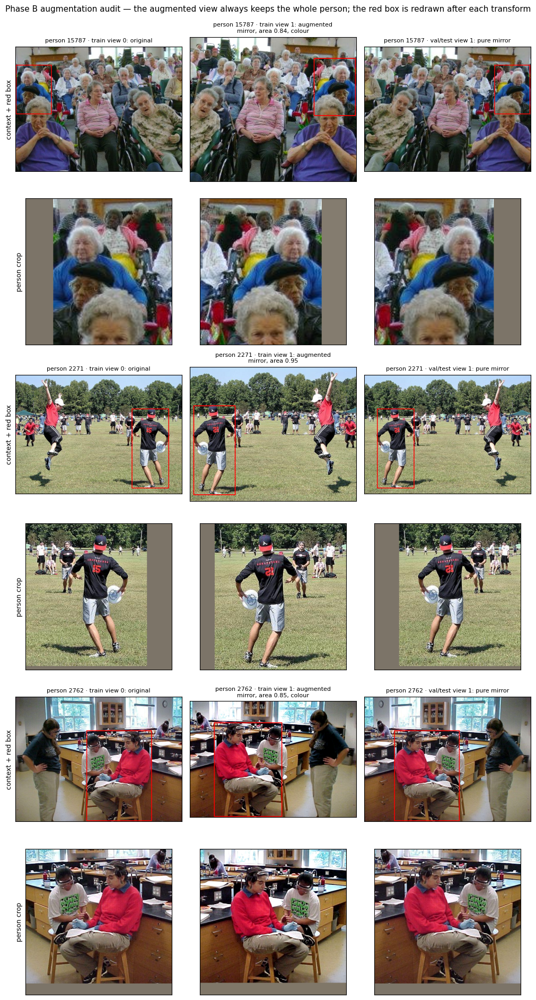

  ✓ augmentation audit figure saved                    got augmentation_views.png, expected png
  · disk now: cache 34.1 GB + /kaggle/working 7.3 GB (session limit 57 GB)

════════════════════════════════════════════════════════════════════════════
  7.9  VERDICT
════════════════════════════════════════════════════════════════════════════

  ✓ encoder output matches the Q-Former input (257 × 1408)
  ✓ crop token count matches the config
  ✓ planned cache fits the session's disk limit (checked BEFORE writing)
  ✓ a writable scratch location outside /kaggle/working
  ✓ extraction process succeeded
  ✓ encoder top recorded (cache at layer L − T)
  ✓ cache size as planned (never more)
  ✓ [train] 2 views × ['img', 'crop']: shapes and int8 storage
  ✓ [train] features finite, non-trivial, no unwritten rows (sample)
  ✓ [train] 8-bit cache matches the fp16 encoder output (per-token relative error)
  ✓ [train] person boxes valid in every view (inside the view, positive size)
  ✓ [train] geome

In [7]:
# Block 07 — Augmented-View Feature Cache (frozen EVA-ViT-g, 8-bit, fits the session disk)
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–06
#
# WHY CACHE
#   Xenos et al. keep the EVA-ViT-g image encoder FROZEN; only the Q-Former and
#   the head train. A frozen encoder's output for a given input never changes,
#   so every input is encoded ONCE per session here. The cache lives on the
#   scratch disk and is rebuilt at the start of every session (bit-identical:
#   the views are a fixed function of person and view). Only the InstructBLIP
#   shard holding vision_model / qformer / query_tokens is read, and it is
#   deleted from disk as soon as the weights are in memory (~10 GB).
#
# DISK — the reason this block was redesigned
#   A Kaggle session has ~57 GB of disk IN TOTAL (scratch + /kaggle/working),
#   although `df` reports ~1 TB. The first Phase B design (4 fp16 views + an
#   upper-body stream, ~125 GB) exceeded it. This version
#     * caches 2 views per person (train: original + augmented; val/test:
#       original + pure mirror) of the context image (257 tokens, at EVA layer
#       L−2) and the person crop (65 tokens);
#     * stores tokens in 8 bits: a fixed per-channel scale, the 8 largest
#       values of each token kept exactly, int8 with an fp16 scale per group
#       of 64 channels (~0.5 % error per token; verified below on the real
#       features against fp16 copies);
#     * computes the exact cache size BEFORE writing anything and stops (red)
#       if cache + /kaggle/working (20 GB) + a safety margin exceed the limit.
#   Expected: ~33 GB of cache, ~45–60 min per session on 2 x T4.
#
# THE AUGMENTED VIEW (train view 1)
#   mirror image + a context crop keeping 60–100 % of the image area that
#   ALWAYS contains the whole person (+5 % margin) + brightness / contrast /
#   saturation ±20 % (p 0.8, no hue) + person-crop jitter; the red box is
#   drawn after the transform; the description is left/right-swapped.
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt
from transformers import InstructBlipConfig

header("BLOCK 07 — Augmented-View Feature Cache (8-bit, fits the session disk)  [Phase B]")
V = BlockVerdict(7, "Feature cache")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"
KINDS = list(CFG.view_kinds)

# ──────────────────────────────────────────────────────────────────────────────
# 7.1  SIZE PLAN AND DISK BUDGET (nothing is written before this passes)
# ──────────────────────────────────────────────────────────────────────────────
print("7.1  SIZE PLAN AND DISK BUDGET\n")
_icfg = InstructBlipConfig.from_pretrained(CFG.backbone_ckpt)
_vc = _icfg.vision_config
N_TOK = (_vc.image_size // _vc.patch_size) ** 2 + 1
HID = int(_vc.hidden_size)
N_CROP = ((_vc.image_size // _vc.patch_size) // CFG.crop_pool) ** 2 + 1
SPLIT_N = {"train": len(df_train), "val": len(df_val), "test": len(df_test)}
PLAN_GB = core.planned_cache_bytes(SPLIT_N, CFG.views, KINDS, N_TOK, N_CROP, HID, CFG.cache_quant) / 1e9
# init_B.pt (Q-Former ~190 M + encoder top, fp32) and small files
_n_top = 2 * (4 * HID * HID + 2 * HID * int(_vc.intermediate_size))
INIT_GB = ((190e6 + _n_top) * 4 / 1e9 + 0.05) if not TEST_MODE else 0.05
WORK_USED_GB = dir_size_gb(CFG.work_dir)
WORK_RESERVE_GB = max(CFG.working_quota_gb, WORK_USED_GB)
BUDGET_GB = CFG.disk_quota_gb - WORK_RESERVE_GB - CFG.disk_safety_gb - INIT_GB
_fp16_gb = core.planned_cache_bytes(SPLIT_N, CFG.views, KINDS, N_TOK, N_CROP, HID, "fp16") / 1e9
EPOCH_READ_GB = SPLIT_N["train"] * sum(N_TOK if k == "img" else N_CROP for k in KINDS) * \
    core.bytes_per_token(HID, CFG.cache_quant) / 1e9
V.note("feature geometry", f"per view: image {N_TOK} tokens (EVA layer L-{CFG.vis_top_layers}) + person crop "
                           f"{N_CROP} tokens, × {HID} dims")
V.note("views", f"train {CFG.views['train']} (original + augmented) · val {CFG.views['val']} · "
                f"test {CFG.views['test']} (original + mirror)  →  "
                f"{sum(SPLIT_N[s] * CFG.views[s] * len(KINDS) for s in SPLIT_N):,} encoder passes")
V.note("storage", f"{CFG.cache_quant}: {core.bytes_per_token(HID, CFG.cache_quant):,} bytes per token "
                  f"(fp16 would be {2 * HID:,}) → cache {PLAN_GB:.1f} GB (fp16 would be {_fp16_gb:.1f} GB)")
V.note("disk budget", f"limit {CFG.disk_quota_gb:.0f} GB − /kaggle/working {WORK_RESERVE_GB:.0f} GB (reserved; "
                      f"{WORK_USED_GB:.1f} GB used now) − init {INIT_GB:.1f} GB − safety {CFG.disk_safety_gb:.0f} GB "
                      f"= {BUDGET_GB:.1f} GB for the cache")
if not TEST_MODE:
    V.check("encoder output matches the Q-Former input (257 × 1408)",
            (N_TOK, HID) == (CFG.vis_tokens, CFG.vis_dim), (N_TOK, HID), (CFG.vis_tokens, CFG.vis_dim))
V.check("crop token count matches the config", N_CROP == CFG.crop_tokens, N_CROP, CFG.crop_tokens)
V.check("planned cache fits the session's disk limit (checked BEFORE writing)", PLAN_GB <= BUDGET_GB,
        f"{PLAN_GB:.1f} GB", f"<= {BUDGET_GB:.1f} GB")
if PLAN_GB > BUDGET_GB:
    BLOCK_07_OK = V.finish()
    raise RuntimeError(f"The cache would need {PLAN_GB:.1f} GB but only {BUDGET_GB:.1f} GB fit next to "
                       f"/kaggle/working. Nothing was written. Reduce CFG.views['train'] or CFG.view_kinds "
                       f"in Block 01.")

# scratch location: outside /kaggle/working; old caches of earlier designs are removed first
_cands = [os.environ.get("EMOTIC_FEAT_ROOT", ""), "/kaggle/temp", "/tmp", "/kaggle/tmp", "/root", "/var/tmp"]
_work = str(CFG.work_dir.resolve())
_OLD = ("emotic_feats", "emotic_feats_v6", "emotic_feats_v7", "emotic_feats_phaseB")
for _c in [c for c in _cands if c]:
    for _o in _OLD:
        _od = Path(_c) / _o
        if _od.exists():
            _gb = dir_size_gb(_od)
            shutil.rmtree(_od, ignore_errors=True)
            V.note("removed an old feature cache", f"{_od} ({_gb:.1f} GB)")
FEAT_DIR = None
for _c in [c for c in _cands if c]:
    _p = Path(_c)
    _anchor = _p                                              # nearest existing parent
    while not _anchor.exists() and _anchor != _anchor.parent:
        _anchor = _anchor.parent
    if str(_anchor.resolve()).startswith(_work) or str(_p).startswith(_work):
        continue
    if not os.access(str(_anchor), os.W_OK):
        continue
    _fd = _p / "emotic_feats_phaseB2"
    _free = disk_free_gb(_anchor) + (dir_size_gb(_fd) if _fd.exists() else 0.0)
    if _free >= PLAN_GB + INIT_GB + 1.0:
        FEAT_DIR = _fd
        break
V.check("a writable scratch location outside /kaggle/working", FEAT_DIR is not None, str(FEAT_DIR), "found")
if FEAT_DIR is None:
    BLOCK_07_OK = V.finish()
    raise RuntimeError("No writable scratch directory with enough space. Set EMOTIC_FEAT_ROOT and re-run Block 07.")
FEAT_DIR.mkdir(parents=True, exist_ok=True)

# ──────────────────────────────────────────────────────────────────────────────
# 7.2  REUSE OR EXTRACT
# ──────────────────────────────────────────────────────────────────────────────
print("\n7.2  EXTRACTION\n")
_meta = json.loads((CFG.array_dir / "meta.json").read_text())
CACHE_KEY = {"order_hash": _meta["order_hash"], "backbone": CFG.backbone_ckpt, "n": SPLIT_N,
             "tokens": N_TOK, "hidden": HID, "crop_tokens": N_CROP, "crop_pool": CFG.crop_pool,
             "views": CFG.views, "kinds": KINDS, "quant": CFG.cache_quant, "aug": CFG.aug,
             "top_layers": CFG.vis_top_layers, "extract": "phaseB-3"}
_key_path = FEAT_DIR / "cache_key.json"
_sfx = ("q", "s", "i") if CFG.cache_quant == "int8" else ("",)


def _view_files(s, k, v):
    return [FEAT_DIR / (f"{s}_{k}_v{v}.{x}.npy" if x else f"{s}_{k}_v{v}.npy") for x in _sfx]


_done = core.read_json(FEAT_DIR / "extract_done.json")
_reuse = bool(_done) and core.read_json(_key_path) == CACHE_KEY and all(
    f.exists() for s in SPLIT_N for k in KINDS for v in range(CFG.views[s]) for f in _view_files(s, k, v))
if not _reuse and core.read_json(_key_path) not in (None, CACHE_KEY):
    V.note("stale cache", "key changed (data order, backbone, views, storage or policy) — rebuilding")
    shutil.rmtree(FEAT_DIR, ignore_errors=True)
    FEAT_DIR.mkdir(parents=True)
for _f in FEAT_DIR.glob("*.partial.npy"):         # unfinished split of an interrupted run: restarts cleanly
    _f.unlink()
core.write_json(_key_path, CACHE_KEY)
(FEAT_DIR / "extract_failed.json").unlink(missing_ok=True)

EXTRACT_RC = 0
if _reuse:
    V.note("cache", f"complete and matching — reused ({_done.get('seconds', 0) / 60:.1f} min saved)")
else:
    _man = {"repo": CFG.backbone_ckpt, "feat_dir": str(FEAT_DIR), "batch_size": 8,
            "workers_per_device": 0 if TEST_MODE else 2, "crop_pool": CFG.crop_pool,
            "top_layers": CFG.vis_top_layers, "views": CFG.views, "kinds": KINDS, "quant": CFG.cache_quant,
            "aug": CFG.aug, "check_rows": 64, "calib_rows": 128, "max_gb": round(BUDGET_GB, 2),
            "splits": [{"name": s, "index_path": str(CFG.array_dir / f"{s}_index.npz"),
                        "geo_path": str(CFG.array_dir / f"{s}_geo.npy")} for s in SPLIT_N]}
    (FEAT_DIR / "manifest.json").write_text(json.dumps(_man, indent=2))
    print(f"  {_B}Extracting on {max(N_GPUS, 1)} device(s). The first minutes download the ~10 GB "
          f"InstructBLIP shard silently (deleted again once loaded).{_0}\n")
    _t0 = time.time()
    _log = open(CFG.log_dir / "extract_phaseB.log", "a")
    _proc = subprocess.Popen([sys.executable, str(CFG.core_path), "extract", "--manifest",
                              str(FEAT_DIR / "manifest.json")],
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                             env=dict(os.environ, PYTHONUNBUFFERED="1"))
    try:
        for _line in _proc.stdout:
            _log.write(_line)
            print("  " + _line, end="", flush=True)
        EXTRACT_RC = _proc.wait()
    except KeyboardInterrupt:
        _proc.terminate()
        try:
            _proc.wait(timeout=30)
        except subprocess.TimeoutExpired:
            _proc.kill()
        EXTRACT_RC = -2
        print(f"\n  {_Y}Interrupted. Finished splits are kept; re-run this block to continue.{_0}")
    finally:
        _log.close()
    V.note("extraction time", f"{(time.time() - _t0) / 60:.1f} min")
V.check("extraction process succeeded", EXTRACT_RC == 0, EXTRACT_RC, 0)
if (FEAT_DIR / "extract_failed.json").exists() or EXTRACT_RC != 0:
    print(core.read_json(FEAT_DIR / "extract_failed.json", {}).get("error", "")[-2500:])
    BLOCK_07_OK = V.finish()
    raise RuntimeError("Feature extraction failed — see the error above.")

# ──────────────────────────────────────────────────────────────────────────────
# 7.3  VERIFY
# ──────────────────────────────────────────────────────────────────────────────
print("\n7.3  VERIFY\n")
_ed = core.read_json(FEAT_DIR / "extract_done.json", {}) or {}
VIEWS_META = core.read_json(FEAT_DIR / "views.json", {}) or {}
V.check("encoder top recorded (cache at layer L − T)", VIEWS_META.get("top_layers") == min(
    CFG.vis_top_layers, VIEWS_META.get("n_layers", 0)) and VIEWS_META.get("cache_layer") ==
    VIEWS_META.get("n_layers", 0) - VIEWS_META.get("top_layers", -1),
    f"L = {VIEWS_META.get('n_layers')}, cache at {VIEWS_META.get('cache_layer')}", f"T = {CFG.vis_top_layers}")
CACHE_GB = dir_size_gb(FEAT_DIR)
V.check("cache size as planned (never more)", CACHE_GB <= PLAN_GB + INIT_GB + 0.5,
        f"{CACHE_GB:.1f} GB", f"<= {PLAN_GB + INIT_GB:.1f} GB")
V.note("Hugging Face checkpoint removed after loading", f"{_ed.get('hf_freed_gb', 0):.1f} GB freed")
FEAT_INFO = {}
_rsv = np.random.RandomState(1)
for s, n in SPLIT_N.items():
    _a = core.SplitArrays(CFG.array_dir, s, FEAT_DIR, need_crop="crop" in KINDS)
    info = core.read_json(FEAT_DIR / f"{s}_done.json", {}) or {}
    FEAT_INFO[s] = info
    nv = CFG.views[s]
    _pick = np.sort(_rsv.choice(n, size=min(n, 64), replace=False))
    _ds = core.FeatureDataset(_a, use_crop="crop" in KINDS)
    _shapes_ok = _a.n_views == nv and all(len(_a.paths[k]) == nv for k in KINDS) and \
        _a.shapes["img"] == (n, N_TOK, HID) and ("crop" not in KINDS or _a.shapes["crop"] == (n, N_CROP, HID))
    V.check(f"[{s}] {nv} views × {KINDS}: shapes and {CFG.cache_quant} storage", _shapes_ok,
            f"{nv * len(KINDS)} streams", f"({n}, {N_TOK}|{N_CROP}, {HID})")
    _finite, _empty, _cls = True, 0, []
    for v in range(nv):
        _ds.view = v
        _x = np.stack([_ds[int(i)]["vis"] for i in _pick]).astype(np.float32)
        _finite &= bool(np.isfinite(_x).all() and _x.std() > 1e-4)
        _empty += int((np.abs(_x).reshape(len(_pick), -1).max(1) == 0).sum())
        _cls.append(_x[:, 0])
    V.check(f"[{s}] features finite, non-trivial, no unwritten rows (sample)", _finite and _empty == 0,
            f"{_empty} empty rows", "finite, 0 empty")
    # 8-bit reconstruction against fp16 copies of view 0 written by the extractor
    _m = int(np.load(FEAT_DIR / f"{s}_img_final_check.npy", mmap_mode="r").shape[0])
    _ds.view = 0
    _errs = {}
    for k in KINDS:
        _ref = np.load(FEAT_DIR / f"{s}_{k}_v0_check.npy").astype(np.float32)
        _rec = np.stack([_ds[i]["vis" if k == "img" else k] for i in range(_m)]).astype(np.float32)
        _tok = np.linalg.norm(_rec - _ref, axis=-1) / (np.linalg.norm(_ref, axis=-1) + 1e-9)
        _errs[k] = (float(np.median(_tok)), float(np.percentile(_tok, 99)))
    V.check(f"[{s}] 8-bit cache matches the fp16 encoder output (per-token relative error)",
            all(e[0] < 0.01 and e[1] < 0.03 for e in _errs.values()),
            "  ".join(f"{k} median {100 * e[0]:.2f}% p99 {100 * e[1]:.2f}%" for k, e in _errs.items()),
            "median < 1%, p99 < 3%")
    V.check(f"[{s}] person boxes valid in every view (inside the view, positive size)",
            _a.roi.shape == (n, nv, 4) and bool((_a.roi >= 0).all() and (_a.roi <= 1).all()
                                                and (_a.roi[..., 2] > _a.roi[..., 0]).all()
                                                and (_a.roi[..., 3] > _a.roi[..., 1]).all()), _a.roi.shape, (n, nv, 4))
    V.check(f"[{s}] geometry finite and in [0, 1]", _a.geo.shape == (n, nv, 9) and bool(
        np.isfinite(_a.geo).all() and (_a.geo >= 0).all() and (_a.geo <= 1).all()), _a.geo.shape, (n, nv, 9))
    _fv = [float(_a.flip[:, v].mean()) for v in range(nv)]
    V.check(f"[{s}] view 0 is never mirrored, view 1 always", _fv[0] == 0.0 and (nv < 2 or _fv[1] == 1.0),
            " ".join(f"v{v}:{f:.2f}" for v, f in enumerate(_fv)), "v0 0.00, v1 1.00")
    _fail = int(info.get("failed_images", -1))
    V.check(f"[{s}] every image decoded", _fail == 0, _fail, 0)
    if len(_cls) >= 2:
        _rel = float(np.median(np.linalg.norm(_cls[0] - _cls[1], axis=1) / (np.linalg.norm(_cls[0], axis=1) + 1e-9)))
        V.check(f"[{s}] the two views differ (CLS relative difference)", _rel > 0.005, f"{_rel:.3f}", "> 0.005")
    _g0 = np.load(CFG.array_dir / f"{s}_geo.npy")
    _dg = float(np.abs(_a.geo[:, 0, :6] - _g0[:, :6]).max())
    V.check(f"[{s}] view-0 geometry agrees with Block 03 (image size from the file vs the annotation)",
            _dg < 0.05, f"max |Δ| {_dg:.4f}", "< 0.05", fatal=False)
    del _a, _ds

# the encoder top on the (8-bit) cached layer-(L−2) tokens must give the encoder's own output
_init = torch.load(FEAT_DIR / "init_B.pt", map_location="cpu", weights_only=False)
_dev = torch.device("cuda:0" if N_GPUS > 0 else "cpu")
_top = core.VisionTop(_icfg.vision_config, _init["top_layers"])
_top.load_state_dict({k: v.float() for k, v in _init["vis_top"].items()}, strict=True)
_top = _top.to(_dev).eval()
_errs = []
for s in SPLIT_N:
    _ref = np.load(FEAT_DIR / f"{s}_img_final_check.npy").astype(np.float32)
    _a = core.SplitArrays(CFG.array_dir, s, FEAT_DIR)
    _ds = core.FeatureDataset(_a)
    _src = np.stack([_ds[i]["vis"] for i in range(len(_ref))]).astype(np.float32)
    with torch.no_grad():
        _out = torch.cat([_top(torch.from_numpy(_src[i:i + 16]).to(_dev)).float().cpu()
                          for i in range(0, len(_src), 16)]).numpy()
    _errs.append(float(np.linalg.norm(_out - _ref) / (np.linalg.norm(_ref) + 1e-9)))
    del _a, _ds
V.check("encoder top on the 8-bit cached tokens reproduces the encoder output (all splits)", max(_errs) < 0.02,
        " ".join(f"{e:.4f}" for e in _errs), "relative error < 0.02")
del _top, _init
free_memory()
_probe_cfg = core.merged_config({"hf_config_dir": str(FEAT_DIR / "hf_config"), "use_roi": True, "use_geo": True,
                                 "use_crop": True, "top_trainable": True})
_probe = core.build_model(_probe_cfg, (1, N_TOK, HID), GEOMETRY_DIM, top_layers=VIEWS_META.get("top_layers", 2))
_n_loaded = core.load_pretrained_init(_probe, FEAT_DIR / "init_B.pt")
V.check("pretrained Q-Former + encoder top load strictly into the full Phase B model", _n_loaded > 0,
        f"{_n_loaded} tensors", "all")
V.note("full Phase B model", f"{sum(p.numel() for p in _probe.parameters()) / 1e6:.1f} M parameters "
                             f"({sum(p.numel() for p in _probe.top.parameters()) / 1e6:.1f} M in the encoder top)")
del _probe
V.note("weights", _ed.get("weights", "?"))
if not TEST_MODE:
    V.check("InstructBLIP weights read selectively (language model skipped)", "selective" in _ed.get("weights", ""),
            _ed.get("weights", "?")[:40], "selective safetensors", fatal=False)
# same cache as in the previous session? (runs resume bit-identically only if it is)
_prev = core.read_json(CFG.cache_dir / "feat_dir.json", {}) or {}
FINGERPRINT = _ed.get("fingerprint")
if _prev.get("fingerprint") and _prev.get("cache_key") == CACHE_KEY:
    V.check("cache identical to the previous session's (resumed runs continue bit-identically)",
            _prev["fingerprint"] == FINGERPRINT, FINGERPRINT, _prev["fingerprint"], fatal=False)
else:
    V.note("cache fingerprint", f"{FINGERPRINT} (compared with the next session's)")
# disk read speed (training reads one view per person per epoch)
_f = FEAT_DIR / (f"train_img_v{CFG.views['train'] - 1}.q.npy" if CFG.cache_quant == "int8"
                 else f"train_img_v{CFG.views['train'] - 1}.npy")
_mm = np.load(_f, mmap_mode="r")
_rows = np.sort(np.random.RandomState(9).choice(len(_mm), size=min(len(_mm), 512), replace=False))
_t = time.time()
_nbytes = sum(np.asarray(_mm[i]).nbytes for i in _rows)
_dt = max(time.time() - _t, 1e-6)
V.note("scratch-disk random read", f"{_nbytes / _dt / 1e6:.0f} MB/s on {len(_rows)} rows "
                                   f"(an epoch reads ~{EPOCH_READ_GB:.0f} GB)")
del _mm

# ──────────────────────────────────────────────────────────────────────────────
# 7.4  AUGMENTATION AUDIT — what the encoder saw, for 3 train persons
# ──────────────────────────────────────────────────────────────────────────────
print("\n7.4  AUGMENTATION AUDIT\n")
_z = np.load(CFG.array_dir / "train_index.npz")
_bg = np.load(CFG.array_dir / "train_geo.npy")
_area = _bg[:, 4]
_cand = np.where((_area > 0.03) & (_area < 0.35))[0]
_cand = _cand if len(_cand) >= 3 else np.arange(len(_area))
_who = np.random.RandomState(5).choice(_cand, size=3, replace=False)
_vd = core.ViewDataset("train", _z["paths"], _z["boxes"].astype(np.int64), _bg, np.arange(len(_area)), None,
                       CFG.views["train"], CFG.aug, KINDS)
_vv = core.ViewDataset("val", _z["paths"], _z["boxes"].astype(np.int64), _bg, np.arange(len(_area)), None,
                       2, CFG.aug, KINDS)        # the val/test mirror view, rendered for comparison
K_COLS = CFG.views["train"] + 1
fig, axes = plt.subplots(3 * 2, K_COLS, figsize=(3.4 * K_COLS, 3.2 * 6))
for r, i in enumerate(_who):
    views, ok = _vd.render(int(i))
    views = views + [_vv.render(int(i))[0][1]]
    for v, (prm, ctx, crop, ub, roi, geo) in enumerate(views):
        if v == len(views) - 1:
            tag = "val/test view 1: pure mirror"
        elif v == 0:
            tag = "train view 0: original"
        else:
            tag = (f"train view {v}: augmented\nmirror, area {prm['zoom'][0]:.2f}"
                   + (", colour" if prm["color"] else ""))
        for j, (im, what) in enumerate(((ctx, "context + red box"), (crop, "person crop"))):
            ax = axes[2 * r + j, v]
            ax.imshow(im)
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0:
                ax.set_title(f"person {int(i)} · {tag}", fontsize=8)
            if v == 0:
                ax.set_ylabel(what, fontsize=9)
fig.suptitle("Phase B augmentation audit — the augmented view always keeps the whole person; the red box is "
             "redrawn after each transform", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.985))
AUG_FIG = CFG.figures_dir / "augmentation_views.png"
fig.savefig(AUG_FIG, dpi=80, bbox_inches="tight")
plt.show()
plt.close(fig)
V.check("augmentation audit figure saved", AUG_FIG.exists(), AUG_FIG.name, "png")

core.write_json(CFG.cache_dir / "feat_dir.json", {"feat_dir": str(FEAT_DIR), "cache_key": CACHE_KEY,
                                                  "session_start": SESSION_START, "views": VIEWS_META,
                                                  "fingerprint": FINGERPRINT, "cache_gb": CACHE_GB})
V.note("disk now", f"cache {CACHE_GB:.1f} GB + /kaggle/working {dir_size_gb(CFG.work_dir):.1f} GB "
                   f"(session limit {CFG.disk_quota_gb:.0f} GB)")
free_memory()
BLOCK_07_OK = V.finish()


In [8]:
# Block 08 — Two-GPU Experiment Scheduler (Phase B: WITH augmentation)
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–07 in this session
#
# WHAT RUNS — a cumulative ablation ladder (every seed with its own initial
# weights; 12-epoch cosine; image + ROI tokens + person crop + geometry in all):
#
#   B0_noaug   original view only (no augmentation) — the control that
#              separates the effect of augmentation from the longer schedule
#   B1_aug     + the augmented view: each epoch a person is shown either the
#              original or the augmented rendering (mirror + context crop that
#              keeps the whole person + colour jitter; left/right-swapped text)
#   B2_top     + the top 2 EVA layers trained (lr x 0.1, like the Q-Former)
#
#   Every configuration runs with seeds 1–5 (15 runs, ~22 GPU-hours).
#   Order is seed-major (all configurations with seed 1, then seed 2, …), so
#   every finished round is a complete, paired ablation row.
#   Test-time mirror averaging is NOT a training choice: every run is scored in
#   both views and Block 09 decides on test-like validation.
#   Nothing here reads test results.
#
# CHECKPOINTING / CRASH SAFETY (per run, /kaggle/working/runs_phaseB/<run>/)
#   last.pt   every epoch end + on any pause: weights, EMA, AdamW, LR schedule,
#             AMP scaler, epoch + micro-batch position, best score, early-stop
#             counter, history, RNG states. A crash loses at most one epoch.
#   Pauses save at the exact optimizer step: session deadline (11.5 h − 30 min),
#   STOP (notebook interrupt / Block 08S), SIGTERM, or the notebook dying.
#   Next session: Blocks 01–07, then this block — runs resume bit-identically
#   (the augmented views are a fixed function of person and view, so the
#   rebuilt cache is identical).
#
# MEMORY
#   The pre-flight (Block 06) picked a micro-batch per encoder-top mode with
#   1.5 GB headroom; a CUDA OOM inside a step is recovered by redoing that
#   micro-batch in halves; caches are released after every epoch and scoring.
#
# DISK (/kaggle/working, 20 GB)
#   A running job needs ~4–5 GB (last.pt + best.pt); a finished one keeps its
#   scores + fp16 best.pt (~0.5 GB). If space runs low, the fp16 weights of
#   FINISHED runs move to the scratch disk (controls B0 first, B2 last). Their
#   scores stay, so Blocks 09–10 are unaffected, but those weight files are
#   gone when the session ends — download them first if you need them.
# ══════════════════════════════════════════════════════════════════════════════

import csv
import signal
import numpy as np

header("BLOCK 08 — Two-GPU Experiment Scheduler (Phase B, with augmentation)  [Phase B]")
V = BlockVerdict(8, "Training")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"

# ──────────────────────────────────────────────────────────────────────────────
# 8.1  PLAN
# ──────────────────────────────────────────────────────────────────────────────
print("8.1  PLAN\n")
_PERSON = dict(use_roi=True, use_geo=True, use_crop=True)
CONFIGS = {
    "B0_noaug": dict(_PERSON),
    "B1_aug":   dict(_PERSON, augment=True),
    "B2_top":   dict(_PERSON, augment=True, top_trainable=True),
}
CONFIG_DESC = {"B0_noaug": "no augmentation (original view only) — control",
               "B1_aug": "+ augmented view (mirror, context crop, colour)",
               "B2_top": "+ top 2 encoder layers trained (proposed full model)"}
SEEDS = [1, 2] if TEST_MODE else [1, 2, 3, 4, 5]
CONFIG_SEEDS = {c: SEEDS for c in CONFIGS}
ROUND_ORDER = ["B2_top", "B1_aug", "B0_noaug"]
PLAN = [f"{c}_s{s}" for s in SEEDS for c in ROUND_ORDER if s in CONFIG_SEEDS[c]]
TRACK_CCIM = CFG.ccim_test_map / CFG.val_to_test
TRACK_XENOS = CFG.xenos_test_map / CFG.val_to_test
EPOCH_LIMIT = (int(os.environ.get("EMOTIC_TEST_MAX_EPOCHS", "3")) if TEST_MODE
               else int(CFG.train["max_epochs"]))
EXTENSIBLE_KEYS = ("min_epochs", "patience", "min_delta", "log_every", "floor_check_epoch",
                   "floor_min_lift", "max_oom_per_epoch", "num_workers", "eval_batch_size")

if "FEAT_DIR" not in globals():
    FEAT_DIR = Path(core.read_json(CFG.cache_dir / "feat_dir.json", {})["feat_dir"])
_pf = core.read_json(CFG.cache_dir / "preflight.json", {}) or {}
if not isinstance(globals().get("MICRO_BATCH"), dict):
    MICRO_BATCH, GRAD_ACCUM = _pf.get("micro_batch") or {}, _pf.get("grad_accum") or {}
EPOCH_MIN_UPPER = _pf.get("epoch_min_upper") or {}
ORDER_HASH_NOW = json.loads((CFG.array_dir / "meta.json").read_text())["order_hash"]
ARCHIVE_DIR = FEAT_DIR.parent / "emotic_weights_archive_phaseB"

def _cache_complete():
    """Block 07's cache: finished, same data order, every split readable with all views and streams."""
    try:
        if not (FEAT_DIR / "extract_done.json").exists():
            return False
        if core.read_json(FEAT_DIR / "cache_key.json", {}).get("order_hash") != ORDER_HASH_NOW:
            return False
        for s in ("train", "val", "test"):
            a = core.SplitArrays(CFG.array_dir, s, FEAT_DIR, need_crop="crop" in CFG.view_kinds)
            if a.n_views != CFG.views[s] or any(len(a.paths[k]) != CFG.views[s] for k in CFG.view_kinds):
                return False
        return True
    except Exception:
        return False


V.check("feature cache of this session is complete (all views and streams)", _cache_complete(), str(FEAT_DIR),
        "extract_done + matching order")
V.check("mirror-consistent descriptions present (Block 05)",
        all((CFG.array_dir / f"{s}_ids_flip_flat.npy").exists() for s in ("train", "val", "test")), "yes", "yes")
V.check("micro-batch chosen by the GPU pre-flight for both encoder-top modes",
        TEST_MODE or all(MICRO_BATCH.get(k) in (8, 16, 32) for k in ("frozen", "trained")),
        {k: f"{MICRO_BATCH.get(k)} x {GRAD_ACCUM.get(k)}" for k in ("frozen", "trained")}, "fits")
if TEST_MODE:
    MICRO_BATCH, GRAD_ACCUM = {"frozen": 8, "trained": 8}, {"frozen": 2, "trained": 2}
SLOTS = list(range(min(N_GPUS, 2))) if N_GPUS > 0 else ["cpu0", "cpu1"]
V.note("devices", ", ".join(f"GPU {s}" if isinstance(s, int) else s for s in SLOTS))
V.note("training deadline", time.strftime("%H:%M:%S", time.localtime(GUARD.training_deadline()))
       + f"  ({GUARD.training_remaining_s() / 3600:.2f} h of training time left)")
V.note("recipe", f"{CFG.train['lr_schedule']} LR over {EPOCH_LIMIT} epochs, early stop after "
                 f"{CFG.train['patience']} flat epochs (min {CFG.train['min_epochs']}), EMA {CFG.train['ema_decay']}, "
                 f"wd {CFG.train['weight_decay']}, length-bucketed batches, own initialisation per seed")
for c in CONFIGS:
    mode = "trained" if CONFIGS[c].get("top_trainable") else "frozen"
    V.note(f"  {c:<10s}", f"{CONFIG_DESC[c]}  [seeds {CONFIG_SEEDS[c]}, micro-batch {MICRO_BATCH.get(mode)} x "
                          f"{GRAD_ACCUM.get(mode)}]")
V.note("runs", f"{len(PLAN)} (seed-major)")


def parse(name):
    c, s = name.rsplit("_s", 1)
    return c, int(s)


def rdir(name):
    return CFG.runs_dir / name


def run_state(name):
    d = rdir(name)
    res = core.read_json(d / "result.json", {}) or {}
    if res.get("status") == "done":
        if res.get("extendable") and (d / "last.pt").exists() and EPOCH_LIMIT > int(res.get("epochs_run", 0)):
            return "extendable"
        return "done"
    if (d / "finished.json").exists():
        return "finishing"
    if res.get("status") == "failed":
        return "failed"
    if (d / "last.pt").exists():
        return "paused"
    return "new"


def best_val(name):
    res = core.read_json(rdir(name) / "result.json", {}) or {}
    if isinstance(res.get("best"), dict):
        return res["best"]["val_tl_mAP"]
    b = (core.read_json(rdir(name) / "status.json", {}) or {}).get("best")
    return b if isinstance(b, (int, float)) else None


def tta_val(name):
    ev = core.read_json(rdir(name) / "eval.json", {}) or {}
    return ev.get("val_tl_mAP_tta")


def epoch_minutes():
    vals = []
    for n in PLAN:
        h = rdir(n) / "history.csv"
        if h.exists():
            try:
                vals += [float(r["train_min"]) + float(r["eval_min"]) for r in csv.DictReader(open(h))]
            except Exception:
                pass
    if vals:
        return float(np.median(vals))
    ups = [v for v in EPOCH_MIN_UPPER.values() if v]
    return float(np.mean(ups)) * 0.8 if ups else 10.0


LAUNCHES = {}          # per run, in this execution of the block
MAX_LAUNCHES = 3       # a run that dies 3 times without saving is left alone
RETRIED = set()        # a crashed run gets ONE automatic retry per execution
MIN_LEFT = (dict(fresh=30, resume=12, extend=20, retry=45) if not TEST_MODE
            else dict(fresh=1, resume=1, extend=1, retry=1))


def next_job(active):
    """Pure: decides what to start next."""
    tr = GUARD.training_remaining_s() / 60.0
    order = [n for n in PLAN if n not in active and LAUNCHES.get(n, 0) < MAX_LAUNCHES]
    for n in order:                                    # 1) resume / extend / finalise
        st = run_state(n)
        if st in ("paused", "finishing") and tr > MIN_LEFT["resume"]:
            return n, "resume"
        if st == "extendable" and tr > MIN_LEFT["extend"]:
            return n, "extend"
    for n in order:                                    # 2) one retry of a crashed run
        if run_state(n) != "failed" or n in RETRIED or tr < MIN_LEFT["retry"]:
            continue
        msg = str((core.read_json(rdir(n) / "result.json", {}) or {}).get("message", ""))
        if "floor check" not in msg and "signature mismatch" not in msg:
            return n, "retry"
    for n in order:                                    # 3) next run of the plan
        if run_state(n) == "new" and tr > MIN_LEFT["fresh"]:
            return n, "fresh"
    return None


def make_room(need_gb):
    """Move fp16 weights of finished runs to scratch until need_gb is free (scores stay).
    Controls go first (B0, then B1, …); the full model's weights are kept longest."""
    if disk_free_gb(CFG.work_dir) >= need_gb:
        return True
    ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
    for n in sorted(PLAN, key=lambda x: (ROUND_ORDER[::-1].index(parse(x)[0]), parse(x)[1])):
        if disk_free_gb(CFG.work_dir) >= need_gb:
            break
        b = rdir(n) / "best.pt"
        if run_state(n) == "done" and b.exists() and (rdir(n) / "scores.npz").exists():
            shutil.move(str(b), str(ARCHIVE_DIR / f"{n}_best_fp16.pt"))
            print(f"{_Y}  disk: moved {n}/best.pt to {ARCHIVE_DIR} (scores stay in {rdir(n)}){_0}")
    return disk_free_gb(CFG.work_dir) >= need_gb


# ──────────────────────────────────────────────────────────────────────────────
# 8.2  WORKERS
# ──────────────────────────────────────────────────────────────────────────────
class Slot:
    def __init__(self, name, dev, proc, logf, offset, mode):
        self.name, self.dev, self.proc, self.logf = name, dev, proc, logf
        self.offset, self.mode, self.t0 = offset, mode, time.time()


def launch(name, dev, mode):
    cfg_name, seed = parse(name)
    d = rdir(name)
    d.mkdir(parents=True, exist_ok=True)
    LAUNCHES[name] = LAUNCHES.get(name, 0) + 1
    if mode == "retry":
        RETRIED.add(name)
        if (d / "result.json").exists():
            os.replace(d / "result.json", d / f"result_failed_{int(time.time())}.json")
    old = core.read_json(d / "spec_resolved.json") if mode != "fresh" else None
    if old:
        if old.get("order_hash") not in (None, ORDER_HASH_NOW):
            raise RuntimeError(f"{name}: data order changed since this run started — cannot resume")
        spec = dict(old)                        # the run keeps its own trajectory settings …
        if not TEST_MODE:                       # … but takes the current stop / logging settings
            spec.update({k: CFG.train[k] for k in EXTENSIBLE_KEYS if k in CFG.train})
        if spec.get("lr_schedule") == "plateau":
            spec["max_epochs"] = EPOCH_LIMIT    # only plateau runs may change their length
    else:
        mode_top = "trained" if CONFIGS[cfg_name].get("top_trainable") else "frozen"
        spec = dict(CFG.train)
        spec.update(CONFIGS[cfg_name])
        spec.update(name=name, config_name=cfg_name, seed=seed, phase="B_augmentation",
                    batch_size=MICRO_BATCH[mode_top], grad_accum=GRAD_ACCUM[mode_top],
                    order_hash=ORDER_HASH_NOW, max_epochs=EPOCH_LIMIT)
        if TEST_MODE:
            spec.update(min_epochs=1, patience=2, floor_min_lift=0.0, num_workers=0,
                        log_every=5, eval_batch_size=32, lr=1e-3)
    spec.update(run_dir=str(d), array_dir=str(CFG.array_dir), feat_dir=str(FEAT_DIR),
                hf_config_dir=str(FEAT_DIR / "hf_config"), init_path=str(FEAT_DIR / "init_B.pt"),
                control_dir=str(CFG.control_dir), deadline=GUARD.training_deadline(),
                parent_pid=os.getpid(), test_inject_nonfinite_every=0, test_stop_after_steps=0,
                test_inject_oom_every=0)
    core.write_json(d / "spec.json", spec)
    (CFG.control_dir / f"STOP_{name}").unlink(missing_ok=True)
    logp = d / "worker.log"
    offset = logp.stat().st_size if logp.exists() else 0
    logf = open(logp, "a")
    logf.write(f"\n##### {mode} {time.strftime('%Y-%m-%d %H:%M:%S')} on {dev} #####\n")
    logf.flush()
    env = dict(os.environ, PYTHONUNBUFFERED="1", OMP_NUM_THREADS="2",
               PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True",
               CUDA_VISIBLE_DEVICES=str(dev) if isinstance(dev, int) else "")
    proc = subprocess.Popen([sys.executable, str(CFG.core_path), "train", "--spec", str(d / "spec.json")],
                            stdout=logf, stderr=subprocess.STDOUT, env=env, start_new_session=True)
    tag = f"GPU {dev}" if isinstance(dev, int) else dev
    print(f"\n{_B}▶ {mode.upper():<6s} {name}  on {tag}  (pid {proc.pid}, micro-batch "
          f"{spec['batch_size']} x {spec['grad_accum']})  — {CONFIG_DESC[cfg_name]}{_0}", flush=True)
    return Slot(name, dev, proc, logf, offset, mode)


def stream(slot):
    p = rdir(slot.name) / "worker.log"
    try:
        with open(p, "rb") as f:
            f.seek(slot.offset)
            data = f.read()
    except FileNotFoundError:
        return
    if not data:
        return
    cut = data.rfind(b"\n")
    if cut < 0:
        return
    slot.offset += cut + 1
    for line in data[:cut].decode("utf-8", "replace").splitlines():
        if line.startswith("#####") or not line.strip():
            continue
        print(f"{_D}{slot.name:<13s}|{_0} {line}", flush=True)


def gpu_line():
    if N_GPUS == 0:
        return ""
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=index,utilization.gpu,memory.used,memory.total",
                              "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=10).stdout
        return "  ".join(f"GPU{r[0]} {r[1]}% {float(r[2]) / 1024:.1f}/{float(r[3]) / 1024:.0f}GB"
                         for r in (x.split(", ") for x in out.strip().splitlines()))
    except Exception:
        return ""


def colour_val(v, width=7):
    if v is None:
        return f"{'-':>{width}s}"
    c = _G if v >= TRACK_CCIM else (_Y if v >= TRACK_XENOS else _R)
    return f"{c}{v:{width}.2f}{_0}"


def status_table(slots):
    active = {s.name: s for s in slots.values() if s}
    print(f"\n  {'─' * 78}\n  STATUS  {time.strftime('%H:%M:%S')}  |  {GUARD.footer()}  |  "
          f"training left {GUARD.training_remaining_s() / 3600:.2f} h")
    print("  best test-like val mAP per run, original view  (▶ running  ‖ paused  ✗ failed  · waiting)")
    print(f"  {'config':<11s}" + "".join(f"{f's{s}':>9s}" for s in SEEDS) + f"{'mean (n)':>14s}  {'mirror-TTA':>11s}")
    for c in ROUND_ORDER[::-1]:
        cells, done_vals, tta = [], [], []
        for s in SEEDS:
            n = f"{c}_s{s}"
            if s not in CONFIG_SEEDS[c]:
                cells.append(f"{'':>9s}")
                continue
            st = "running" if n in active else run_state(n)
            v = best_val(n)
            if st == "done" and v is not None:
                done_vals.append(v)
                if tta_val(n) is not None:
                    tta.append(tta_val(n))
                cells.append(" " + colour_val(v, 8))
            elif st == "running":
                ep = (core.read_json(rdir(n) / "progress.json", {}) or {}).get("epoch", 0)
                cells.append(f"{f'▶ep{ep}/{EPOCH_LIMIT}':>9s}")
            elif st in ("paused", "finishing", "extendable"):
                cells.append(f"{'‖' + (f'{v:.2f}' if v else ''):>9s}")
            elif st == "failed":
                cells.append(f"{'✗':>9s}")
            else:
                cells.append(f"{'·':>9s}")
        mean = f"{np.mean(done_vals):6.2f} ({len(done_vals)})" if done_vals else "-"
        tmean = f"{np.mean(tta):6.2f}" if tta else "-"
        print(f"  {c:<11s}" + "".join(cells) + f"{mean:>14s}  {tmean:>11s}")
    em = epoch_minutes()
    left = [n for n in PLAN if run_state(n) not in ("done",)]
    print(f"  epoch ≈ {em:.1f} min | {len(PLAN) - len(left)}/{len(PLAN)} runs done | ≈ "
          f"{GUARD.training_remaining_s() / 60 / em * len(SLOTS):.0f} epochs of GPU time left this session")
    g = gpu_line()
    if g:
        print(f"  {g}")
    print(f"  colours: green ≥ {TRACK_CCIM:.1f} (CCIM track)  yellow ≥ {TRACK_XENOS:.1f} (Xenos track) — "
          f"val monitor only (Phase A: test ≈ {CFG.val_to_test} × val-TL) | /kaggle/working free "
          f"{disk_free_gb(CFG.work_dir):.1f} GB\n  {'─' * 78}\n", flush=True)


def worker_pids():
    pids = []
    try:
        import psutil
        for p in psutil.process_iter(["pid", "cmdline"]):
            cl = p.info.get("cmdline") or []
            if any(str(CFG.core_path) == a for a in cl) and any(c in cl for c in ("train", "evaluate")):
                pids.append(p.info["pid"])
    except Exception:
        pass
    return pids


def stop_all(slots, reason):
    alive = [s for s in slots.values() if s and s.proc.poll() is None]
    (CFG.control_dir / "STOP").write_text(reason)
    print(f"\n{_Y}■ STOP requested ({reason}). {len(alive)} worker(s) are saving an exact "
          f"resume point — usually < 1 min. Do not interrupt again.{_0}", flush=True)
    t0 = time.time()
    while any(s.proc.poll() is None for s in alive) and time.time() - t0 < 300:
        for s in alive:
            stream(s)
        time.sleep(3)
    for s in alive:
        if s.proc.poll() is None:
            s.proc.send_signal(signal.SIGTERM)
    t1 = time.time()
    while any(s.proc.poll() is None for s in alive) and time.time() - t1 < 90:
        time.sleep(3)
    for s in alive:
        if s.proc.poll() is None:
            s.proc.kill()
    for s in slots.values():
        if s:
            stream(s)
            s.logf.close()
    (CFG.control_dir / "STOP").unlink(missing_ok=True)
    for s in alive:
        st = run_state(s.name)
        c = _G if st in ("paused", "done", "finishing", "new") else _R
        print(f"  {c}{s.name}: {st}{_0}")
    for k in list(slots):
        slots[k] = None


# ──────────────────────────────────────────────────────────────────────────────
# 8.3  RUN
# ──────────────────────────────────────────────────────────────────────────────
print("\n8.3  RUN\n")
for _f in CFG.control_dir.glob("STOP*"):
    V.note("removed stale stop file", _f.name)
    _f.unlink()
_orphans = worker_pids()
if _orphans:
    V.note("workers from an earlier cell still alive", f"{_orphans} — asking them to save and exit")
    (CFG.control_dir / "STOP").write_text("orphan cleanup")
    _t = time.time()
    while worker_pids() and time.time() - _t < 300:
        time.sleep(5)
    (CFG.control_dir / "STOP").unlink(missing_ok=True)
V.check("no stray training workers", not worker_pids(), worker_pids() or "none", "none")
V.check("/kaggle/working has room for two runs", make_room(8.0),
        f"{disk_free_gb(CFG.work_dir):.1f} GB", ">= 8 GB")
free_memory()

slots = {d: None for d in SLOTS}
EXITS = []
_t_table, _t_run0, _blocked = 0.0, time.time(), False
try:
    while True:
        for dev, s in slots.items():                       # reap
            if s is not None and s.proc.poll() is not None:
                stream(s)
                s.logf.close()
                rc = s.proc.returncode
                st = run_state(s.name)
                EXITS.append((s.name, rc, st))
                c = _G if st in ("done", "paused", "extendable") else _R
                bv = best_val(s.name)
                print(f"\n{c}■ {s.name} exited ({st}, rc {rc}) after {(time.time() - s.t0) / 60:.1f} min"
                      + (f" — best val-TL {bv:.2f}" if bv is not None else "")
                      + (f", mirror-TTA {tta_val(s.name):.2f}" if tta_val(s.name) is not None else "") + f"{_0}",
                      flush=True)
                if st == "failed":
                    print("\n".join((rdir(s.name) / "worker.log").read_text().splitlines()[-30:]))
                slots[dev] = None
        _blocked = False
        for dev in [d for d, s in slots.items() if s is None]:   # launch
            job = next_job({s.name for s in slots.values() if s})
            if job is None:
                break
            if not make_room(4.5 if job[1] in ("resume", "extend") else 8.0):
                print(f"{_R}  not launching {job[0]}: /kaggle/working has only "
                      f"{disk_free_gb(CFG.work_dir):.1f} GB free{_0}")
                _blocked = True
                break
            slots[dev] = launch(job[0], dev, job[1])
        for s in slots.values():                           # stream
            if s:
                stream(s)
        if time.time() - _t_table > 900:
            status_table(slots)
            _t_table = time.time()
        if all(s is None for s in slots.values()) and (next_job(set()) is None or _blocked):
            break
        time.sleep(5)
except KeyboardInterrupt:
    stop_all(slots, "notebook interrupt")

# ──────────────────────────────────────────────────────────────────────────────
# 8.4  SUMMARY
# ──────────────────────────────────────────────────────────────────────────────
print("\n8.4  SUMMARY\n")
status_table(slots)
free_memory()
_states = {n: run_state(n) for n in PLAN}
_failed = [n for n, s in _states.items() if s == "failed"]
_paused = [n for n, s in _states.items() if s in ("paused", "finishing", "extendable")]
_done = [n for n, s in _states.items() if s == "done"]
V.note("time in this block", f"{(time.time() - _t_run0) / 3600:.2f} h")
V.check("no run failed", not _failed, _failed or "none", "none")
V.check("disk never blocked a launch", not _blocked, "blocked" if _blocked else "ok", "ok")
V.note("runs done", f"{len(_done)}/{len(PLAN)}")
for c in ROUND_ORDER[::-1]:
    _v = [best_val(f"{c}_s{s}") for s in CONFIG_SEEDS[c] if _states.get(f"{c}_s{s}") == "done"]
    _t = [tta_val(f"{c}_s{s}") for s in CONFIG_SEEDS[c] if _states.get(f"{c}_s{s}") == "done"
          and tta_val(f"{c}_s{s}") is not None]
    if _v:
        V.note(f"  {c}", f"val-TL {np.mean(_v):.2f} ± {np.std(_v):.2f} over {len(_v)} seed(s)"
                         + (f" | with mirror averaging {np.mean(_t):.2f}" if _t else ""))
_oom = 0
for n in _done + _paused:
    h = rdir(n) / "history.csv"
    if h.exists():
        _oom += sum(int(r.get("oom") or 0) for r in csv.DictReader(open(h)))
V.check("no CUDA OOM during training", _oom == 0, _oom, 0, fatal=False)
V.check("all planned runs finished", len(_done) == len(PLAN), f"{len(_done)}/{len(PLAN)}", "all", fatal=False)
if _paused or len(_done) < len(PLAN):
    _msg = f"Not finished: {len(PLAN) - len(_done)} run(s)" + (f", paused: {', '.join(_paused)}" if _paused else "")
    print(f"\n  {_Y}{_msg}. Next session: Blocks 01–07, then this block — runs resume where they stopped.\n"
          f"  Run Block 09 when all runs are done (it would mark a partial report PROVISIONAL).{_0}")
else:
    print(f"\n  {_G}All {len(PLAN)} runs are done. Run Block 09.{_0}")
V.check("/kaggle/working still has free space", disk_free_gb(CFG.work_dir) >= 1.0,
        f"{disk_free_gb(CFG.work_dir):.1f} GB", ">= 1 GB")
BLOCK_08_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 08 — Two-GPU Experiment Scheduler (Phase B, with augmentation)  [Phase B]
════════════════════════════════════════════════════════════════════════════

8.1  PLAN

  ✓ feature cache of this session is complete (all views and streams) got /kaggle/temp/emotic_feats_phaseB2, expected extract_done + matching order
  ✓ mirror-consistent descriptions present (Block 05)  got yes, expected yes
  ✓ micro-batch chosen by the GPU pre-flight for both encoder-top modes got {'frozen': '32 x 2', 'trained': '32 x 2'}, expected fits
  · devices: GPU 0, GPU 1
  · training deadline: 03:35:39  (10.16 h of training time left)
  · recipe: cosine LR over 12 epochs, early stop after 4 flat epochs (min 8), EMA 0.998, wd 0.05, length-bucketed batches, own initialisation per seed
  ·   B0_noaug  : no augmentation (original view only) — control  [seeds [1, 2, 3, 4, 5], micro-batch 32 x 2]
  ·   B1_aug    : + augmented view (mirro

In [9]:
# Block 09 — Test Evaluation & Final Report (Phase B: WITH augmentation)
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–07 in this session; Block 08 finished its runs
#                 (it runs on partial results too, but marks them PROVISIONAL)
#
# INTEGRITY RULES (fixed before any run started)
#   * Two inference modes exist for every run: ORIGINAL view only, and MIRROR
#     averaging (mean of the original- and mirror-view probabilities of each
#     test person — no labels, no test statistics, nothing transductive).
#   * Final = the (configuration, mode) pair with the highest MEAN test-like
#     val mAP over the configuration's seeds, among configurations with all
#     their planned seeds. Decided and saved to selection.json before any test
#     number is computed. Rows for both modes are reported.
#   * Headline = mean ± std of the final configuration's single models (not
#     the best seed). The seed ensemble is a SEPARATE, labelled row.
#   * Every configuration is reported (pre-declared ablation) with paired
#     tests: seed-matched paired t-test and a paired bootstrap over test
#     persons. Differences below ~0.3 mAP are called noise unless significant.
#   * Test scores were written once per run by its worker; every read of them
#     here is appended to test_access_log.jsonl. Thresholds for F1-type
#     metrics come from test-like val (of the same inference mode).
#   * Phase A results are NOT mixed in: they are printed separately at the end.
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
from scipy import stats as sps

header("BLOCK 09 — Test Evaluation & Final Report (Phase B, with augmentation)  [Phase B]")
V = BlockVerdict(9, "Phase B results")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"
RESULTS_DIR = CFG.results_dir
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CONFIG_ORDER = ["B0_noaug", "B1_aug", "B2_top"]
CONFIG_LABEL = {"B0_noaug": "B0 no augmentation (control)", "B1_aug": "B1 + augmented view",
                "B2_top": "B2 + encoder top trained"}
_SEEDS = [1, 2] if TEST_MODE else [1, 2, 3, 4, 5]
PLANNED = {c: _SEEDS for c in CONFIG_ORDER}
MODES = ("orig", "tta")
MODE_LABEL = {"orig": "original view", "tta": "mirror-averaged"}
if "FEAT_DIR" not in globals():
    FEAT_DIR = Path(core.read_json(CFG.cache_dir / "feat_dir.json", {})["feat_dir"])


def _parse(name):
    c, s = name.rsplit("_s", 1)
    return c, int(s)


# ──────────────────────────────────────────────────────────────────────────────
# 9.1  SELECTION — validation only
# ──────────────────────────────────────────────────────────────────────────────
print("9.1  SELECTION (test-like validation only)\n")
RUNS = {}
for _d in sorted(CFG.runs_dir.glob("B*_s[0-9]*")):
    _res = core.read_json(_d / "result.json", {}) or {}
    if _d.is_dir() and _res.get("status") == "done" and _parse(_d.name)[0] in CONFIG_ORDER:
        RUNS[_d.name] = _res
V.check("finished runs found", len(RUNS) > 0, len(RUNS), ">= 1")
if len(RUNS) == 0:
    BLOCK_09_OK = V.finish()
    raise RuntimeError("No finished run yet — run Block 08 first.")
SEEDS_OF = {c: sorted(_parse(n)[1] for n in RUNS if _parse(n)[0] == c) for c in CONFIG_ORDER}
COMPLETE = [c for c in CONFIG_ORDER if set(PLANNED[c]) <= set(SEEDS_OF[c])]
AVAIL = [c for c in CONFIG_ORDER if len(SEEDS_OF[c]) >= 1]
_prov = len(COMPLETE) < len(CONFIG_ORDER)
ELIGIBLE = COMPLETE or [c for c in AVAIL if len(SEEDS_OF[c]) >= 2] or AVAIL
USE_SEEDS = {c: (PLANNED[c] if c in COMPLETE else SEEDS_OF[c]) for c in AVAIL}

# scoring fallback for runs whose worker could not score them
_USE = [f"{c}_s{s}" for c in AVAIL for s in USE_SEEDS[c]]


def _needs_scoring(n):
    ev = core.read_json(CFG.runs_dir / n / "eval.json", {}) or {}
    return (not (CFG.runs_dir / n / "scores.npz").exists() or "error" in ev or not RUNS[n].get("scored", False)
            or ev.get("val_tl_mAP_tta") is None)


_todo = [n for n in _USE if _needs_scoring(n)]
if _todo:
    V.note("scoring now (worker could not)", ", ".join(_todo))
    _arch = FEAT_DIR.parent / "emotic_weights_archive_phaseB"
    _devs = list(range(min(N_GPUS, 2))) or ["cpu"]
    _queue, _live = list(_todo), {}
    while _queue or _live:
        for dv in _devs:
            if dv not in _live and _queue:
                n = _queue.pop(0)
                d = CFG.runs_dir / n
                if not (d / "best.pt").exists() and (_arch / f"{n}_best_fp16.pt").exists():
                    shutil.copy(_arch / f"{n}_best_fp16.pt", d / "best.pt")
                spec = core.read_json(d / "spec_resolved.json", {})
                spec.update(run_dir=str(d), array_dir=str(CFG.array_dir), feat_dir=str(FEAT_DIR),
                            hf_config_dir=str(FEAT_DIR / "hf_config"), init_path=str(FEAT_DIR / "init_B.pt"),
                            num_workers=0 if TEST_MODE else 2)
                core.write_json(d / "eval_spec.json", spec)
                env = dict(os.environ, PYTHONUNBUFFERED="1",
                           CUDA_VISIBLE_DEVICES=str(dv) if isinstance(dv, int) else "")
                _lf = open(d / "evaluate.log", "w")
                _live[dv] = (n, subprocess.Popen([sys.executable, str(CFG.core_path), "evaluate", "--spec",
                                                  str(d / "eval_spec.json")], env=env, stdout=_lf,
                                                 stderr=subprocess.STDOUT), _lf)
        time.sleep(2)
        for dv in list(_live):
            n, p, _lf = _live[dv]
            if p.poll() is not None:
                _lf.close()
                print("  " + "\n  ".join((CFG.runs_dir / n / "evaluate.log").read_text().strip().splitlines()[-2:]))
                del _live[dv]
EVALS = {n: core.read_json(CFG.runs_dir / n / "eval.json", {}) or {} for n in _USE}

_rows = []
for n in sorted(_USE, key=lambda x: (CONFIG_ORDER.index(_parse(x)[0]), _parse(x)[1])):
    r, ev = RUNS[n], EVALS[n]
    b = r["best"]
    _rows.append({"run": n, "config": r["config_name"], "seed": r["seed"], "best_epoch": b["epoch"] + 1,
                  "weights": b["variant"], "val_TL_orig": b["val_tl_mAP"],
                  "val_TL_mirror_view": ev.get("val_tl_mAP_flip"), "val_TL_mirror_avg": ev.get("val_tl_mAP_tta"),
                  "epochs_run": r["epochs_run"], "stop": r.get("stop_reason", ""), "train_h": r["train_hours"],
                  "trained_M": (r.get("n_trainable") or 0) / 1e6})
SEL_TABLE = pd.DataFrame(_rows)
print(SEL_TABLE.to_string(index=False, float_format="{:.3f}".format))
V.note("configurations with every planned seed", COMPLETE or "none yet")
V.check("all configurations × planned seeds finished", not _prov,
        {c: f"{len(SEEDS_OF[c])}/{len(PLANNED[c])}" for c in CONFIG_ORDER}, "all", fatal=False)
if _prov:
    print(f"  {_Y}PROVISIONAL report — finish Block 08 for the final one.{_0}")


def val_mean(c, mode):
    if mode == "orig":
        return float(np.mean([RUNS[f"{c}_s{s}"]["best"]["val_tl_mAP"] for s in USE_SEEDS[c]]))
    v = [EVALS[f"{c}_s{s}"].get("val_tl_mAP_tta") for s in USE_SEEDS[c]]
    return float(np.mean(v)) if all(x is not None for x in v) else float("-inf")


VAL_MEAN = {(c, m): val_mean(c, m) for c in AVAIL for m in MODES}
FINAL_CONFIG, FINAL_MODE = max(((c, m) for c in ELIGIBLE for m in MODES), key=lambda k: VAL_MEAN[k])
FINAL_RUNS = [f"{FINAL_CONFIG}_s{s}" for s in USE_SEEDS[FINAL_CONFIG]]
_vals_final = {n: (RUNS[n]["best"]["val_tl_mAP"] if FINAL_MODE == "orig" else EVALS[n]["val_tl_mAP_tta"])
               for n in FINAL_RUNS}
DISPLAY_RUN = sorted(_vals_final, key=_vals_final.get)[len(_vals_final) // 2]     # median val seed
print()
print(f"  {'config':<11s}{'seeds':>10s}{'val-TL original':>17s}{'val-TL mirror-avg':>19s}")
for c in AVAIL:
    mark = f"  {_G}← final ({MODE_LABEL[FINAL_MODE]}){_0}" if c == FINAL_CONFIG else ""
    print(f"  {c:<11s}{str(USE_SEEDS[c]):>10s}{VAL_MEAN[(c, 'orig')]:17.2f}{VAL_MEAN[(c, 'tta')]:19.2f}{mark}")
print(f"\n  headline = mean ± std of {FINAL_CONFIG} ({MODE_LABEL[FINAL_MODE]}) over {len(FINAL_RUNS)} seeds; "
      f"its {len(FINAL_RUNS)}-seed ensemble is a separate row")
SELECTION = {"final_config": FINAL_CONFIG, "final_mode": FINAL_MODE, "final_runs": FINAL_RUNS,
             "display_run": DISPLAY_RUN, "seeds": USE_SEEDS, "eligible": ELIGIBLE, "provisional": _prov,
             "val_tl_mean": {f"{c}|{m}": v for (c, m), v in VAL_MEAN.items()},
             "decided_at": time.strftime("%Y-%m-%d %H:%M:%S"),
             "rule": "final = argmax over (configuration with all planned seeds, inference mode in {original view, "
                     "mirror-averaged}) of the mean test-like val mAP; headline = its seed mean; test not read "
                     "before this file was written"}
core.write_json(RESULTS_DIR / "selection.json", SELECTION)
V.check("selection saved before any test metric", (RESULTS_DIR / "selection.json").exists(), "saved", "saved")

# ──────────────────────────────────────────────────────────────────────────────
# 9.2  SCORES
# ──────────────────────────────────────────────────────────────────────────────
print("\n9.2  SCORES\n")
SCORES = {}
for n in _USE:
    d = CFG.runs_dir / n
    if not (d / "scores.npz").exists() or "error" in EVALS[n]:
        V.check(f"[{n}] scores available", False, EVALS[n].get("error", "missing"), "scores.npz")
        continue
    z = np.load(d / "scores.npz")
    SCORES[n] = {k: z[k] for k in z.files}
_ok_order = len(SCORES) > 0 and all(np.array_equal(s["test_labels"], TEST_LABELS)
                                    and np.array_equal(s["val_labels_tl"], Y_TESTLIKE_VAL)
                                    for s in SCORES.values())
V.check("scores align with this session's test and val labels (same order)", _ok_order,
        "aligned" if _ok_order else "MISALIGNED", "aligned")
_has_flip = all(len(s["test_scores_flip"]) == len(s["test_scores"]) and len(s["val_scores_flip"]) ==
                len(s["val_scores"]) for s in SCORES.values())
V.check("every run has original- and mirror-view scores (val and test)", _has_flip, "both" if _has_flip else "missing",
        "both")
_drift = {n: abs(EVALS[n]["val_tl_mAP_recomputed"] - EVALS[n]["val_tl_mAP_at_selection"]) for n in SCORES}
V.check("re-scored val-TL matches the value used for selection",
        all(_drift[n] < core.SCORE_TOLERANCE[EVALS[n].get("weights_dtype", "float32")] for n in _drift),
        f"max |Δ| {max(_drift.values()) if _drift else 0:.3f}", "within tolerance")
_missing = [n for n in _USE if n not in SCORES]
V.check("every run of the reported seeds has scores", not _missing, _missing or "all", "all")
if _missing or not _has_flip:
    BLOCK_09_OK = V.finish()
    raise RuntimeError(f"Missing scores for {_missing or 'the mirror view'}; see the scoring output above.")


def scores_of(n, split, mode):
    s = SCORES[n]
    if mode == "orig":
        return s[f"{split}_scores"]
    return 0.5 * (s[f"{split}_scores"] + s[f"{split}_scores_flip"])


# ──────────────────────────────────────────────────────────────────────────────
# 9.3  TEST METRICS  (the only place test labels meet predictions)
# ──────────────────────────────────────────────────────────────────────────────
print("\n9.3  TEST METRICS\n")
with open(RESULTS_DIR / "test_access_log.jsonl", "a") as _f:
    _f.write(json.dumps({"time": time.strftime("%Y-%m-%d %H:%M:%S"), "block": "09", "runs_read": len(_USE),
                         "final": [FINAL_CONFIG, FINAL_MODE], "seeds": USE_SEEDS, "provisional": _prov}) + "\n")
_n_access = sum(1 for _ in open(RESULTS_DIR / "test_access_log.jsonl"))
V.note("test-set reads logged", f"{_n_access} execution(s) of this block so far "
                                f"(see {RESULTS_DIR / 'test_access_log.jsonl'})")
FLOOR_TEST = core.prevalence_floor(TEST_LABELS)
METRICS = {}
for n in _USE:
    METRICS[n] = {}
    for m in MODES:
        vs = scores_of(n, "val", m)
        th = (np.asarray(EVALS[n]["thresholds"], np.float32) if m == "orig"
              else core.optimal_thresholds(vs, Y_TESTLIKE_VAL))
        METRICS[n][m] = {"test": core.evaluate_scores(scores_of(n, "test", m), TEST_LABELS, thresholds=th),
                         "val_tl": core.evaluate_scores(vs, Y_TESTLIKE_VAL, thresholds=th, ranking=False),
                         "thresholds": th}
ENS = {}
for c in AVAIL:
    runs = [f"{c}_s{s}" for s in USE_SEEDS[c]]
    for m in MODES:
        ev_ = np.mean([scores_of(n, "val", m) for n in runs], 0)
        et_ = np.mean([scores_of(n, "test", m) for n in runs], 0)
        th_ = core.optimal_thresholds(ev_, Y_TESTLIKE_VAL)
        ENS[(c, m)] = {"runs": runs, "val_scores": ev_, "test_scores": et_, "thresholds": th_,
                       "test": core.evaluate_scores(et_, TEST_LABELS, thresholds=th_),
                       "val_tl": core.evaluate_scores(ev_, Y_TESTLIKE_VAL, thresholds=th_, ranking=False)}
_chk = core.exact_map(scores_of(FINAL_RUNS[0], "test", "orig"), TEST_LABELS)
V.check("bootstrap AP code reproduces sklearn mAP on the real test scores",
        abs(_chk - METRICS[FINAL_RUNS[0]]["orig"]["test"]["mAP"]) < 1e-6,
        f"{_chk:.4f} vs {METRICS[FINAL_RUNS[0]]['orig']['test']['mAP']:.4f}", "equal")
V.note("test set", f"{len(TEST_LABELS):,} persons, random-ranker floor {FLOOR_TEST:.2f} "
                   f"(Xenos et al. report 7,203 persons; published numbers are compared as reported)")


def seed_maps(c, m, seeds=None):
    return np.array([METRICS[f"{c}_s{s}"][m]["test"]["mAP"] for s in (seeds or USE_SEEDS[c])])


def tci(x):
    """95% t-interval of a seed mean."""
    if len(x) < 2:
        return (float("nan"), float("nan"))
    h = sps.t.ppf(0.975, len(x) - 1) * np.std(x, ddof=1) / np.sqrt(len(x))
    return float(np.mean(x) - h), float(np.mean(x) + h)


_B_REPS = 200 if TEST_MODE else 1000
BOOT_ENS = {k: core.bootstrap_map(v["test_scores"], TEST_LABELS, B=_B_REPS, seed=0) for k, v in ENS.items()}


def _ci(b):
    return float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))


# ──────────────────────────────────────────────────────────────────────────────
# 9.4  MAIN RESULT
# ──────────────────────────────────────────────────────────────────────────────
print("\n9.4  MAIN RESULT — EMOTIC test mAP, WITH augmentation (Phase B)" + ("   [PROVISIONAL]" if _prov else "") + "\n")
MAIN = [("Xenos et al. 2024 (InstructBLIP + LLaVA text)", CFG.xenos_test_map, "published, single model", False),
        ("EmotiCon + CCIM, Yang et al. CVPR 2023 (previous SOTA)", CFG.ccim_test_map, "published, single model", False)]
for c in AVAIL:
    for m in MODES:
        x = seed_maps(c, m)
        fin = " ◀ final" if (c, m) == (FINAL_CONFIG, FINAL_MODE) else ""
        MAIN.append((f"{c} single model, {MODE_LABEL[m]}, mean of {len(x)}{fin}", float(np.mean(x)),
                     f"± {np.std(x, ddof=1) if len(x) > 1 else 0:.2f} std; 95% CI of mean "
                     f"[{tci(x)[0]:.2f}, {tci(x)[1]:.2f}]", True))
    e = ENS[(c, FINAL_MODE)]
    MAIN.append((f"{c} {len(e['runs'])}-seed ENSEMBLE, {MODE_LABEL[FINAL_MODE]} (separate row)", e["test"]["mAP"],
                 f"{len(e['runs'])} networks; bootstrap 95% CI [{_ci(BOOT_ENS[(c, FINAL_MODE)])[0]:.2f}, "
                 f"{_ci(BOOT_ENS[(c, FINAL_MODE)])[1]:.2f}]", True))
print(f"  {'method':<70s}{'test mAP':>9s}{'lift':>8s}{'vs CCIM':>9s}   note")
print(f"  {'─' * 122}")
for name, mval, note, ours in MAIN:
    col = (_G if mval > CFG.ccim_test_map else (_Y if mval > CFG.xenos_test_map else _R)) if ours else ""
    print(f"  {col}{name:<70s}{mval:9.2f}{mval / FLOOR_TEST:7.3f}x{mval - CFG.ccim_test_map:+9.2f}"
          f"{_0 if ours else ''}   {note}")
print(f"\n  lift = mAP ÷ random-ranker floor ({FLOOR_TEST:.2f}); published rows use our test floor.")
print("  'mirror-averaged' = mean of the predictions for a test person's original and mirrored inputs "
      "(test-time augmentation; label-free, per person).")
_fm = seed_maps(FINAL_CONFIG, FINAL_MODE)
_fo = seed_maps(FINAL_CONFIG, "orig")
_mean = float(np.mean(_fm))
V.check(f"final single-model mean beats Xenos et al. (38.52) [{FINAL_CONFIG}, {FINAL_MODE}]",
        _mean > CFG.xenos_test_map, f"{_mean:.2f}", "> 38.52", fatal=False)
V.check(f"final single-model mean beats EmotiCon+CCIM (39.13) [{FINAL_CONFIG}, {FINAL_MODE}]",
        _mean > CFG.ccim_test_map, f"{_mean:.2f}", "> 39.13", fatal=False)
V.check(f"final single-model mean reaches the paper target ({CFG.target_mean})", _mean >= CFG.target_mean,
        f"{_mean:.2f}", f">= {CFG.target_mean}", fatal=False)
V.check("lower 95% bound of the final seed mean is above CCIM", tci(_fm)[0] > CFG.ccim_test_map,
        f"{tci(_fm)[0]:.2f}", "> 39.13", fatal=False)
V.check("final configuration beats CCIM even WITHOUT test-time averaging (original view only)",
        float(np.mean(_fo)) > CFG.ccim_test_map, f"{np.mean(_fo):.2f}", "> 39.13", fatal=False)
V.check("final seed ensemble (separate row) beats CCIM", ENS[(FINAL_CONFIG, FINAL_MODE)]["test"]["mAP"] >
        CFG.ccim_test_map, f"{ENS[(FINAL_CONFIG, FINAL_MODE)]['test']['mAP']:.2f}", "> 39.13", fatal=False)

# ──────────────────────────────────────────────────────────────────────────────
# 9.5  ABLATION (paired)
# ──────────────────────────────────────────────────────────────────────────────
print(f"\n9.5  ABLATION — {MODE_LABEL[FINAL_MODE]}; Δ vs the previous rung on the seeds both share\n")
ABL, PAIRED = [], {}
for i, c in enumerate(AVAIL):
    x = seed_maps(c, FINAL_MODE)
    row = {"config": c, "what": CONFIG_LABEL[c], "seeds": len(x),
           "val_TL_mean": VAL_MEAN[(c, FINAL_MODE)], "test_mean": x.mean(),
           "test_std": x.std(ddof=1) if len(x) > 1 else 0.0, "test_ensemble": ENS[(c, FINAL_MODE)]["test"]["mAP"],
           "test_mean_original_view": seed_maps(c, "orig").mean(),
           "macro_F1_mean": np.mean([METRICS[f"{c}_s{s}"][FINAL_MODE]["test"]["macro_f1"] for s in USE_SEEDS[c]])}
    if i > 0:
        p_ = AVAIL[i - 1]
        common = sorted(set(USE_SEEDS[c]) & set(USE_SEEDS[p_]))
        if common:
            xc, xp = seed_maps(c, FINAL_MODE, common), seed_maps(p_, FINAL_MODE, common)
            d_seed = xc - xp
            t_p = float(sps.ttest_rel(xc, xp).pvalue) if len(xc) > 1 and np.std(d_seed) > 0 else float("nan")
            ec = np.mean([scores_of(f"{c}_s{s}", "test", FINAL_MODE) for s in common], 0)
            ep = np.mean([scores_of(f"{p_}_s{s}", "test", FINAL_MODE) for s in common], 0)
            db = (core.bootstrap_map(ec, TEST_LABELS, B=_B_REPS, seed=0)
                  - core.bootstrap_map(ep, TEST_LABELS, B=_B_REPS, seed=0))
            PAIRED[c] = {"vs": p_, "seeds": common, "delta_seed_mean": float(d_seed.mean()), "paired_t_p": t_p,
                         "wins": int((d_seed > 0).sum()), "n": int(len(d_seed)),
                         "delta_ensemble": float(core.compute_map(ec, TEST_LABELS) - core.compute_map(ep, TEST_LABELS)),
                         "boot_ci": [float(np.percentile(db, 2.5)), float(np.percentile(db, 97.5))]}
            row.update(delta=d_seed.mean(), p_t=t_p, wins=f"{int((d_seed > 0).sum())}/{len(d_seed)}")
    ABL.append(row)
ABL = pd.DataFrame(ABL)
print(ABL.to_string(index=False, float_format="{:.3f}".format))
print()
for c, pr in PAIRED.items():
    sig = (pr["paired_t_p"] < 0.05 if np.isfinite(pr["paired_t_p"]) else False) and pr["boot_ci"][0] > 0
    col = _G if sig and pr["delta_seed_mean"] > 0 else (_R if pr["delta_seed_mean"] < 0 else _Y)
    print(f"  {col}{c} vs {pr['vs']} (seeds {pr['seeds']}): Δ seed-mean {pr['delta_seed_mean']:+.2f} "
          f"(paired t p = {pr['paired_t_p']:.3f}, better in {pr['wins']}/{pr['n']}) | Δ ensemble "
          f"{pr['delta_ensemble']:+.2f}, person-bootstrap 95% CI [{pr['boot_ci'][0]:+.2f}, {pr['boot_ci'][1]:+.2f}]"
          f"{'  → significant' if sig else '  → not significant'}{_0}")
print("\n  test-time mirror averaging, per configuration (same runs, paired over seeds):")
TTA_GAIN = {}
for c in AVAIL:
    xo, xt = seed_maps(c, "orig"), seed_maps(c, "tta")
    pt = float(sps.ttest_rel(xt, xo).pvalue) if len(xo) > 1 and np.std(xt - xo) > 0 else float("nan")
    TTA_GAIN[c] = {"delta": float((xt - xo).mean()), "p": pt, "val_delta": VAL_MEAN[(c, "tta")] - VAL_MEAN[(c, "orig")]}
    print(f"    {c:<11s} test {xo.mean():.2f} → {xt.mean():.2f} ({(xt - xo).mean():+.2f}, p = {pt:.3f})   "
          f"val-TL {VAL_MEAN[(c, 'orig')]:.2f} → {VAL_MEAN[(c, 'tta')]:.2f}")

# ──────────────────────────────────────────────────────────────────────────────
# 9.6  FULL METRIC PANEL
# ──────────────────────────────────────────────────────────────────────────────
print(f"\n9.6  FULL METRIC PANEL — {FINAL_CONFIG}, {MODE_LABEL[FINAL_MODE]}; thresholds from test-like val\n")
_panel_keys = [("mAP", "mAP"), ("AUC", "mean AUC"), ("micro_f1", "micro-F1"), ("macro_f1", "macro-F1"),
               ("macro_prec", "macro-precision"), ("macro_rec", "macro-recall"), ("jaccard", "Jaccard"),
               ("hamming", "Hamming loss ↓"), ("P@1", "P@1"), ("P@3", "P@3"), ("P@5", "P@5"),
               ("R@3", "R@3"), ("one_error", "one-error ↓"), ("ranking_loss", "ranking loss ↓"),
               ("coverage", "coverage ↓")]
PANEL = pd.DataFrame({
    "seed mean": [np.mean([METRICS[n][FINAL_MODE]["test"][k] for n in FINAL_RUNS]) for k, _ in _panel_keys],
    "seed std": [np.std([METRICS[n][FINAL_MODE]["test"][k] for n in FINAL_RUNS]) for k, _ in _panel_keys],
    "ensemble": [ENS[(FINAL_CONFIG, FINAL_MODE)]["test"][k] for k, _ in _panel_keys]},
    index=[lab for _, lab in _panel_keys])
print(PANEL.to_string(float_format="{:.4f}".format))

# ──────────────────────────────────────────────────────────────────────────────
# 9.7  PER-CLASS ANALYSIS
# ──────────────────────────────────────────────────────────────────────────────
print(f"\n9.7  PER-CLASS AP (test, seed mean, {MODE_LABEL[FINAL_MODE]}) — where each component helps\n")
_ap = {c: np.nanmean([METRICS[f"{c}_s{s}"][FINAL_MODE]["test"]["per_class_ap"] for s in USE_SEEDS[c]], 0) * 100
       for c in AVAIL}
PER_CLASS = pd.DataFrame({"emotion": EMOTION_LABELS, "test_prev": TEST_LABELS.mean(0), "rho": PROTOCOL_RHO,
                          **{f"AP {c}": _ap[c] for c in AVAIL}})
for a, b, lab in (("B1_aug", "B0_noaug", "gain aug"), ("B2_top", "B1_aug", "gain encoder top")):
    if a in _ap and b in _ap:
        PER_CLASS[lab] = _ap[a] - _ap[b]
print(PER_CLASS.sort_values("test_prev", ascending=False).to_string(index=False, float_format="{:.3f}".format))
_weak = PER_CLASS.nsmallest(8, f"AP {FINAL_CONFIG}")[["emotion", f"AP {FINAL_CONFIG}"]]
V.note("weakest classes", ", ".join(f"{r[0]} {r[1]:.1f}" for r in _weak.itertuples(index=False)))
for lab in ("gain aug", "gain encoder top"):
    if lab in PER_CLASS:
        g = PER_CLASS[lab].to_numpy()
        V.note(f"classes improved by '{lab[5:]}'", f"{int((g > 0).sum())}/26 (mean {np.nanmean(g):+.2f} AP); "
                                                   f"largest: " + ", ".join(
            f"{EMOTION_LABELS[i]} {g[i]:+.1f}" for i in np.argsort(-g)[:3]))

# ──────────────────────────────────────────────────────────────────────────────
# 9.8  VAL → TEST CONSISTENCY
# ──────────────────────────────────────────────────────────────────────────────
print("\n9.8  VAL → TEST CONSISTENCY\n")
_vt = pd.DataFrame([{"run": n, "mode": m, "val_TL_mAP": METRICS[n][m]["val_tl"]["mAP"],
                     "test_mAP": METRICS[n][m]["test"]["mAP"]} for n in _USE for m in MODES])
_vt["test/val"] = _vt["test_mAP"] / _vt["val_TL_mAP"]
if len(_vt) >= 3:
    V.note("corr(val-TL, test) across all runs and modes", f"{np.corrcoef(_vt['val_TL_mAP'], _vt['test_mAP'])[0, 1]:+.3f}")
    _cm = pd.DataFrame({"val": pd.Series({c: VAL_MEAN[(c, FINAL_MODE)] for c in AVAIL}),
                        "test": pd.Series({c: seed_maps(c, FINAL_MODE).mean() for c in AVAIL})})
    V.note("config ranking by val mean vs by test mean",
           f"{list(_cm['val'].sort_values(ascending=False).index)} vs {list(_cm['test'].sort_values(ascending=False).index)}")
V.note("test / val-TL ratio", f"{_vt['test/val'].mean():.3f} ± {_vt['test/val'].std():.3f}")

# ──────────────────────────────────────────────────────────────────────────────
# 9.9  PERSIST (+ Phase A reference, kept separate)
# ──────────────────────────────────────────────────────────────────────────────
print("\n9.9  PERSIST\n")
PHASE_B = {"phase": "B_augmentation", "selection": SELECTION, "test_floor": FLOOR_TEST,
           "n_test": int(len(TEST_LABELS)), "provisional": _prov,
           "headline": {"config": FINAL_CONFIG, "mode": FINAL_MODE, "seeds": USE_SEEDS[FINAL_CONFIG],
                        "test_mAP_per_seed": _fm.tolist(), "mean": float(_fm.mean()),
                        "std": float(_fm.std(ddof=1)) if len(_fm) > 1 else 0.0, "ci95_mean": list(tci(_fm)),
                        "original_view_mean": float(_fo.mean())},
           "median_val_seed": {"run": DISPLAY_RUN, **core.scalar_metrics(METRICS[DISPLAY_RUN][FINAL_MODE]["test"])},
           "ensembles": {f"{c}|{m}": {"runs": e["runs"], **core.scalar_metrics(e["test"]),
                                      "ci95": list(_ci(BOOT_ENS[(c, m)]))} for (c, m), e in ENS.items()},
           "ablation": ABL.to_dict("records"), "paired": PAIRED, "tta_gain": TTA_GAIN,
           "augmentation_policy": CFG.aug, "views": CFG.views,
           "published": {"xenos_2024": CFG.xenos_test_map, "emoticon_ccim_2023": CFG.ccim_test_map},
           "all_runs": {n: {m: {"val_tl_mAP": METRICS[n][m]["val_tl"]["mAP"], **core.scalar_metrics(METRICS[n][m]["test"])}
                            for m in MODES} for n in _USE},
           "test_reads": _n_access, "core_version": core.CORE_VERSION,
           "written": time.strftime("%Y-%m-%d %H:%M:%S")}
core.write_json(RESULTS_DIR / "final_results.json", PHASE_B)
SEL_TABLE.to_csv(RESULTS_DIR / "runs.csv", index=False)
ABL.to_csv(RESULTS_DIR / "ablation.csv", index=False)
PANEL.to_csv(RESULTS_DIR / "metric_panel.csv")
PER_CLASS.to_csv(RESULTS_DIR / "per_class_ap.csv", index=False)
_vt.to_csv(RESULTS_DIR / "val_vs_test.csv", index=False)
np.savez(RESULTS_DIR / "final_scores.npz", display_test=scores_of(DISPLAY_RUN, "test", FINAL_MODE),
         ensemble_test=ENS[(FINAL_CONFIG, FINAL_MODE)]["test_scores"])
V.check("results written", (RESULTS_DIR / "final_results.json").exists(), str(RESULTS_DIR), "written")

_pa = core.read_json(CFG.work_dir / "results" / "phaseA_v7_no_augmentation" / "final_results.json", {}) or {}
if _pa.get("headline"):
    _h = _pa["headline"]
    print(f"\n  {_B}Phase A (no augmentation) — reported separately, NOT part of the table above:{_0}\n"
          f"    {_h['config']}: {_h['mean']:.2f} ± {_h['std']:.2f} over seeds {_h['seeds']} (original view only)")
else:
    print(f"\n  {_D}Phase A results file not found in this workspace (Phase A is reported separately).{_0}")

HEADLINE_RUN = DISPLAY_RUN
HEADLINE_TEST_SCORES = scores_of(DISPLAY_RUN, "test", FINAL_MODE)
HEADLINE_THRESHOLDS = METRICS[DISPLAY_RUN][FINAL_MODE]["thresholds"]
HEADLINE_MAP = METRICS[DISPLAY_RUN][FINAL_MODE]["test"]["mAP"]
ENSEMBLE_TEST_SCORES = ENS[(FINAL_CONFIG, FINAL_MODE)]["test_scores"]
ENSEMBLE_THRESHOLDS = ENS[(FINAL_CONFIG, FINAL_MODE)]["thresholds"]
ENSEMBLE_MAP = ENS[(FINAL_CONFIG, FINAL_MODE)]["test"]["mAP"]
ENSEMBLE_RUNS = ENS[(FINAL_CONFIG, FINAL_MODE)]["runs"]
WINNER = FINAL_CONFIG
free_memory()
BLOCK_09_OK = V.finish()


════════════════════════════════════════════════════════════════════════════
  BLOCK 09 — Test Evaluation & Final Report (Phase B, with augmentation)  [Phase B]
════════════════════════════════════════════════════════════════════════════

9.1  SELECTION (test-like validation only)

  ✓ finished runs found                                got 15, expected >= 1
        run   config  seed  best_epoch weights  val_TL_orig  val_TL_mirror_view  val_TL_mirror_avg  epochs_run       stop  train_h  trained_M
B0_noaug_s1 B0_noaug     1           6     ema       43.040              42.968             43.057          10 early_stop    0.907    186.078
B0_noaug_s2 B0_noaug     2           6     ema       42.525              42.541             42.573          10 early_stop    1.012    186.078
B0_noaug_s3 B0_noaug     3           6     raw       42.472              42.396             42.477          10 early_stop    0.906    186.078
B0_noaug_s4 B0_noaug     4           6     raw       42.723            


════════════════════════════════════════════════════════════════════════════
  BLOCK 10 — Qualitative Results: 6 Test Samples (Phase B, with augmentation)  [Phase B]
════════════════════════════════════════════════════════════════════════════

10.1  SINGLE MODEL (B0_noaug, median-val seed, mirror-averaged)



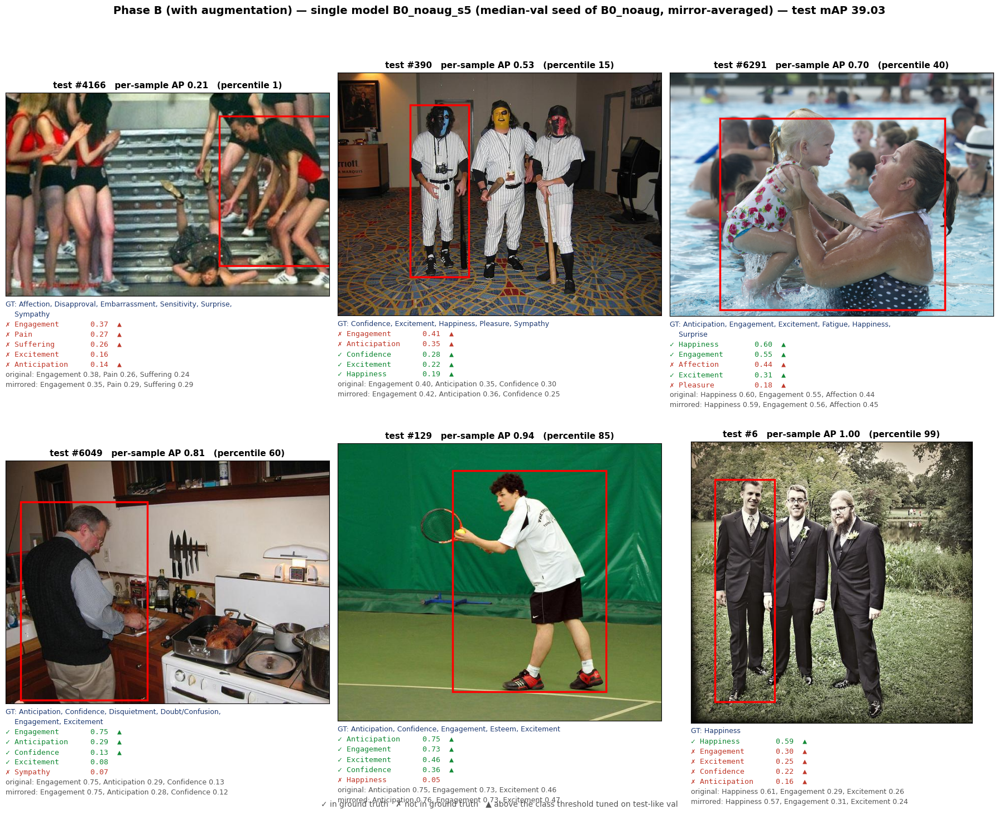

  ✓ 6 samples chosen by percentile rule                got 6, expected 6
  ✓ all 6 images loaded                                got 6, expected 6
  ✓ figure saved                                       got qualitative_B0_noaug_s5.png, expected png
  · median per-sample AP (test): 0.758
  · top-1 agreement original vs mirrored input (all test persons): 96.0%

10.2  SEED ENSEMBLE



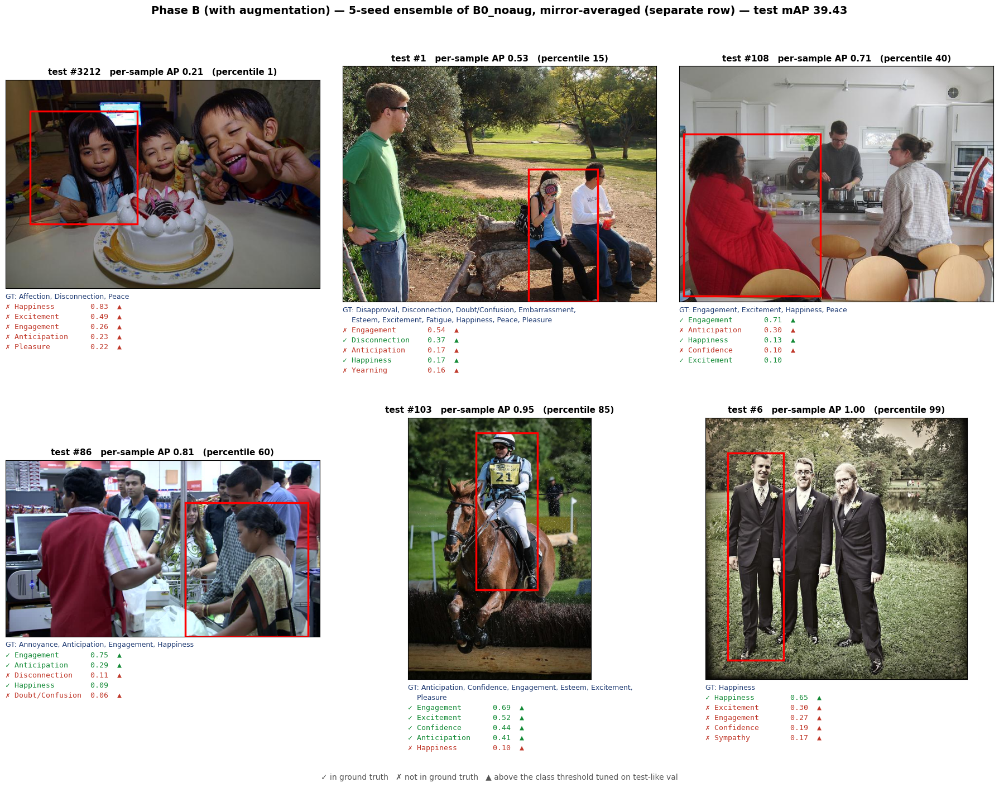

  ✓ ensemble figure saved                              got qualitative_ensemble.png, expected png

  Saved to /kaggle/working/figures/phaseB_augmentation
    augmentation_views.png
    index.json
    qualitative_B0_noaug_s5.csv
    qualitative_B0_noaug_s5.png
    qualitative_ensemble.csv
    qualitative_ensemble.png

════════════════════════════════════════════════════════════════════════════
  10.9  VERDICT
════════════════════════════════════════════════════════════════════════════

  ✓ 6 samples chosen by percentile rule
  ✓ all 6 images loaded
  ✓ figure saved
  ✓ ensemble figure saved

████████████████████████████████████████████████████████████████████████████
█  BLOCK 10: ALL 4 CHECKS PASSED                                           █
████████████████████████████████████████████████████████████████████████████
────────────────────────────────────────────────────────────────────────────
  VERDICT SUMMARY   1:PASS  2:PASS  3:PASS  4:PASS  5:PASS  6:PASS  7:PASS  8:PASS  9:PASS  10

In [10]:
# Block 10 — Qualitative Results: 6 Test Samples (Phase B: WITH augmentation)
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Block 09 in this session
#
# Models shown (fixed by Block 09's pre-declared rule, not by test results):
#   * the final configuration's MEDIAN-VAL seed (a single model), in the
#     inference mode chosen on validation (original view or mirror-averaged);
#   * the final configuration's seed ensemble (a separate row in Block 09).
#
# Six test persons per model, chosen by rule, not by eye: the persons whose
# per-sample AP sits at the 1st, 15th, 40th, 60th, 85th and 99th percentile of
# the model's test distribution — from clear failures to clear successes.
# Shown live below and saved to /kaggle/working/figures/phaseB_augmentation/.
#
# In each panel: the image with the person's red box, the ground-truth labels
# (3-annotator union), the model's top-5 emotions with probabilities
# (green ✓ = in the ground truth, red ✗ = not), and — for the single model —
# the top-3 of the original and of the mirrored input separately, so the effect
# of mirror averaging is visible per person.
# ══════════════════════════════════════════════════════════════════════════════

import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

header("BLOCK 10 — Qualitative Results: 6 Test Samples (Phase B, with augmentation)  [Phase B]")
V = BlockVerdict(10, "Qualitative")
QUAL_DIR = CFG.figures_dir
QUAL_DIR.mkdir(parents=True, exist_ok=True)
QUANTILES = [1, 15, 40, 60, 85, 99]


def per_sample_ap(scores, labels):
    out = np.full(len(labels), np.nan)
    for i in range(len(labels)):
        y = labels[i]
        if y.sum() == 0:
            continue
        o = np.argsort(-scores[i], kind="mergesort")
        hit = y[o]
        ranks = np.arange(1, len(o) + 1)
        out[i] = float(((np.cumsum(hit) / ranks) * hit).sum() / hit.sum())
    return out


def pick(ap):
    chosen = []
    for q in QUANTILES:
        target = np.nanpercentile(ap, q)
        order = np.argsort(np.abs(np.nan_to_num(ap, nan=9.0) - target), kind="mergesort")
        i = next(int(j) for j in order if int(j) not in chosen)
        chosen.append(i)
    return chosen


def _top3(v):
    return ", ".join(f"{EMOTION_LABELS[c]} {v[c]:.2f}" for c in np.argsort(-v)[:3])


def panel(tag, title, scores, thresholds, views=None):
    """views: optional (original-view scores, mirror-view scores) shown under each panel."""
    ap = per_sample_ap(scores, TEST_LABELS)
    idx = pick(ap)
    fig, axes = plt.subplots(2, 3, figsize=(18, 14.5 if views is not None else 14))
    rows = []
    for k, (ax, i) in enumerate(zip(axes.flat, idx)):
        r = df_test.iloc[i]
        try:
            img = Image.open(r.img_path).convert("RGB")
            ok = True
        except Exception:
            img, ok = Image.new("RGB", (320, 240), (128, 128, 128)), False
        W, H = img.size
        s = min(1.0, 900.0 / max(W, H))
        if s < 1.0:
            img = img.resize((max(1, int(W * s)), max(1, int(H * s))))
        ax.imshow(img)
        ax.add_patch(mpatches.Rectangle((r.xmin * s, r.ymin * s), (r.xmax - r.xmin) * s, (r.ymax - r.ymin) * s,
                                        fill=False, edgecolor="red", linewidth=2.5))
        ax.set_xticks([]); ax.set_yticks([])
        gt = [EMOTION_LABELS[c] for c in np.where(TEST_LABELS[i] > 0)[0]]
        top = np.argsort(-scores[i])[:5]
        ax.set_title(f"test #{i}   per-sample AP {ap[i]:.2f}   (percentile {QUANTILES[k]})",
                     fontsize=11, fontweight="bold")
        # captions in points below the image, so spacing is identical for every aspect ratio
        lines = [(("GT: " if j == 0 else "    ") + l, "#1f3b73", False)
                 for j, l in enumerate(textwrap.wrap(", ".join(gt), 62))] or [("GT: -", "#1f3b73", False)]
        for c in top:
            good = TEST_LABELS[i, c] > 0
            lines.append((f"{'✓' if good else '✗'} {EMOTION_LABELS[c]:<16s} {scores[i, c]:.2f}"
                          + ("  ▲" if scores[i, c] >= thresholds[c] else ""),
                          "#138a36" if good else "#c0392b", True))
        if views is not None:
            lines.append(("original: " + _top3(views[0][i]), "#555555", False))
            lines.append(("mirrored: " + _top3(views[1][i]), "#555555", False))
        for j, (txt, col, mono) in enumerate(lines):
            ax.annotate(txt, xy=(0, 0), xycoords="axes fraction", xytext=(0, -6 - 13 * j),
                        textcoords="offset points", fontsize=9.5 if mono else 9.0, va="top", ha="left", color=col,
                        family="DejaVu Sans Mono" if mono else None)
        row = {"model": tag, "percentile": QUANTILES[k], "test_index": i, "image": str(r.img_path),
               "box": [int(r.xmin), int(r.ymin), int(r.xmax), int(r.ymax)], "sample_AP": float(ap[i]),
               "ground_truth": gt, "top5": [(EMOTION_LABELS[c], round(float(scores[i, c]), 4)) for c in top],
               "image_loaded": ok}
        if views is not None:
            row["top3_original_view"] = _top3(views[0][i])
            row["top3_mirror_view"] = _top3(views[1][i])
        rows.append(row)
    fig.suptitle(title, fontsize=14, fontweight="bold", y=0.995)
    fig.text(0.5, 0.005, "✓ in ground truth   ✗ not in ground truth   ▲ above the class threshold tuned on "
             "test-like val", ha="center", fontsize=10, color="#555555")
    fig.tight_layout(rect=(0, 0.03, 1, 0.97), h_pad=11.0 if views is not None else 9.0)
    png = QUAL_DIR / f"qualitative_{tag}.png"
    fig.savefig(png, dpi=110, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    pd.DataFrame(rows).to_csv(QUAL_DIR / f"qualitative_{tag}.csv", index=False)
    return png, rows, ap


# ──────────────────────────────────────────────────────────────────────────────
# 10.1  SINGLE MODEL (final configuration, median-val seed, chosen inference mode)
# ──────────────────────────────────────────────────────────────────────────────
print(f"10.1  SINGLE MODEL ({WINNER}, median-val seed, {MODE_LABEL[FINAL_MODE]})\n")
_views = (SCORES[HEADLINE_RUN]["test_scores"], SCORES[HEADLINE_RUN]["test_scores_flip"])
_png, _rows, _ap = panel(HEADLINE_RUN, f"Phase B (with augmentation) — single model {HEADLINE_RUN} (median-val seed "
                                       f"of {WINNER}, {MODE_LABEL[FINAL_MODE]}) — test mAP {HEADLINE_MAP:.2f}",
                         HEADLINE_TEST_SCORES, np.asarray(HEADLINE_THRESHOLDS, np.float32), views=_views)
V.check("6 samples chosen by percentile rule", len(_rows) == 6 and len({r["test_index"] for r in _rows}) == 6,
        len(_rows), 6)
V.check("all 6 images loaded", all(r["image_loaded"] for r in _rows), sum(r["image_loaded"] for r in _rows), 6)
V.check("figure saved", _png.exists(), _png.name, "png")
V.note("median per-sample AP (test)", f"{np.nanmedian(_ap):.3f}")
_agree = float(np.mean(np.argmax(_views[0], 1) == np.argmax(_views[1], 1)))
V.note("top-1 agreement original vs mirrored input (all test persons)", f"{100 * _agree:.1f}%")
QUAL_OUT = {"single": [str(_png)]}

# ──────────────────────────────────────────────────────────────────────────────
# 10.2  SEED ENSEMBLE (separate row of Block 09)
# ──────────────────────────────────────────────────────────────────────────────
print("\n10.2  SEED ENSEMBLE\n")
if ENSEMBLE_TEST_SCORES is not None and len(ENSEMBLE_RUNS) >= 2:
    _png2, _rows2, _ = panel("ensemble", f"Phase B (with augmentation) — {len(ENSEMBLE_RUNS)}-seed ensemble of "
                                         f"{WINNER}, {MODE_LABEL[FINAL_MODE]} (separate row) — test mAP "
                                         f"{ENSEMBLE_MAP:.2f}", ENSEMBLE_TEST_SCORES,
                             np.asarray(ENSEMBLE_THRESHOLDS, np.float32))
    V.check("ensemble figure saved", _png2.exists(), _png2.name, "png")
    QUAL_OUT["ensemble"] = [str(_png2)]
else:
    V.note("ensemble", "not available (fewer than 2 finished seeds)")

core.write_json(QUAL_DIR / "index.json", {"phase": "B_augmentation", "figures": QUAL_OUT, "percentiles": QUANTILES,
                                          "headline": HEADLINE_RUN, "mode": FINAL_MODE,
                                          "audit_figure": str(QUAL_DIR / "augmentation_views.png")})
print(f"\n  {_B}Saved to {QUAL_DIR}{_0}")
for _f in sorted(QUAL_DIR.glob("*")):
    print(f"    {_f.name}")
BLOCK_10_OK = V.finish()